# FINAL FULL-RUN NOTEBOOK — Leakage-Aware Adaptive Defense Against Property Inference in VFL

**This notebook uses the real six datasets attached in Kaggle Input. It does not generate synthetic datasets and does not use smoke-test settings.** It runs the main VFL experiments, controller variants, population-level attacks, reviewer mechanism proxies, held-out calibration audits, statistics, figures, and output packaging.

## Required datasets
Attach one Kaggle Dataset containing the original files listed in the next cell: Adult, Bank Marketing, Census-Income KDD, Diabetes 130-US Hospitals, Lawschool admissions, and CelebA (image zip + attribute CSV). The notebook stops before training if any required dataset is missing or malformed; it will not silently continue with a partial dataset list.

## Run order
1. In Kaggle, enable GPU and attach the real dataset bundle.
2. Run **all cells from top to bottom once**. Do not skip the data-preflight or final packaging cells.
3. The full run uses 10 seeds and 30 epochs. Reviewer mechanism baselines are enabled, so this is computationally expensive. The notebook saves intermediate CSV/checkpoint files and can resume cached main experiments after a Kaggle restart.
4. Download `/kaggle/working/reviewer_final_outputs.zip` (or the exact output path printed by the final cell). These are the new outputs from this run; no prefilled result numbers are embedded in this notebook.

**Scientific scope:** the randomized-response, row-shuffling, and withdrawal mechanisms are explicitly labelled representation-level proxies, not exact reproductions of named SOTA systems or formal differential-privacy guarantees. The ProVFL-style item is an attack baseline, not a defense. Do not describe these proxies as exact SOTA reproductions in the paper.


## Data layout (private Kaggle dataset)

Download the original files (links below), unzip them, and upload them to **one** private Kaggle dataset, for example:

```
raad-datasets/
├── adult/        adult.csv                  (Kaggle: uciml/adult-census-income, header + 15 columns)
├── bank/         bank-full.csv              (UCI Bank Marketing, ';' separated, 45,211 rows)
├── census/       census-income.data         (UCI Census-Income KDD, header-less, + census-income.test)
├── health/       diabetic_data.csv          (Diabetes 130-US Hospitals, 1999-2008; ~101k rows, '?' = missing)
├── lawschool/    bar_pass_prediction.csv    (Kaggle: danofer/law-school-admissions-bar-passage)
└── celeba/       img_align_celeba.zip  +  list_attr_celeba.csv      (Kaggle: jessicali9530/celeba-dataset; the image zip is read directly, it is never extracted)
```

The notebook searches `/kaggle/input` recursively, unpacks supported non-CelebA archives, and prints the discovered files. It requires all six datasets and aborts if one is missing. The Census table uses a deterministic seeded subset capped at 50,000 rows for compute feasibility; CelebA uses a fixed-seed 20,000-image subset. These are real records/images from the original datasets, not synthetic data. Report these sampling choices in the paper.

**Download links**
* Adult — https://www.kaggle.com/datasets/uciml/adult-census-income  (original: https://archive.ics.uci.edu/dataset/2/adult)
* Bank Marketing — https://archive.ics.uci.edu/dataset/222/bank+marketing  (zip: https://archive.ics.uci.edu/static/public/222/bank+marketing.zip; take `bank-full.csv` from the inner `bank.zip`)
* Census-Income (KDD) — https://archive.ics.uci.edu/dataset/117/census+income+kdd  (`census.tar.gz`, contains `census-income.data` and `census-income.test`)
* Lawschool — https://www.kaggle.com/datasets/danofer/law-school-admissions-bar-passage  (file `bar_pass_prediction.csv`)
* Health (Diabetes 130-US Hospitals) — https://archive.ics.uci.edu/dataset/296/diabetes-130-us-hospitals-for-years-1999-2008  (UCI zip contains `diabetic_data.csv`; Kaggle copy: https://www.kaggle.com/brandao/diabetes). Task label: readmitted (any readmission); target property: age ≥ 60. Cite: Strack et al. (2014), UCI repository.
* CelebA — https://www.kaggle.com/datasets/jessicali9530/celeba-dataset  (`img_align_celeba.zip` + `list_attr_celeba.csv`). **Image-based VFL**: party A holds the LEFT half and party B the RIGHT half of each face image (center crop 148×148 → 64×64), bottom models are small CNNs, task label = `Smiling`, target property = `Male`. A fixed random subset of `CELEBA_N` images is used. Set `CELEBA_MODE = "attributes"` in Cell 2 to use only the attribute CSV as a tabular dataset instead. Cite: Liu et al., *Deep Learning Face Attributes in the Wild*, ICCV 2015.

In [1]:
# ============================================================
# CELL 2 — CONFIGURATION
# [PAPER]  = value fixed by the paper text
# [CHOICE] = value the paper leaves open (the draft shows "XX" or "Section ??"); state it in the paper
# ============================================================
import os
from pathlib import Path

SMOKE_TEST = False                # LOCKED: this final notebook only runs full experiments; smoke mode is not supported.
assert SMOKE_TEST is False, "Smoke-test mode is disabled in the final notebook."
KAGGLE_INPUT = Path(os.environ.get("RAAD_INPUT", "/kaggle/input"))
WORK = Path(os.environ.get("RAAD_WORK", "/kaggle/working/raad_pia_vfl_final_actualdata"))
RUN_TAG = "reviewer_v3_reviewer_complete"               # a NEW tag (e.g. "v4_tuned") writes everything to a NEW folder -> a completely fresh run; "paper_v1" keeps the old folder

TARGET_ACC = 0.956                 # ONLY used to report the accuracy gap (Cell 31b); never used for training, tuning or model selection
RUN_CONTROLLER_V2 = True           # extra adaptive variants: adaptive_margin (target tau - LOSO error of the risk estimator) and adaptive_multiepoch (calibration on all snapshot epochs)
SAVE_CHECKPOINTS = True            # save model state_dicts of every run to WORK/checkpoints
HP_OVERRIDE = {}                   # per-dataset hyper-parameters found by the validation-only tuning cell (Cell 16b): {"bank": {"learning_rate": 0.003, ...}}
ENABLED_DATASETS = ["adult", "bank", "census", "health", "lawschool", "celeba"]   # [PAPER] six datasets: 5 tabular + CelebA
SEEDS = list(range(10))            # [PAPER] mean/std over 10 runs with different seeds
EPOCHS = 30                        # [CHOICE] paper: "XX epochs"
MAX_ROWS = 50000                   # [CHOICE] fixed random subsample per dataset (Census-KDD has ~300k rows)
PROPERTY_IN_FEATURES = False       # [CHOICE] False: the property column itself is removed from the features (leakage via proxies only)
                                   #          True : the property column stays among the features (direct leakage, much stronger)
CELEBA_MODE = "image"              # "image": party A/B = left/right half of the face image (CNN bottom models, needs the image zip + list_attr_celeba.csv)
                                   # "attributes": uses only list_attr_celeba.csv as a tabular table (38 attributes split between the parties)
CELEBA_N = 20000                   # [CHOICE] number of CelebA images used (random, fixed subsample); label = Smiling, property = Male
CELEBA_IMG = 64                    # [CHOICE] images are center-cropped and resized to CELEBA_IMG x CELEBA_IMG; party A = left half, party B = right half
RUN_ABLATION_NO_HYST = True        # extra run per seed: adaptive controller with h = 0 (shows what the hysteresis band buys)
RUN_PILOT = False                  # no separate pilot phase; the full run itself records all calibration points
FORCE_RERUN_ADAPTIVE = False       # True: recompute adaptive runs even if result files exist (e.g. after changing tau/eta/beta)

CFG = {
    # --- models / training  [CHOICE]
    "embedding_dim": 32,           # d
    "server_hidden": 64,
    "batch_size": 256,
    "optimizer": "Adam",
    "learning_rate": 1e-3,
    "weight_decay": 1e-5,
    # --- defense layer, Eq. (4)  [PAPER]
    "clip_norm": 1.0,              # C = 1
    "sigma_min": 0.0,
    "sigma_max": 0.30,             # defense strength lies in [0, 0.30]
    "fixed_sigmas": [0.05, 0.10, 0.20, 0.30],             # fixed-strength baselines
    "calibration_sigmas": [0.0, 0.05, 0.10, 0.20, 0.30],  # Sigma_cal, n_sigma = 5 (= clip-only + the four fixed models)
    # --- splits  [PAPER]  60 / 10 / 10 / 20
    "split": {"train": 0.60, "sim": 0.10, "ref": 0.10, "test": 0.20},
    # --- leakage monitor, Eq. (13)-(14)  [PAPER]
    "monitor": {"bins": 30, "probe_train_frac": 0.70,
                "weights": {"jsd": 0.35, "wasserstein": 0.25, "smd": 0.15, "probe": 0.25},
                "jsd_normalize_ln2": False},   # False = clip J to [0,1] exactly as written in the paper (J<=ln2 for natural log)
    # --- controller  [CHOICE] (Section V of the draft is empty: state these values there)
    "controller": {"budget": 0.30,     # tau: leakage budget on the risk R = 2(AUC-0.5); tau=0.30 <-> AUC 0.65
                   "hysteresis": 0.05, # h
                   "eta": 0.15,        # proportional gain
                   "beta": 0.70,       # EMA smoothing of the estimated risk
                   "initial_sigma": 0.05},
    "tau_override": {},               # common pre-specified leakage budget tau=0.30 for all datasets; no post-hoc per-dataset tuning
    # --- auxiliary-data shift, Eq. (10)  [PAPER]
    "shifts": {"matched": 0.0, "moderate": 0.3, "severe": 0.6},
    # --- prevalence attack  [PAPER: batches of 64, ridge on norm statistics]  [CHOICE: the rest]
    "prev_attack": {"batch_size": 64, "n_train_batches": 600, "n_test_batches": 400,
                    "spread": 0.25,    # batch prevalences are drawn in [q-spread, q+spread] (train) / [rho-spread, rho+spread] (test)
                    "ridge_alpha": 1.0},
    "strong_attacker_conditions": ["matched"],   # gradient-boosting attacker (paper, limitations paragraph); add "moderate","severe" for all
    "snapshot_epochs": [1, 5, 10, 20, 30],       # epochs at which fixed runs record leakage (Observation 3)
    "calibration_mode": "final",       # "final": kappa/R at the END of training (paper). "multi_epoch": all snapshots (extension)
    "track_true_risk": True,           # adaptive runs also log the simulated-attacker risk each epoch (diagnostic only, never used by the controller)
}

if RUN_TAG != "paper_v1":
    WORK = WORK.parent / (WORK.name + "_" + RUN_TAG)
CFG["snapshot_epochs"] = sorted({e for e in CFG["snapshot_epochs"] if e <= EPOCHS} | {EPOCHS})
CFG["epochs"] = EPOCHS
SHIFT_CONDITIONS = list(CFG["shifts"].keys())
assert sorted(CFG["calibration_sigmas"]) == sorted([0.0] + CFG["fixed_sigmas"]), "Sigma_cal must equal clip-only + fixed sigmas"

def tau_for(dataset):
    return float(CFG["tau_override"].get(dataset, CFG["controller"]["budget"]))

for sub in ["tables", "logs", "risk", "figures", "latex", "checkpoints"]:
    (WORK / sub).mkdir(parents=True, exist_ok=True)

print("FULL RUN ONLY | SEEDS:", len(SEEDS), "| EPOCHS:", EPOCHS, "| MAX_ROWS:", MAX_ROWS)
print("sigma in [%.2f, %.2f] | fixed:" % (CFG["sigma_min"], CFG["sigma_max"]), CFG["fixed_sigmas"], "| tau =", CFG["controller"]["budget"])
print("Outputs ->", WORK)

FULL RUN ONLY | SEEDS: 10 | EPOCHS: 30 | MAX_ROWS: 50000
sigma in [0.00, 0.30] | fixed: [0.05, 0.1, 0.2, 0.3] | tau = 0.3
Outputs -> /kaggle/working/raad_pia_vfl_final_actualdata_reviewer_v3_reviewer_complete


In [2]:
# ============================================================
# CELL 3 — IMPORTS
# ============================================================
import os, sys, json, math, random, time, re, traceback, zipfile, tarfile, shutil, hashlib
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.isotonic import IsotonicRegression
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, mean_absolute_error
from scipy.stats import wasserstein_distance, spearmanr, kendalltau, wilcoxon

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

try:
    display
except NameError:                      # outside Jupyter
    def display(x): print(x)
print("Imports ready.")

Imports ready.


In [3]:
# ============================================================
# CELL 4 — TORCH SETUP (device + seeding)
# ============================================================
import torch
import torch.nn as nn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", DEVICE)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

PyTorch: 2.11.0+cu128 | Device: cuda


In [4]:
# ============================================================
# CELL 5 — FAST FILE INDEX + UNPACK ARCHIVES + LIST WHAT IS IN /kaggle/input   (prints progress while it works)
# Folders with thousands of images (CelebA: ~200k .jpg) are only COUNTED, never listed or stat-ed one by one.
# The CelebA image zip is never extracted; images are read directly from it (or from the image folder if Kaggle already extracted it).
# ============================================================
import fnmatch
EXTRACT_DIR = WORK / "_extracted"
ARCHIVE_RE = re.compile(r"\.(zip|tar\.gz|tgz|tar)$", re.I)
IMG_EXT = (".jpg", ".jpeg", ".png")

def walk_files(root, max_listed_images=50, verbose=True):
    files, img_dirs = [], {}
    root = Path(root)
    if not root.exists():
        return files, img_dirs
    t0 = time.time()
    for dp, dn, fn in os.walk(root):
        imgs = {x for x in fn if x.lower().endswith(IMG_EXT)}
        if len(imgs) > max_listed_images:
            img_dirs[dp] = len(imgs); fn = [x for x in fn if x not in imgs]
        files.extend(Path(dp) / x for x in fn)
        if verbose:
            print(f"   [{time.time() - t0:5.0f}s] {dp[-70:]}: {len(fn)} files" + (f" + {len(imgs)} images (counted only)" if imgs else ""), flush=True)
    return files, img_dirs

print("1/3 indexing", KAGGLE_INPUT, "...", flush=True)
FILES_IN, IMG_IN = walk_files(KAGGLE_INPUT)

print("2/3 unpacking archives (CelebA image zip is skipped on purpose) ...", flush=True)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
def _extract_all(files):
    new = 0
    for f in files:
        n = f.name.lower()
        if not ARCHIVE_RE.search(n) or re.search(r"celeba|img_align", n):
            continue
        dest = EXTRACT_DIR / (hashlib.md5(str(f).encode()).hexdigest()[:8] + "_" + f.name.split(".")[0])
        if dest.exists():
            continue
        try:
            if n.endswith(".zip"):
                zipfile.ZipFile(f).extractall(dest)
            else:
                try: tarfile.open(f).extractall(dest, filter="data")
                except TypeError: tarfile.open(f).extractall(dest)
            new += 1; print("   extracted:", f, "->", dest, flush=True)
        except Exception as e:
            print("   could not extract", f, repr(e)[:100])
    return new
if _extract_all(FILES_IN):
    for _ in range(2):                                   # nested archives (e.g. bank.zip inside bank+marketing.zip)
        if not _extract_all(walk_files(EXTRACT_DIR, verbose=False)[0]):
            break
FILES_EX, IMG_EX = walk_files(EXTRACT_DIR, verbose=False)

SEARCH_ROOTS = [KAGGLE_INPUT, EXTRACT_DIR]
FILE_INDEX, IMAGE_DIRS = FILES_IN + FILES_EX, {**IMG_IN, **IMG_EX}

print("\n3/3 Files visible to the notebook (first 80, images are only counted):")
for f in sorted(FILE_INDEX)[:80]:
    print("  %-95s %9.1f KB" % (str(f)[-95:], f.stat().st_size / 1024))
for dp, cnt in IMAGE_DIRS.items():
    print("  [image folder] %s : %d images" % (dp[-80:], cnt))
if not FILE_INDEX and not IMAGE_DIRS:
    print("  (nothing found: attach your private dataset via 'Add Input')")

1/3 indexing /kaggle/input ...
   [    0s] /kaggle/input: 0 files
   [    0s] /kaggle/input/datasets: 0 files
   [    0s] /kaggle/input/datasets/zukhrafkhan: 0 files
   [    0s] /kaggle/input/datasets/zukhrafkhan/celeba-claude: 1 files
   [    0s] /kaggle/input/datasets/zukhrafkhan/celeba-claude/celebA: 4 files
   [    0s] aggle/input/datasets/zukhrafkhan/celeba-claude/celebA/img_align_celeba: 0 files
   [   15s] ets/zukhrafkhan/celeba-claude/celebA/img_align_celeba/img_align_celeba: 0 files + 202599 images (counted only)
   [   15s] /kaggle/input/datasets/zukhrafkhan/5-datasets: 0 files
   [   15s] /kaggle/input/datasets/zukhrafkhan/5-datasets/adult: 1 files
   [   15s] /kaggle/input/datasets/zukhrafkhan/5-datasets/bankmarketing: 0 files
   [   15s] /kaggle/input/datasets/zukhrafkhan/5-datasets/bankmarketing/bank: 3 files
   [   15s] le/input/datasets/zukhrafkhan/5-datasets/bankmarketing/bank-additional: 0 files
   [   15s] s/zukhrafkhan/5-datasets/bankmarketing/bank-additional/bank-a

In [5]:
# ============================================================
# CELL 6 — DATASET SPECIFICATIONS  (task label + target property + files)
# ------------------------------------------------------------
# Paper (IV-C): features of each dataset are split into two halves (K=2), the task label is binary,
# the target property is a binary attribute with prevalence rho. The paper does NOT list the exact
# label/property per dataset (Table II shows XX) -> they are [CHOICE]s defined here. Edit if you prefer others.
# Rules: {"values":[...]} | {"startswith":"..."} | {"gt":x} | {"positive":True} | {"age_ge":60}
# "col" may be a list of candidate names (first one found is used; names are matched case/punctuation-insensitively).
# "property_aliases": other columns that are copies of the property -> removed from the features unless PROPERTY_IN_FEATURES.
# ============================================================
CENSUS_KDD_NAMES = [
    "age", "class of worker", "detailed industry recode", "detailed occupation recode", "education", "wage per hour",
    "enroll in edu inst last wk", "marital stat", "major industry code", "major occupation code", "race", "hispanic origin",
    "sex", "member of a labor union", "reason for unemployment", "full or part time employment stat", "capital gains",
    "capital losses", "dividends from stocks", "tax filer stat", "region of previous residence", "state of previous residence",
    "detailed household and family stat", "detailed household summary in household", "instance weight",
    "migration code-change in msa", "migration code-change in reg", "migration code-move within reg",
    "live in this house 1 year ago", "migration prev res in sunbelt", "num persons worked for employer",
    "family members under 18", "country of birth father", "country of birth mother", "country of birth self",
    "citizenship", "own business or self employed", "fill inc questionnaire for veteran's admin", "veterans benefits",
    "weeks worked in year", "year", "label"]

ADULT_NAMES = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status", "occupation", "relationship",
               "race", "sex", "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]

DATASETS = {
    "adult": {
        "files": ["adult.csv", "adult.data", "*adult*.csv"], "names": ADULT_NAMES,
        "label": {"col": ["income", "class"], "values": [">50k", "1", "yes"]},
        "property": {"col": ["sex", "gender"], "values": ["female"]},
        "property_aliases": ["sex", "gender"],
        "drop": ["fnlwgt"],
    },
    "bank": {
        "files": ["bank-full.csv", "bank-additional-full.csv", "bank*.csv", "*bank*marketing*.csv"],
        "label": {"col": ["y", "deposit", "subscribed"], "values": ["yes", "1"]},
        "property": {"col": ["marital"], "values": ["married"]},
        "property_aliases": ["marital"],
        "drop": ["duration"],            # only known after the call -> label leakage
    },
    "census": {                           # UCI Census-Income (KDD); also works with a headered Kaggle CSV copy
        "files": ["census-income.data", "census-income*.data", "census*.csv", "*census*income*.csv"],
        "extra": ["census-income.test"], "names": CENSUS_KDD_NAMES,
        "label": {"col": ["label", "income"], "values": ["50000+", ">50k", "1", "yes"]},
        "property": {"col": ["sex", "gender"], "values": ["female"]},
        "property_aliases": ["sex", "gender"],
        "drop": ["instance weight", "instanceweight"],
    },
    "health": {                           # Diabetes 130-US Hospitals (1999-2008): label = readmitted (any), property = age >= 60
        "files": ["diabetic_data.csv", "*diabetic*data*.csv", "*diabetes*130*.csv", "health*.csv", "*health*.csv"],
        "label": {"col": ["readmitted"], "values": ["<30", ">30"]},          # use ["<30"] for early readmission only (~11% positives)
        "property": {"col": ["age"], "age_ge": 60},                          # age brackets like [60-70) -> 60
        "property_aliases": ["age"],
        "dedupe": "patient_nbr",                                             # keep the first encounter of each patient
        "drop": ["encounter_id", "patient_nbr", "weight"],                   # IDs; weight is ~97% missing
    },
    "lawschool": {                        # LSAC bar passage: label = pass_bar, property = male
        "files": ["bar_pass_prediction.csv", "*bar*pass*.csv", "law*.csv", "*law*school*.csv", "*lsac*.csv"],
        "label": {"col": ["pass_bar", "passbar"], "values": ["1", "yes", "passed", "true"]},
        "property": {"col": ["male", "gender", "sex"], "values": ["1", "male", "m", "true"]},
        "property_aliases": ["male", "gender", "sex"],
        "drop": [],
        "drop_regex": [r"^(bar|pass|dnn)"],   # bar outcomes / model predictions are label leakage
    },
    "celeba_attr": {                      # used only when CELEBA_MODE == "attributes" (CelebA attribute table, no images)
        "files": ["list_attr_celeba.csv", "*attr*celeba*.csv", "*celeba*attr*.csv"],
        "label": {"col": ["Smiling"], "values": ["1"]},
        "property": {"col": ["Male"], "values": ["1"]},
        "property_aliases": ["Male"],
        "drop": ["image_id"],
    },
    "celeba": {                           # CelebA: party A = left half of the face image, party B = right half
        "kind": "celeba",
        "attr_files": ["list_attr_celeba.csv", "list_attr_celeba*.csv", "*list_attr*celeba*.csv"],
        "label": {"col": ["Smiling"], "values": ["1"]},       # attribute values are +1 / -1
        "property": {"col": ["Male"], "values": ["1"]},
    },
}
GLOBAL_DROP_REGEX = [r"^unnamed", r"^index$", r"^id$"]
print("Specs defined for:", list(DATASETS))

Specs defined for: ['adult', 'bank', 'census', 'health', 'lawschool', 'celeba_attr', 'celeba']


In [6]:
# ============================================================
# CELL 7 — DATA UTILITIES: file discovery, binary rules, 2-party split, 60/10/10/20 split, featurization
# ============================================================
TABLE_SUFFIX = {".csv", ".data", ".txt", ".tsv", ".test"}

def _norm_name(x):
    return re.sub(r"[^a-z0-9]", "", str(x).strip().lower())

def _norm_val(v):
    try:
        f = float(v)
        return str(int(f)) if f == int(f) else str(f)
    except (TypeError, ValueError, OverflowError):
        return str(v).strip().lower().rstrip(".")

def _first_number(v):
    m = re.search(r"\d+(\.\d+)?", str(v))
    return float(m.group()) if m else np.nan

def find_file(spec_or_patterns):
    pats = spec_or_patterns["files"] if isinstance(spec_or_patterns, dict) else spec_or_patterns
    for pat in pats:
        hits = [h for h in FILE_INDEX if fnmatch.fnmatchcase(h.name, pat) and h.suffix.lower() in TABLE_SUFFIX]
        if hits:
            return max(hits, key=lambda h: h.stat().st_size)
    return None

def read_table(path, spec):
    names = spec.get("names")
    if names is not None and path.suffix.lower() in (".data", ".test"):     # header-less UCI files
        df = pd.read_csv(path, header=None, names=names, skipinitialspace=True, low_memory=False)
    else:
        with open(path, "r", errors="ignore") as fh:
            head = fh.readline()
        sep = ";" if head.count(";") > head.count(",") else ("\t" if head.count("\t") > head.count(",") else ",")
        df = pd.read_csv(path, sep=sep, skipinitialspace=True, low_memory=False)
    df.columns = [str(c).strip() for c in df.columns]
    return df

def resolve_col(df, cand):
    cands = [cand] if isinstance(cand, str) else list(cand)
    for c in cands:
        if c in df.columns:
            return c
    norm = {_norm_name(c): c for c in df.columns}
    for c in cands:
        if _norm_name(c) in norm:
            return norm[_norm_name(c)]
    raise KeyError(f"none of {cands} found; available columns: {list(df.columns)[:60]}")

def binary_rule(s, rule):
    miss = s.isna().to_numpy().copy()
    if "values" in rule:
        vals = {_norm_val(v) for v in rule["values"]}
        out = s.map(lambda v: int(_norm_val(v) in vals)).to_numpy()
    elif "startswith" in rule:
        pre = rule["startswith"].lower()
        out = s.map(lambda v: int(str(v).strip().lower().startswith(pre))).to_numpy()
    elif "gt" in rule:
        num = pd.to_numeric(s, errors="coerce"); miss |= num.isna().to_numpy()
        out = (num > rule["gt"]).astype(int).to_numpy()
    elif "positive" in rule:
        num = pd.to_numeric(s, errors="coerce"); isnum = num.notna().to_numpy()
        txt = s.astype(str).str.strip().str.lower()
        neg = {"0", "0.0", "no", "false", "none", "", "n", "-"}
        out = np.where(isnum, (num.fillna(0) > 0).to_numpy().astype(int), (~txt.isin(neg)).to_numpy().astype(int))
    elif "age_ge" in rule:
        ages = s.map(_first_number); miss |= ages.isna().to_numpy()
        out = (ages >= rule["age_ge"]).astype(int).to_numpy()
    else:
        raise ValueError("rule needs one of: values / startswith / gt / positive / age_ge")
    out = np.asarray(out).astype(int); out[miss] = -1
    return out

def _celeba_image_source():
    """Returns ("dir", folder) or ("zip", (ZipFile, {basename: member})). Images are read lazily, nothing is extracted."""
    for dp, cnt in sorted(IMAGE_DIRS.items(), key=lambda kv: -kv[1]):
        if (Path(dp) / "000001.jpg").exists():
            return "dir", Path(dp)
    zips = [z for z in FILE_INDEX if z.suffix.lower() == ".zip" and re.search(r"celeba|img_align", z.name.lower())]
    for z in sorted(zips, key=lambda p: -p.stat().st_size):
        zf = zipfile.ZipFile(z)
        names = {os.path.basename(n): n for n in zf.namelist() if n.lower().endswith((".jpg", ".jpeg"))}
        if names:
            return "zip", (zf, names)
    return None, None

def load_celeba(name, spec):
    from io import BytesIO
    from PIL import Image
    path = find_file(spec["attr_files"])
    if path is None:
        raise FileNotFoundError("CelebA: list_attr_celeba.csv not found (add it to the input dataset)")
    attr = pd.read_csv(path)
    attr.columns = [str(c).strip() for c in attr.columns]
    id_col = resolve_col(attr, ["image_id", "filename", "image"])
    lab_col, prop_col = resolve_col(attr, spec["label"]["col"]), resolve_col(attr, spec["property"]["col"])
    n_raw = len(attr)
    sel = np.sort(np.random.default_rng(0).choice(n_raw, min(CELEBA_N, n_raw), replace=False))
    attr = attr.iloc[sel].reset_index(drop=True)
    kind, src = _celeba_image_source()
    if kind is None:
        raise FileNotFoundError("CelebA: image folder/zip not found (expected img_align_celeba.zip or a folder with 000001.jpg ...)")
    cache = WORK / f"celeba_cache_N{len(attr)}_S{CELEBA_IMG}.npy"
    ids = attr[id_col].astype(str).tolist()
    if cache.exists():
        arr = np.load(cache)
    else:
        S = CELEBA_IMG; arr = np.zeros((len(ids), 3, S, S), dtype=np.uint8); ok = np.ones(len(ids), dtype=bool)
        for i, fid in enumerate(ids):
            try:
                if kind == "dir":
                    im = Image.open(src / fid)
                else:
                    zf, names = src; im = Image.open(BytesIO(zf.read(names[os.path.basename(fid)])))
                im = im.convert("RGB").crop((15, 35, 163, 183)).resize((S, S), Image.BILINEAR)   # 148x148 face crop -> SxS
                arr[i] = np.asarray(im, dtype=np.uint8).transpose(2, 0, 1)
            except Exception:
                ok[i] = False
            if (i + 1) % 5000 == 0:
                print(f"   CelebA images loaded: {i + 1}/{len(ids)}", flush=True)
        if not ok.all():
            print("   CelebA: missing images dropped:", int((~ok).sum()))
        arr = np.where(ok[:, None, None, None], arr, 0).astype(np.uint8); np.save(cache, arr)
        pd.Series(ok).to_csv(WORK / "tables" / "celeba_image_ok_mask.csv", index=False)
    mask_f = WORK / "tables" / "celeba_image_ok_mask.csv"
    ok = pd.read_csv(mask_f).iloc[:, 0].astype(bool).to_numpy() if mask_f.exists() and len(pd.read_csv(mask_f)) == len(ids) else np.ones(len(ids), bool)
    y, p = binary_rule(attr[lab_col], spec["label"]), binary_rule(attr[prop_col], spec["property"])
    keep = ok & (y >= 0) & (p >= 0)
    arr, y, p = arr[keep], y[keep], p[keep]
    half = arr.shape[3] // 2
    imgA, imgB = np.ascontiguousarray(arr[:, :, :, :half]), np.ascontiguousarray(arr[:, :, :, half:])
    return {"name": name, "kind": "image", "df": None, "y": y, "p": p, "imgA": imgA, "imgB": imgB, "colsA": [], "colsB": [],
            "meta": {"file": str(path), "label_col": lab_col, "property_col": prop_col, "n_raw": int(n_raw), "n": int(len(y)),
                     "n_features_A": int(np.prod(imgA.shape[1:])), "n_features_B": int(np.prod(imgB.shape[1:])),
                     "label_prevalence": float(y.mean()), "property_prevalence": float(p.mean()), "dropped": []}}

def load_dataset(name):
    spec = DATASETS["celeba_attr"] if (name == "celeba" and CELEBA_MODE == "attributes") else DATASETS[name]
    if spec.get("kind") == "celeba":
        return load_celeba(name, spec)
    path = find_file(spec)
    if path is None:
        raise FileNotFoundError(f"{name}: no file matching {spec['files']} under {[str(r) for r in SEARCH_ROOTS]}")
    df = read_table(path, spec)
    for pat in spec.get("extra", []):
        ex = find_file([pat])
        if ex is not None and ex != path:
            df = pd.concat([df, read_table(ex, spec)], ignore_index=True)
    if spec.get("dedupe"):
        try: df = df.drop_duplicates(subset=resolve_col(df, spec["dedupe"]), keep="first").reset_index(drop=True)
        except KeyError: pass
    lab_col, prop_col = resolve_col(df, spec["label"]["col"]), resolve_col(df, spec["property"]["col"])
    y, p = binary_rule(df[lab_col], spec["label"]), binary_rule(df[prop_col], spec["property"])
    n_raw = len(df)
    keep = (y >= 0) & (p >= 0)
    df, y, p = df[keep].reset_index(drop=True), y[keep], p[keep]
    if len(df) > MAX_ROWS:
        sub = np.sort(np.random.default_rng(0).choice(len(df), MAX_ROWS, replace=False))
        df, y, p = df.iloc[sub].reset_index(drop=True), y[sub], p[sub]
    drop = {lab_col}
    if not PROPERTY_IN_FEATURES:
        drop.add(prop_col)
        for a in spec.get("property_aliases", []):
            try: drop.add(resolve_col(df, a))
            except KeyError: pass
    for d in spec.get("drop", []):
        try: drop.add(resolve_col(df, d))
        except KeyError: pass
    rx = [re.compile(r) for r in spec.get("drop_regex", []) + GLOBAL_DROP_REGEX]
    for c in df.columns:
        if any(r.search(_norm_name(c)) for r in rx):
            drop.add(c)
    feats = [c for c in df.columns if c not in drop and df[c].nunique(dropna=True) > 1]
    if len(feats) < 2:
        raise ValueError(f"{name}: need at least 2 usable feature columns for two parties")
    half = len(feats) // 2
    return {"name": name, "kind": "tabular", "df": df[feats].copy(), "y": y, "p": p, "colsA": feats[:half], "colsB": feats[half:],
            "meta": {"file": str(path), "label_col": lab_col, "property_col": prop_col, "n_raw": int(n_raw), "n": int(len(df)),
                     "n_features_A": half, "n_features_B": len(feats) - half,
                     "label_prevalence": float(y.mean()), "property_prevalence": float(p.mean()),
                     "dropped": sorted(map(str, drop))}}

def make_split(y, p, seed):
    """Random 60/10/10/20 split into train / D_sim / D_ref / test (stratified by label x property)."""
    s = CFG["split"]; idx = np.arange(len(y)); strat = (y * 2 + p).astype(int)
    def _split(a, test_size, st):
        try:
            return train_test_split(a, test_size=test_size, stratify=st, random_state=seed)
        except ValueError:
            return train_test_split(a, test_size=test_size, stratify=(None if st is None else p[a]), random_state=seed)
    tr, tmp = _split(idx, 1 - s["train"], strat)
    te, rest = _split(tmp, (s["sim"] + s["ref"]) / (s["sim"] + s["ref"] + s["test"]), strat[tmp])
    sim, ref = _split(rest, s["ref"] / (s["sim"] + s["ref"]), strat[rest])
    return {"train": tr, "sim": sim, "ref": ref, "test": te}

def featurize(data, split):
    """Imputers / scalers / encoders are fitted on the TRAIN split only; one feature block per party."""
    if data.get("kind") == "image":
        return {"xA": data["imgA"], "xB": data["imgB"]}          # uint8 images; scaling to [-1, 1] happens inside the model
    out = {}
    for key, cols in (("xA", data["colsA"]), ("xB", data["colsB"])):
        sub = data["df"][cols].copy()
        num = [c for c in cols if pd.api.types.is_numeric_dtype(sub[c])]
        cat = [c for c in cols if c not in num]
        for c in cat:
            sub[c] = sub[c].where(sub[c].notna(), "missing").astype(str)
        tfs = []
        if num:
            tfs.append(("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num))
        if cat:
            tfs.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False), cat))
        ct = ColumnTransformer(tfs).fit(sub.iloc[split["train"]])
        out[key] = np.asarray(ct.transform(sub), dtype=np.float32)
    return out

print("Data utilities ready.")

Data utilities ready.


In [8]:
# ============================================================
# CELL 8 — PREFLIGHT: load every dataset, print what was found (Table II values) and stop on problems
# ============================================================
READY, DATA_CACHE, PREFLIGHT_ROWS = [], {}, []
for name in ENABLED_DATASETS:
    print("=" * 90); print(name.upper())
    try:
        d = load_dataset(name); m = d["meta"]
        print("  file       :", m["file"])
        print("  rows       : raw %d -> used %d | features party A/B: %d / %d" % (m["n_raw"], m["n"], m["n_features_A"], m["n_features_B"]))
        print("  task label :", m["label_col"], "| prevalence = %.3f" % m["label_prevalence"])
        print("  property   :", m["property_col"], "| prevalence rho = %.3f" % m["property_prevalence"])
        print("  removed    :", m["dropped"][:12], "..." if len(m["dropped"]) > 12 else "")
        sp = make_split(d["y"], d["p"], 0)
        print("  split sizes:", {k: len(v) for k, v in sp.items()},
              "| property positives in sim/ref:", int(d["p"][sp["sim"]].sum()), "/", int(d["p"][sp["ref"]].sum()))
        warn = []
        if not (0.05 <= m["property_prevalence"] <= 0.95): warn.append("property very unbalanced")
        if not (0.02 <= m["label_prevalence"] <= 0.98): warn.append("task label very unbalanced (accuracy is then uninformative; look at F1/AUC)")
        if min(d["p"][sp["sim"]].sum(), d["p"][sp["ref"]].sum()) < 30: warn.append("fewer than 30 property positives in D_sim/D_ref")
        for w in warn: print("  WARNING:", w)
        READY.append(name); DATA_CACHE[name] = d; PREFLIGHT_ROWS.append({"dataset": name, **{k: v for k, v in m.items() if k != "dropped"}})
    except Exception as e:
        print("  FAILED:", repr(e)[:700])
        print("  -> fix the file patterns / column names for this dataset in CELL 6 and rerun CELLS 6-8.")
print("=" * 90); print("READY:", READY)
missing = sorted(set(ENABLED_DATASETS) - set(READY))
if missing:
    raise RuntimeError("FINAL RUN ABORTED: these required real datasets did not load: " + ", ".join(missing) + ". Attach the original files listed in the first two cells, fix any reported column/file issue, and rerun. Partial-dataset results are not accepted for the paper.")
if len(READY) != len(ENABLED_DATASETS):
    raise RuntimeError("FINAL RUN ABORTED: dataset preflight incomplete; refusing to train on a subset.")
print("STRICT PREFLIGHT PASSED: all six real datasets are loaded.")
pd.DataFrame(PREFLIGHT_ROWS).to_csv(WORK / "tables" / "preflight_datasets.csv", index=False)

ADULT
  file       : /kaggle/input/datasets/zukhrafkhan/5-datasets/adult/adult.csv
  rows       : raw 32561 -> used 32561 | features party A/B: 6 / 6
  task label : income | prevalence = 0.241
  property   : sex | prevalence rho = 0.331
  removed    : ['fnlwgt', 'income', 'sex'] 
  split sizes: {'train': 19536, 'sim': 3256, 'ref': 3257, 'test': 6512} | property positives in sim/ref: 1077 / 1078
BANK
  file       : /kaggle/input/datasets/zukhrafkhan/5-datasets/bankmarketing/bank/bank-full.csv
  rows       : raw 45211 -> used 45211 | features party A/B: 7 / 7
  task label : y | prevalence = 0.117
  property   : marital | prevalence rho = 0.602
  removed    : ['duration', 'marital', 'y'] 
  split sizes: {'train': 27126, 'sim': 4521, 'ref': 4522, 'test': 9042} | property positives in sim/ref: 2721 / 2722
CENSUS
  file       : /kaggle/input/datasets/zukhrafkhan/5-datasets/censusincomekdd/census/census-income.data
  rows       : raw 299285 -> used 50000 | features party A/B: 19 / 20
  task l

In [9]:
# ============================================================
# CELL 9 — TWO-PARTY VFL + DEFENSE LAYER   (paper III-A, III-B, Eqs. (1)-(4))
#   z_i^(k) = f_k(x_i^(k); theta_k)                          (1)  bottom MLP of party k
#   y_hat   = g(z~^(1), z~^(2); theta_g)                      (2)  top MLP, BCE loss                (3)
#   z-bar   = z * min(1, C/||z||_2),  z~ = z-bar + N(0, sigma^2 C^2 I)                              (4)
# no_defense = no clipping, no noise | clip_only = clipping with sigma = 0 | fixed sigma | adaptive sigma_t
# ============================================================
# Optional reviewer baselines. The default is the paper's clipping + Gaussian mechanism.
# These are representation-level operational proxies, NOT faithful reproductions of every
# named paper's protocol; describe them as such unless replaced by author-code implementations.
ACTIVE_DEFENSE_MECHANISM = "gaussian_noise"
ACTIVE_MECHANISM_PARAMS = {}

def clip_and_noise(z, clip_norm=1.0, sigma=0.0):
    if clip_norm is not None:
        norm = z.norm(p=2, dim=1, keepdim=True).clamp_min(1e-12)
        z = z * torch.clamp(clip_norm / norm, max=1.0)

    mechanism = globals().get("ACTIVE_DEFENSE_MECHANISM", "gaussian_noise")
    params = globals().get("ACTIVE_MECHANISM_PARAMS", {})
    if mechanism == "randomized_response":
        # Binary sign quantization followed by independent bit flips. This is a
        # transparent discrete-output proxy; it is not an epsilon-DP guarantee for the full VFL.
        p_flip = float(np.clip(params.get("p_flip", 0.10), 0.0, 0.5))
        bits = torch.where(z >= 0, torch.ones_like(z), -torch.ones_like(z))
        flips = torch.rand_like(z) < p_flip
        z = torch.where(flips, -bits, bits)
    elif mechanism == "row_shuffling":
        # Permute representation-to-example assignments inside the current batch.
        # This intentionally stresses task utility and tests distribution-level leakage.
        if z.shape[0] > 1:
            z = z[torch.randperm(z.shape[0], device=z.device)]
    elif mechanism == "sample_withdrawal":
        # Randomly suppress complete examples' representations (zero vector).
        keep_prob = float(np.clip(params.get("keep_prob", 0.90), 0.0, 1.0))
        keep = (torch.rand((z.shape[0], 1), device=z.device) < keep_prob).to(z.dtype)
        z = z * keep

    if sigma > 0:
        z = z + torch.randn_like(z) * (sigma * (clip_norm if clip_norm is not None else 1.0))
    return z

class BottomMLP(nn.Module):
    def __init__(self, in_dim, emb_dim):
        super().__init__()
        hidden = max(32, min(128, in_dim))
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Linear(hidden, emb_dim))
    def forward(self, x): return self.net(x)

class TopMLP(nn.Module):
    def __init__(self, emb_dim, hidden):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2 * emb_dim, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    def forward(self, z): return self.net(z).squeeze(-1)

class TorchVFL:
    """Interface used by the pipeline: fit_epoch(sigma, clip) / embed(idx, sigma, clip) / task_metrics(idx, sigma, clip)."""
    def __init__(self, ds, X, split, seed):
        emb = CFG["embedding_dim"]
        self.xa = torch.tensor(X["xA"], dtype=torch.float32, device=DEVICE)
        self.xb = torch.tensor(X["xB"], dtype=torch.float32, device=DEVICE)
        self.y = torch.tensor(ds["y"], dtype=torch.float32, device=DEVICE)
        self.train_idx = np.asarray(split["train"]); self.rs = np.random.RandomState(seed)
        self.botA = BottomMLP(X["xA"].shape[1], emb).to(DEVICE)
        self.botB = BottomMLP(X["xB"].shape[1], emb).to(DEVICE)
        self.top = TopMLP(emb, CFG["server_hidden"]).to(DEVICE)
        self.params = [q for m in (self.botA, self.botB, self.top) for q in m.parameters()]
        self.opt = torch.optim.Adam(self.params, lr=CFG["learning_rate"], weight_decay=CFG["weight_decay"])
        self.loss_fn = nn.BCEWithLogitsLoss()

    def state(self):
        return {"botA": self.botA.state_dict(), "botB": self.botB.state_dict(), "top": self.top.state_dict()}

    def _z(self, b, sigma, clip):
        z1 = clip_and_noise(self.botA(self.xa[b]), clip, sigma)
        z2 = clip_and_noise(self.botB(self.xb[b]), clip, sigma)
        return torch.cat([z1, z2], 1)

    def fit_epoch(self, sigma, clip):
        for m in (self.botA, self.botB, self.top): m.train()
        perm = self.rs.permutation(self.train_idx); losses = []; bs = CFG["batch_size"]
        for s in range(0, len(perm), bs):
            b = torch.as_tensor(perm[s:s + bs], dtype=torch.long, device=DEVICE)
            loss = self.loss_fn(self.top(self._z(b, sigma, clip)), self.y[b])
            self.opt.zero_grad(set_to_none=True); loss.backward()
            torch.nn.utils.clip_grad_norm_(self.params, 5.0); self.opt.step(); losses.append(loss.item())
        if torch.cuda.is_available(): torch.cuda.synchronize()
        return float(np.mean(losses))

    @torch.no_grad()
    def _batched(self, idx, sigma, clip, fn):
        for m in (self.botA, self.botB, self.top): m.eval()
        idx = np.asarray(idx); outs = []
        for s in range(0, len(idx), 4096):
            b = torch.as_tensor(idx[s:s + 4096], dtype=torch.long, device=DEVICE)
            outs.append(fn(self._z(b, sigma, clip)))
        return np.concatenate(outs)

    def embed(self, idx, sigma, clip):
        """Protected concatenated representation z~ = [z~^(1); z~^(2)] (this is what the adversary observes)."""
        return self._batched(idx, sigma, clip, lambda z: z.cpu().numpy())

    def task_metrics(self, idx, sigma, clip):
        prob = self._batched(idx, sigma, clip, lambda z: torch.sigmoid(self.top(z)).cpu().numpy())
        y = self.y[torch.as_tensor(np.asarray(idx), dtype=torch.long, device=DEVICE)].cpu().numpy().astype(int)
        pred = (prob >= 0.5).astype(int)
        return {"task_accuracy": float(accuracy_score(y, pred)), "task_f1": float(f1_score(y, pred, zero_division=0)),
                "task_auc": float(roc_auc_score(y, prob)) if len(np.unique(y)) > 1 else 0.5}

class ConvBottom(nn.Module):
    """Bottom model of one party for a half face image (3 x 64 x 32): 3 conv blocks + linear to the d-dim representation."""
    def __init__(self, emb_dim, h, w):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(128 * (h // 8) * (w // 8), emb_dim))
    def forward(self, x): return self.net(x)

class ImageVFL(TorchVFL):
    """Same protocol as TorchVFL (defense layer, top model, loss), but the bottom models are CNNs on the left / right image halves."""
    def __init__(self, ds, X, split, seed):
        emb = CFG["embedding_dim"]
        self.xa = torch.as_tensor(np.asarray(X["xA"]), device=DEVICE)       # uint8 (N, 3, H, W/2)
        self.xb = torch.as_tensor(np.asarray(X["xB"]), device=DEVICE)
        self.y = torch.tensor(ds["y"], dtype=torch.float32, device=DEVICE)
        self.train_idx = np.asarray(split["train"]); self.rs = np.random.RandomState(seed)
        h, w = int(self.xa.shape[2]), int(self.xa.shape[3])
        self.botA = ConvBottom(emb, h, w).to(DEVICE); self.botB = ConvBottom(emb, h, w).to(DEVICE)
        self.top = TopMLP(emb, CFG["server_hidden"]).to(DEVICE)
        self.params = [q for m in (self.botA, self.botB, self.top) for q in m.parameters()]
        self.opt = torch.optim.Adam(self.params, lr=CFG["learning_rate"], weight_decay=CFG["weight_decay"])
        self.loss_fn = nn.BCEWithLogitsLoss()
    @staticmethod
    def _prep(x): return x.float().div(127.5).sub(1.0)
    def _z(self, b, sigma, clip):
        z1 = clip_and_noise(self.botA(self._prep(self.xa[b])), clip, sigma)
        z2 = clip_and_noise(self.botB(self._prep(self.xb[b])), clip, sigma)
        return torch.cat([z1, z2], 1)

def MAKE_VFL(ds, X, split, seed):
    return ImageVFL(ds, X, split, seed) if np.asarray(X["xA"]).ndim == 4 else TorchVFL(ds, X, split, seed)

print("VFL models + defense layer ready.")

VFL models + defense layer ready.


In [10]:
# ============================================================
# CELL 10 — LEAKAGE MONITOR   (paper IV-A, Eqs. (13)-(14))
# On D_ref, with the protected representation z~ = [z~^(1); z~^(2)] produced under the CURRENT sigma_t:
#   r^(q) = ||z~||_q, q in {1, 2, inf};  split D_ref by the property -> P1^(q), P0^(q)
#   JSD  : 30-bin histograms over the pooled range           W : first Wasserstein distance / std of pooled norms
#   SMD  : |mu1-mu0| / sqrt((s1^2+s0^2)/2)                   each signal averaged over the three norms
#   probe: logistic regression on a stratified 70% of D_ref, AUC on the other 30%
#   kappa = 0.35*J + 0.25*W + 0.15*SMD + 0.25*P   (J, W, SMD clipped to [0,1]; P = clip(2(AUC-0.5), 0, 1))
# ============================================================
def lq_norm_matrix(z):
    z = np.asarray(z)
    return np.stack([np.abs(z).sum(axis=1), np.linalg.norm(z, axis=1), np.abs(z).max(axis=1)], axis=1)   # q = 1, 2, inf

def jsd_hist(a, b, bins):
    lo, hi = min(a.min(), b.min()), max(a.max(), b.max())
    if hi - lo < 1e-9:
        return 0.0                      # identical constant norms (e.g. fully clipped): no distributional difference
    pa, _ = np.histogram(a, bins=bins, range=(lo, hi)); pb, _ = np.histogram(b, bins=bins, range=(lo, hi))
    pa = (pa + 1e-10) / (pa + 1e-10).sum(); pb = (pb + 1e-10) / (pb + 1e-10).sum(); m = 0.5 * (pa + pb)
    return float(0.5 * np.sum(pa * np.log(pa / m)) + 0.5 * np.sum(pb * np.log(pb / m)))

def smd_signal(a, b):
    sa, sb = np.std(a, ddof=1), np.std(b, ddof=1)
    return float(abs(a.mean() - b.mean()) / np.sqrt((sa ** 2 + sb ** 2) / 2 + 1e-12))

def wass_signal(a, b):
    return float(wasserstein_distance(a, b) / (np.std(np.concatenate([a, b])) + 1e-12))

def monitor_signals(z, p, seed=0):
    z = np.asarray(z); p = np.asarray(p).astype(int); nm = lq_norm_matrix(z); bins = CFG["monitor"]["bins"]
    pos, neg = p == 1, p == 0
    js, ws, sd = [], [], []
    if pos.sum() >= 2 and neg.sum() >= 2:
        for j in range(nm.shape[1]):
            a, b = nm[pos, j], nm[neg, j]
            js.append(jsd_hist(a, b, bins)); ws.append(wass_signal(a, b)); sd.append(smd_signal(a, b))
    auc = 0.5
    try:
        idx = np.arange(len(z))
        tr, ev = train_test_split(idx, train_size=CFG["monitor"]["probe_train_frac"], stratify=p, random_state=seed)
        probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=300, random_state=seed)).fit(z[tr], p[tr])
        auc = roc_auc_score(p[ev], probe.predict_proba(z[ev])[:, 1])
    except Exception:
        pass
    return {"jsd": float(np.mean(js)) if js else 0.0, "wasserstein": float(np.mean(ws)) if ws else 0.0,
            "smd": float(np.mean(sd)) if sd else 0.0, "probe_auc": float(auc)}

def kappa_from_raw(raw):
    m = CFG["monitor"]; w = m["weights"]
    J = raw["jsd"] / math.log(2) if m["jsd_normalize_ln2"] else raw["jsd"]
    Jh, Wh, Sh = float(np.clip(J, 0, 1)), float(np.clip(raw["wasserstein"], 0, 1)), float(np.clip(raw["smd"], 0, 1))
    Ph = float(np.clip(2 * (raw["probe_auc"] - 0.5), 0, 1))
    return float(w["jsd"] * Jh + w["wasserstein"] * Wh + w["smd"] * Sh + w["probe"] * Ph)

print("Leakage monitor ready.")

Leakage monitor ready.


In [11]:
# ============================================================
# CELL 11 — RISK ESTIMATOR (isotonic, Eq. (15)) + HYSTERESIS PROPORTIONAL CONTROLLER (Eq. (12), Section V)
# M : kappa -> estimated risk R^, monotone non-decreasing, outputs in [0,1], inputs clipped to the calibration range.
# pi: R~_t = beta*R~_{t-1} + (1-beta)*R^_t            (temporal smoothing, part of the controller)
#     R~_t > tau+h : sigma += eta*(R~_t - tau)          increase protection
#     R~_t < tau-h : sigma -= eta*(tau - R~_t)          relax protection
#     otherwise    : hold                               (hysteresis band, avoids chattering)
#     sigma_{t+1} = clip(sigma, sigma_min, sigma_max)
# ============================================================
class RiskEstimator:
    def __init__(self):
        self.model = None
    def fit(self, kappa, risk):
        self.model = IsotonicRegression(y_min=0.0, y_max=1.0, increasing=True, out_of_bounds="clip").fit(
            np.asarray(kappa, float), np.asarray(risk, float))
        self.kappa_range = (float(np.min(kappa)), float(np.max(kappa)))
        return self
    def predict(self, k):
        return float(np.clip(self.model.predict([float(k)])[0], 0, 1))
    def predict_many(self, ks):
        return np.clip(self.model.predict(np.asarray(ks, float)), 0, 1)

class HysteresisController:
    def __init__(self, budget, hysteresis, eta, beta, initial_sigma, sigma_min, sigma_max):
        self.tau, self.h, self.eta, self.beta = budget, hysteresis, eta, beta
        self.sigma_min, self.sigma_max, self.sigma = sigma_min, sigma_max, float(initial_sigma)
        self.risk_ema = None
    def update(self, risk_hat, epoch):
        r = float(np.clip(risk_hat, 0, 1))
        self.risk_ema = r if self.risk_ema is None else self.beta * self.risk_ema + (1 - self.beta) * r
        old = self.sigma
        if self.risk_ema > self.tau + self.h:
            self.sigma += self.eta * (self.risk_ema - self.tau); action = "increase"
        elif self.risk_ema < self.tau - self.h:
            self.sigma -= self.eta * (self.tau - self.risk_ema); action = "decrease"
        else:
            action = "hold"
        self.sigma = float(np.clip(self.sigma, self.sigma_min, self.sigma_max))
        return {"epoch": int(epoch), "risk_hat": r, "risk_ema": float(self.risk_ema), "sigma_next": self.sigma,
                "delta_sigma": float(self.sigma - old), "action": action}

def fit_risk_estimator(cal):
    """cal: DataFrame with columns kappa, risk, sigma (one row per calibration model). Returns (estimator, validation metrics)."""
    cal = cal.dropna(subset=["kappa", "risk"]).reset_index(drop=True)
    est = RiskEstimator().fit(cal["kappa"].values, cal["risk"].values)
    in_pred = est.predict_many(cal["kappa"].values)
    loso = np.full(len(cal), np.nan)                       # leave-one-sigma-out validation
    for sg in sorted(cal["sigma"].unique()):
        te = (cal["sigma"] == sg).values
        if (~te).sum() >= 2:
            e2 = RiskEstimator().fit(cal["kappa"].values[~te], cal["risk"].values[~te])
            loso[te] = e2.predict_many(cal["kappa"].values[te])
    ok = ~np.isnan(loso)
    k, r = cal["kappa"].values, cal["risk"].values
    viol = sum(1 for i in range(len(k)) for j in range(len(k)) if k[i] < k[j] - 1e-9 and r[i] > r[j] + 0.02)   # monotonicity violations
    return est, {"n_points": int(len(cal)), "insample_mae": float(mean_absolute_error(r, in_pred)),
                 "loso_mae": float(mean_absolute_error(r[ok], loso[ok])) if ok.any() else np.nan,
                 "monotone_violations": int(viol),
                 "kappa_min": est.kappa_range[0], "kappa_max": est.kappa_range[1]}

print("Risk estimator / controller ready.")

Risk estimator / controller ready.


In [12]:
# ============================================================
# CELL 12 — ATTACKERS (paper III-D, IV-C)
#  (i)  logistic-regression classifier on z~  -> test AUC -> normalized risk R = clip(2(AUC-0.5),0,1)   Eq. (9)
#  (ii) ridge regressor: summary statistics of the L1/L2/Linf NORMS of a batch of 64 samples -> prevalence; MAE Eq. (8)
#  (iii) gradient-boosting classifier (mentioned in the limitations paragraph)
#  prior-only reference: constant predictor q (prevalence of the attacker's auxiliary set)
#       MAE0 = E|rho(B) - q|,   information gain G = MAE0 - MAE   (G > 0: representations reveal more than the prior)
# ============================================================
def auc_safe(y, prob):
    y = np.asarray(y).astype(int)
    return float(roc_auc_score(y, prob)) if len(np.unique(y)) > 1 else 0.5

def risk_from_auc(auc):
    return float(np.clip(2 * (auc - 0.5), 0, 1))

def train_probe(z, p, seed):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=500, random_state=seed)).fit(z, np.asarray(p).astype(int))

def train_strong(z, p, seed):
    return HistGradientBoostingClassifier(max_iter=120, learning_rate=0.1, max_depth=4, random_state=seed).fit(z, np.asarray(p).astype(int))

def sample_batches(p, targets, bs, rng):
    """Batches of bs samples whose property prevalence is round(u*bs)/bs for each target u (sampling with replacement)."""
    pos, neg = np.where(p == 1)[0], np.where(p == 0)[0]
    idx = np.empty((len(targets), bs), dtype=np.int64); real = np.empty(len(targets))
    for i, u in enumerate(targets):
        k = int(min(max(round(u * bs), 0), bs))
        if len(pos) == 0: k = 0
        if len(neg) == 0: k = bs
        a = rng.choice(pos, k, replace=True) if k > 0 else np.empty(0, dtype=np.int64)
        b = rng.choice(neg, bs - k, replace=True) if bs - k > 0 else np.empty(0, dtype=np.int64)
        idx[i] = np.concatenate([a, b]); real[i] = k / bs
    return idx, real

def batch_norm_stats(norm_mat, idx):
    a = norm_mat[idx]                                                    # (B, bs, 3)  norms q = 1, 2, inf
    qs = np.quantile(a, [0.10, 0.25, 0.50, 0.75, 0.90], axis=1)          # (5, B, 3)
    return np.concatenate([a.mean(axis=1), a.std(axis=1)] + [qs[i] for i in range(5)], axis=1)   # (B, 21)

def prevalence_attack(z_aux, p_aux, z_test, p_test, seed):
    """Attacker trained on batches of its auxiliary representations (prevalences around q), evaluated on victim batches (around rho)."""
    c = CFG["prev_attack"]; bs = c["batch_size"]
    q = float(np.mean(p_aux)); rho = float(np.mean(p_test))
    rng = np.random.default_rng(10_000 + seed)
    t_tr = rng.uniform(max(0.02, q - c["spread"]), min(0.98, q + c["spread"]), c["n_train_batches"])
    idx_tr, y_tr = sample_batches(np.asarray(p_aux), t_tr, bs, rng)
    reg = make_pipeline(StandardScaler(), Ridge(alpha=c["ridge_alpha"])).fit(batch_norm_stats(lq_norm_matrix(z_aux), idx_tr), y_tr)
    rng_te = np.random.default_rng(20_000 + seed)                        # identical test batches for every defense / condition
    t_te = rng_te.uniform(max(0.02, rho - c["spread"]), min(0.98, rho + c["spread"]), c["n_test_batches"])
    idx_te, y_te = sample_batches(np.asarray(p_test), t_te, bs, rng_te)
    pred = np.clip(reg.predict(batch_norm_stats(lq_norm_matrix(z_test), idx_te)), 0, 1)
    mae = float(mean_absolute_error(y_te, pred)); mae0 = float(np.mean(np.abs(y_te - q)))
    return {"prevalence_mae": mae, "prior_mae": mae0, "prevalence_info_gain": mae0 - mae}

def provfl_style_attack(z_aux, p_aux, z_test, p_test, seed, n_bins=20, n_pop=800):
    """ProVFL-STYLE distribution-comparison attack (re-implemented from the paper's abstract, NOT the authors' code):
    populations with many different property fractions are built from the attacker's auxiliary representations; each population is
    described by the histograms of its L1 / L2 / Linf norms; a regressor learns fraction <- histograms; it is evaluated on exactly the
    same victim batches as the ridge attack (same indices, same true prevalences). Training fractions cover [0.02, 0.98]."""
    c = CFG["prev_attack"]; bs = c["batch_size"]; q = float(np.mean(p_aux)); rho = float(np.mean(p_test))
    nm_aux, nm_te = lq_norm_matrix(z_aux), lq_norm_matrix(z_test)
    edges = [np.quantile(nm_aux[:, j], np.linspace(0, 1, n_bins + 1)) for j in range(3)]
    for e in edges: e[0], e[-1] = -np.inf, np.inf
    def feats(nm, idx):
        a = nm[idx]; out = np.zeros((a.shape[0], 3 * n_bins))
        for j in range(3):
            for b in range(a.shape[0]):
                out[b, j * n_bins:(j + 1) * n_bins] = np.histogram(a[b, :, j], bins=edges[j])[0] / a.shape[1]
        return out
    rng = np.random.default_rng(30_000 + seed)
    idx_tr, y_tr = sample_batches(np.asarray(p_aux), rng.uniform(0.02, 0.98, n_pop), bs, rng)
    reg = HistGradientBoostingRegressor(max_iter=150, max_depth=3, learning_rate=0.1, random_state=seed).fit(feats(nm_aux, idx_tr), y_tr)
    rng_te = np.random.default_rng(20_000 + seed)                        # identical to prevalence_attack -> same test batches
    t_te = rng_te.uniform(max(0.02, rho - c["spread"]), min(0.98, rho + c["spread"]), c["n_test_batches"])
    idx_te, y_te = sample_batches(np.asarray(p_test), t_te, bs, rng_te)
    pred = np.clip(reg.predict(feats(nm_te, idx_te)), 0, 1)
    mae = float(mean_absolute_error(y_te, pred)); mae0 = float(np.mean(np.abs(y_te - q)))
    return {"provfl_mae": mae, "provfl_prior_mae": mae0, "provfl_info_gain": mae0 - mae}

print("Attackers ready.")

Attackers ready.


In [13]:
# ============================================================
# CELL 13 — TRAINING LOOP (fixed or adaptive sigma) + simulated attacker + snapshots
# Simulated attacker (paper IV-B): logistic regression trained on the protected representations of D_sim,
# evaluated on D_ref; its normalized risk R (Eq. 9) is what the risk estimator M must predict from kappa.
# ============================================================
def simulated_risk(model, ds, split, sigma, clip, seed):
    p = ds["p"]
    z_sim = model.embed(split["sim"], sigma, clip); z_ref = model.embed(split["ref"], sigma, clip)
    auc = auc_safe(p[split["ref"]], train_probe(z_sim, p[split["sim"]], seed).predict_proba(z_ref)[:, 1])
    return risk_from_auc(auc), auc

def snapshot_record(model, ds, split, defense, sigma, clip, epoch, seed):
    raw = monitor_signals(model.embed(split["ref"], sigma, clip), ds["p"][split["ref"]], seed)
    kappa = kappa_from_raw(raw); risk, auc = simulated_risk(model, ds, split, sigma, clip, seed)
    return {"dataset": ds["name"], "seed": seed, "defense": defense, "sigma": float(sigma), "clip": clip is not None,
            "epoch": int(epoch), "kappa": kappa, "jsd": raw["jsd"], "wasserstein": raw["wasserstein"], "smd": raw["smd"],
            "probe_auc": raw["probe_auc"], "sim_auc": auc, "risk": risk}

def train_vfl(ds, X, split, seed, defense, sigma=0.0, clip=1.0, adaptive=False, estimator=None, tau=None, hysteresis=None):
    model = MAKE_VFL(ds, X, split, seed); ctrl = None
    if adaptive:
        ck = dict(CFG["controller"]); ck["budget"] = tau
        if hysteresis is not None: ck["hysteresis"] = hysteresis
        ctrl = HysteresisController(sigma_min=CFG["sigma_min"], sigma_max=CFG["sigma_max"], **ck)
    hist, snaps = [], []
    for epoch in range(1, EPOCHS + 1):
        cur = ctrl.sigma if adaptive else sigma
        t0 = time.perf_counter(); loss = model.fit_epoch(cur, clip); t_train = time.perf_counter() - t0
        rec = {"epoch": epoch, "train_loss": float(loss), "sigma": float(cur), "epoch_train_sec": float(t_train)}
        if adaptive:
            t1 = time.perf_counter()
            raw = monitor_signals(model.embed(split["ref"], cur, clip), ds["p"][split["ref"]], seed)
            kappa = kappa_from_raw(raw)
            c = ctrl.update(estimator.predict(kappa), epoch)
            rec.update({**raw, "kappa": kappa, **c, "monitor_time_sec": float(time.perf_counter() - t1), "tau": tau})
            if CFG["track_true_risk"]:                       # diagnostic only: NOT visible to the controller
                rec["true_risk"], rec["true_auc"] = simulated_risk(model, ds, split, cur, clip, seed)
        elif epoch in CFG["snapshot_epochs"]:
            snaps.append(snapshot_record(model, ds, split, defense, cur, clip, epoch, seed))
        hist.append(rec)
    return model, hist, snaps, ctrl

print("Training loop ready.")

Training loop ready.


In [14]:
# ============================================================
# CELL 14 — EVALUATION OF ONE TRAINED MODEL under matched / moderate / severe auxiliary shift
# Shift (Eq. 10): the attacker's auxiliary set D_sim^(s) keeps all samples with p=0 and removes a fraction s of those with p=1.
# The attacker only ever sees protected representations produced with the same sigma. The defender does not know s.
# ============================================================
def make_aux_indices(p, base_idx, condition, seed):
    base_idx = np.asarray(base_idx); s = CFG["shifts"][condition]
    if s <= 0: return base_idx.copy()
    rng = np.random.default_rng(seed); pos = base_idx[p[base_idx] == 1]; neg = base_idx[p[base_idx] == 0]
    keep = max(2, int(round(len(pos) * (1.0 - s))))
    return np.sort(np.concatenate([rng.choice(pos, keep, replace=False), neg]))

def evaluate_defense(model, ds, split, seed, defense, sigma, clip):
    p = ds["p"]; te = split["test"]; ptest = p[te]
    ztest = model.embed(te, sigma, clip); task = model.task_metrics(te, sigma, clip); rows = []
    for cond in SHIFT_CONDITIONS:
        aux = make_aux_indices(p, split["sim"], cond, seed); paux = p[aux]; zaux = model.embed(aux, sigma, clip)
        auc = auc_safe(ptest, train_probe(zaux, paux, seed).predict_proba(ztest)[:, 1])
        sauc = np.nan
        if cond in CFG["strong_attacker_conditions"]:
            sauc = auc_safe(ptest, train_strong(zaux, paux, seed).predict_proba(ztest)[:, 1])
        prev = prevalence_attack(zaux, paux, ztest, ptest, seed)
        prev.update(provfl_style_attack(zaux, paux, ztest, ptest, seed))
        rows.append({"dataset": ds["name"], "seed": seed, "defense": defense, "condition": cond, "shift_s": CFG["shifts"][cond],
                     "sigma": float(sigma), "clip": clip is not None, "aux_prevalence": float(np.mean(paux)),
                     "test_attack_auc": auc, "attack_risk": risk_from_auc(auc), "strong_attack_auc": sauc,
                     "strong_attack_risk": risk_from_auc(sauc) if not np.isnan(sauc) else np.nan, **prev, **task})
    return rows

print("Evaluation ready.")

Evaluation ready.


In [15]:
# ============================================================
# CELL 15 — SELF-TESTS (fast): verify that the implementation matches the paper's equations before any long run
# ============================================================
def _selftests():
    rng = np.random.default_rng(0); ok = []
    # 1) split: 60/10/10/20, disjoint, covers everything
    y = (rng.random(5000) < 0.3).astype(int); p = (rng.random(5000) < 0.4).astype(int)
    sp = make_split(y, p, 1); allidx = np.concatenate(list(sp.values()))
    assert len(set(allidx)) == len(allidx) == 5000, "split not disjoint / complete"
    fr = {k: len(v) / 5000 for k, v in sp.items()}
    assert abs(fr["train"] - .6) < .01 and abs(fr["sim"] - .1) < .01 and abs(fr["ref"] - .1) < .01 and abs(fr["test"] - .2) < .01, fr
    ok.append("split 60/10/10/20 disjoint")
    # 2) defense layer, Eq. (4): clipping to C and noise std = sigma*C
    z = torch.randn(20000, 8) * 3
    zc = clip_and_noise(z, 1.0, 0.0); assert float(zc.norm(dim=1).max()) <= 1.0 + 1e-5
    zn = clip_and_noise(torch.zeros(200000, 4) + 0.0, 1.0, 0.2); assert abs(float(zn.std()) - 0.2) < 0.01
    assert torch.allclose(clip_and_noise(z, None, 0.0), z), "no_defense must be the identity"
    ok.append("defense layer: ||z||<=C, noise std = sigma*C, no_defense = identity")
    # 3) leakage monitor: identical distributions -> ~0, separated distributions -> large
    a = rng.normal(0, 1, 4000); b = rng.normal(0, 1, 4000)
    assert jsd_hist(a, b, 30) < 0.01 and smd_signal(a, b) < 0.1 and wass_signal(a, b) < 0.1
    assert jsd_hist(a, b + 3, 30) > 0.3 and smd_signal(a, b + 3) > 2
    ok.append("JSD / Wasserstein / SMD sane")
    zz = rng.normal(size=(2000, 6)); pp = rng.integers(0, 2, 2000)
    k0 = kappa_from_raw(monitor_signals(zz, pp)); zz2 = zz.copy(); zz2[pp == 1] *= 3; zz2[pp == 1] += 1
    k1 = kappa_from_raw(monitor_signals(zz2, pp)); assert k0 < 0.15 < k1 and 0 <= k0 <= 1 and 0 <= k1 <= 1, (k0, k1)
    ok.append("kappa in [0,1], increases when representations carry the property")
    # 4) isotonic risk estimator is monotone, inside [0,1], clips inputs outside the calibration range
    est = RiskEstimator().fit([0.1, 0.2, 0.3, 0.5, 0.6], [0.05, 0.02, 0.4, 0.5, 0.9])
    g = est.predict_many(np.linspace(-1, 2, 50)); assert np.all(np.diff(g) >= -1e-12) and g.min() >= 0 and g.max() <= 1
    assert abs(est.predict(5.0) - est.predict(0.6)) < 1e-12
    ok.append("isotonic estimator monotone, bounded, clipped")
    # 5) controller: increase above tau+h, decrease below tau-h, hold inside the band, stays in [sigma_min, sigma_max]
    c = HysteresisController(0.3, 0.05, 0.15, 0.0, 0.1, 0.0, 0.3)
    assert c.update(0.9, 1)["action"] == "increase" and c.sigma > 0.1
    c = HysteresisController(0.3, 0.05, 0.15, 0.0, 0.1, 0.0, 0.3)
    assert c.update(0.1, 1)["action"] == "decrease" and c.sigma < 0.1
    c = HysteresisController(0.3, 0.05, 0.15, 0.0, 0.1, 0.0, 0.3)
    assert c.update(0.33, 1)["action"] == "hold" and c.sigma == 0.1
    c = HysteresisController(0.3, 0.05, 0.15, 0.0, 0.29, 0.0, 0.3)
    for t in range(20): c.update(1.0, t)
    assert c.sigma == 0.3
    ok.append("controller: increase / decrease / hold / bounds")
    # 6) Eq. (10): prevalence after removing a fraction s of positives
    pp = (rng.random(20000) < 0.35).astype(int); base = np.arange(20000)
    for cond, s in CFG["shifts"].items():
        aux = make_aux_indices(pp, base, cond, 0); r0 = 0.35; r_formula = (1 - s) * pp.mean() / ((1 - s) * pp.mean() + (1 - pp.mean()))
        assert abs(pp[aux].mean() - r_formula) < 0.01, (cond, pp[aux].mean(), r_formula)
    ok.append("auxiliary shift matches Eq. (10)")
    # 7) prevalence attacker: with an informative representation it beats the prior-only predictor (G > 0)
    n = 6000; pa = (rng.random(n) < 0.4).astype(int); za = rng.normal(size=(n, 6)); za[pa == 1] *= 1.8
    pb = (rng.random(n) < 0.4).astype(int); zb = rng.normal(size=(n, 6)); zb[pb == 1] *= 1.8
    r = prevalence_attack(za, pa, zb, pb, 0); assert r["prevalence_info_gain"] > 0, r
    zc0 = rng.normal(size=(n, 6)); r0_ = prevalence_attack(zc0, pa, rng.normal(size=(n, 6)), pb, 0); assert r0_["prevalence_info_gain"] < r["prevalence_info_gain"]
    ok.append("prevalence attack: G>0 when informative, smaller when uninformative")
    r2 = provfl_style_attack(za, pa, zb, pb, 0); assert r2["provfl_info_gain"] > 0, r2
    r3 = provfl_style_attack(zc0, pa, rng.normal(size=(n, 6)), pb, 0); assert r3["provfl_info_gain"] < r2["provfl_info_gain"]
    ok.append("ProVFL-style attack: G>0 when informative, smaller when uninformative")
    return ok

for line in _selftests():
    print("  OK  ", line)
print("All self-tests passed.")

  OK   split 60/10/10/20 disjoint
  OK   defense layer: ||z||<=C, noise std = sigma*C, no_defense = identity
  OK   JSD / Wasserstein / SMD sane
  OK   kappa in [0,1], increases when representations carry the property
  OK   isotonic estimator monotone, bounded, clipped
  OK   controller: increase / decrease / hold / bounds
  OK   auxiliary shift matches Eq. (10)
  OK   prevalence attack: G>0 when informative, smaller when uninformative
  OK   ProVFL-style attack: G>0 when informative, smaller when uninformative
All self-tests passed.


In [16]:
# ============================================================
# CELL 16 — PER-(DATASET, SEED) PIPELINE, split in two resumable stages
#  Stage A (independent of tau): no_defense, clip_only (sigma=0), fixed sigma in {.05,.10,.20,.30};
#                                the clip-only + 4 fixed models ARE the n_sigma=5 calibration models (Sigma_cal).
#  Stage B (depends on tau)    : fit the isotonic risk estimator from the calibration models of THIS run (paper: "fitted
#                                separately for each run"), train the adaptive defense (+ optional h=0 ablation), evaluate.
# ============================================================
def free_cuda():
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

HP_KEYS = ["learning_rate", "weight_decay", "batch_size", "embedding_dim", "server_hidden"]
_HP_DEFAULT = {k: CFG[k] for k in HP_KEYS}
def apply_hp(name):
    """Per-dataset hyper-parameters (from the validation-only tuning cell); no override -> the defaults of Cell 2."""
    for k in HP_KEYS:
        CFG[k] = HP_OVERRIDE.get(name, {}).get(k, _HP_DEFAULT[k])

def save_ckpt(name, seed, defense, model):
    if not SAVE_CHECKPOINTS:
        return
    try:
        torch.save(model.state(), WORK / "checkpoints" / f"{name}_seed_{seed}_{defense}.pt")
    except Exception as e:
        print("   (checkpoint not saved:", repr(e)[:80], ")")

def prepare(name, seed):
    apply_hp(name)
    ds = DATA_CACHE[name]; split = make_split(ds["y"], ds["p"], seed); X = featurize(ds, split)
    return ds, split, X

def stage_a(name, seed):
    out = WORK / "tables" / f"{name}_seed_{seed}_fixed_results.csv"
    if out.exists():
        return False
    ds, split, X = prepare(name, seed); C = CFG["clip_norm"]
    plan = [("no_defense", 0.0, None), ("clip_only", 0.0, C)] + [(f"fixed_{s:.3f}", s, C) for s in CFG["fixed_sigmas"]]
    rows, snaps, hists = [], [], []
    for defense, sigma, clip in plan:
        set_seed(seed)
        model, hist, sn, _ = train_vfl(ds, X, split, seed, defense, sigma=sigma, clip=clip)
        snaps.extend(sn); rows.extend(evaluate_defense(model, ds, split, seed, defense, sigma, clip)); save_ckpt(name, seed, defense, model)
        hists.extend([{**h, "defense": defense} for h in hist]); del model; free_cuda()
    tag = f"{name}_seed_{seed}"
    pd.DataFrame(snaps).to_csv(WORK / "risk" / f"{tag}_calibration_records.csv", index=False)
    pd.DataFrame(hists).to_csv(WORK / "logs" / f"{tag}_fixed_history.csv", index=False)
    pd.DataFrame(rows).to_csv(out, index=False)          # written last: marks stage A as complete
    return True

def stage_b(name, seed, variant="adaptive", hysteresis=None, margin=False, cal_mode=None):
    tau = tau_for(name); out = WORK / "tables" / f"{name}_seed_{seed}_{variant}_results.csv"
    if out.exists() and not FORCE_RERUN_ADAPTIVE:
        try:
            if abs(float(pd.read_csv(out, nrows=1)["tau"].iloc[0]) - tau) < 1e-9:
                return False
        except Exception:
            pass
    cal = pd.read_csv(WORK / "risk" / f"{name}_seed_{seed}_calibration_records.csv")
    cal = cal[cal["clip"].astype(bool) & cal["sigma"].round(6).isin([round(s, 6) for s in CFG["calibration_sigmas"]])]
    if (cal_mode or CFG["calibration_mode"]) == "final":
        cal = cal[cal["epoch"] == EPOCHS]
    est, rmet = fit_risk_estimator(cal)
    # adaptive_margin: the controller aims at tau - delta, delta = leave-one-sigma-out error of THIS run's risk estimator
    # (computed from the defender's own calibration models; no attacker information is used)
    delta = float(rmet["loso_mae"]) if (margin and not np.isnan(rmet["loso_mae"])) else 0.0
    tau_ctrl = max(tau - delta, 0.0)
    ds, split, X = prepare(name, seed); set_seed(seed)
    model, hist, _, ctrl = train_vfl(ds, X, split, seed, variant, clip=CFG["clip_norm"], adaptive=True, estimator=est,
                                     tau=tau_ctrl, hysteresis=hysteresis)
    sig = np.array([h["sigma"] for h in hist]); sigma_final = float(sig[-1])
    rows = evaluate_defense(model, ds, split, seed, variant, sigma_final, CFG["clip_norm"])
    for r in rows:
        r.update({"tau": tau, "tau_ctrl": tau_ctrl, "margin": delta, "mean_sigma": float(sig.mean()), "sigma_tv": float(np.abs(np.diff(sig)).sum()),
                  "n_sigma_changes": int(sum(h["action"] != "hold" for h in hist))})
    tag = f"{name}_seed_{seed}"
    pd.DataFrame(hist).to_csv(WORK / "logs" / f"{tag}_{variant}_history.csv", index=False)
    if variant == "adaptive":
        (WORK / "risk" / f"{tag}_risk_metrics.json").write_text(json.dumps(rmet, indent=2))
    pd.DataFrame(rows).to_csv(out, index=False)
    save_ckpt(name, seed, variant, model); del model; free_cuda()
    return True

def run_one(name, seed):
    a = stage_a(name, seed); b = stage_b(name, seed, "adaptive")
    c = stage_b(name, seed, "adaptive_nohyst", hysteresis=0.0) if RUN_ABLATION_NO_HYST else False
    if RUN_CONTROLLER_V2:
        stage_b(name, seed, "adaptive_margin", margin=True)
        stage_b(name, seed, "adaptive_multiepoch", cal_mode="multi_epoch")
    return a, b, c

print("Stage functions ready.")

Stage functions ready.


In [17]:
# ============================================================
# CELL 16b — VALIDATION-ONLY HYPER-PARAMETER TUNING (OPTIONAL; run BEFORE Cell 17/18 and only for a FRESH run with a new RUN_TAG)
# Protocol (no leakage): for every dataset the TRAIN split of seed 0 is divided 80/20 -> 80% fits the model, 20% is the validation set.
# D_sim, D_ref and the TEST set are never touched. The undefended-strength model (clip only, sigma = 0, C = 1) is tuned; the chosen
# hyper-parameters are then used for ALL defenses of that dataset (same training budget for every method). C, sigma range and the
# number of epochs are NOT tuned (the paper fixes them). Selection rule: highest validation accuracy, ties broken by validation AUC.
# ============================================================
RUN_HP_TUNING = False              # set True to run the search (about 12 short trainings per dataset)
N_HP_TRIALS = 12
HP_GRID = {"learning_rate": [3e-4, 1e-3, 3e-3], "weight_decay": [1e-5, 1e-4], "batch_size": [128, 256, 512],
           "embedding_dim": [32, 64], "server_hidden": [64, 128]}

def tune_dataset(name, seed=0, n_trials=N_HP_TRIALS):
    ds = DATA_CACHE[name]; split = make_split(ds["y"], ds["p"], seed); X = featurize(ds, split)
    tr = np.asarray(split["train"])
    tr_fit, val = train_test_split(tr, test_size=0.2, stratify=(ds["y"][tr] * 2 + ds["p"][tr]), random_state=seed)
    fit_split = {"train": tr_fit}                       # nothing else is passed to the model
    rng = np.random.default_rng(seed); trials = [dict(_HP_DEFAULT)]      # trial 0 = the current defaults (reference)
    for _ in range(n_trials - 1):
        trials.append({k: HP_GRID[k][rng.integers(len(HP_GRID[k]))] for k in HP_KEYS})
    rows = []
    for ti, hp in enumerate(trials):
        for k in HP_KEYS: CFG[k] = hp[k]
        set_seed(seed); t0 = time.time()
        model = MAKE_VFL(ds, X, fit_split, seed)
        for _ in range(EPOCHS):
            model.fit_epoch(0.0, CFG["clip_norm"])
        m = model.task_metrics(val, 0.0, CFG["clip_norm"])
        rows.append({"dataset": name, "trial": ti, **hp, "val_accuracy": m["task_accuracy"], "val_auc": m["task_auc"], "val_f1": m["task_f1"],
                     "sec": time.time() - t0})
        del model; free_cuda()
    apply_hp(name)                                        # restore the active configuration
    df = pd.DataFrame(rows).sort_values(["val_accuracy", "val_auc"], ascending=False).reset_index(drop=True)
    df.to_csv(WORK / "tables" / f"hp_tuning_{name}.csv", index=False)
    return df

if RUN_HP_TUNING:
    found = {}
    for name in READY:
        df = tune_dataset(name)
        ref = df[df.trial == 0].iloc[0]; best = df.iloc[0]
        print(f"[{name}] validation accuracy: defaults {ref.val_accuracy:.4f} -> best {best.val_accuracy:.4f} (AUC {ref.val_auc:.4f} -> {best.val_auc:.4f})")
        found[name] = {k: (float(best[k]) if k in ("learning_rate", "weight_decay") else int(best[k])) for k in HP_KEYS}
    print("\nCopy this into Cell 2 (HP_OVERRIDE = ...), set a NEW RUN_TAG, and rerun from Cell 2:\n")
    print("HP_OVERRIDE =", json.dumps(found, indent=1))
    print("\nNo test data was used. Typical gains from this search are small; if the best configuration is not clearly better than the defaults "
          "on validation (compare with the std over seeds in the final tables), keep the defaults.")
else:
    print("Tuning skipped (RUN_HP_TUNING = False).")

Tuning skipped (RUN_HP_TUNING = False).


In [18]:
# ============================================================
# CELL 17 — PILOT (optional, recommended): seed 0, Stage A only, then a feasibility table for the budget tau
# The results are cached and reused by the full run (no wasted compute).
# R(sigma) = risk of the simulated attacker (LR trained on D_sim, tested on D_ref) at the end of training.
# ============================================================
def feasibility_table(seeds_used):
    rows = []
    for name in READY:
        recs = []
        for s in seeds_used:
            f = WORK / "risk" / f"{name}_seed_{s}_calibration_records.csv"
            if f.exists(): recs.append(pd.read_csv(f))
        if not recs: continue
        cal = pd.concat(recs); cal = cal[(cal["epoch"] == EPOCHS) & cal["clip"].astype(bool)]
        g = cal.groupby("sigma")[["risk", "kappa", "sim_auc"]].mean()
        fx = []
        for s in seeds_used:
            f = WORK / "tables" / f"{name}_seed_{s}_fixed_results.csv"
            if f.exists(): fx.append(pd.read_csv(f))
        acc = pd.concat(fx).query("condition == 'matched'").groupby("defense").task_accuracy.mean() if fx else None
        r0, rmax = float(g["risk"].iloc[0]), float(g["risk"].iloc[-1]); tau = tau_for(name)
        verdict = ("OK: tau lies between R(sigma_max) and R(0)" if rmax + 0.02 < tau < r0 else
                   "tau BELOW what sigma_max can reach -> controller will saturate at sigma_max (lower sigma impossible); raise tau for this dataset" if tau <= rmax + 0.02 else
                   "tau ABOVE the undefended risk -> controller stays at sigma_min; lower tau for this dataset")
        rows.append({"dataset": name, "tau": tau, "R(sigma=0)": r0, "R(sigma_max)": rmax,
                     "suggested tau (midpoint)": round(rmax + 0.5 * (r0 - rmax), 2),
                     "acc clip_only": float(acc.get("clip_only", np.nan)) if acc is not None else np.nan,
                     "acc fixed_0.300": float(acc.get("fixed_0.300", np.nan)) if acc is not None else np.nan, "verdict": verdict})
        print("\n" + name.upper()); display(g.round(4))
    return pd.DataFrame(rows)

if RUN_PILOT:
    for name in READY:
        t0 = time.time()
        try:
            did = stage_a(name, SEEDS[0]); print(f"[pilot] {name}: {'done' if did else 'cached'} in {time.time() - t0:.0f}s")
        except Exception:
            print(f"[pilot] {name} FAILED"); traceback.print_exc()
    FEAS = feasibility_table([SEEDS[0]])
    print("\n=== Feasibility of the leakage budget (seed %d) ===" % SEEDS[0])
    with pd.option_context("display.max_columns", None, "display.width", 250, "display.max_colwidth", 120):
        display(FEAS.round(4))
    print("If a verdict says infeasible, set CFG['tau_override'] in CELL 2 (e.g. {'bank': 0.15}) and rerun from CELL 2.")
else:
    print("Pilot skipped (RUN_PILOT = False).")

Pilot skipped (RUN_PILOT = False).


In [19]:
# ============================================================
# CELL 18 — FULL DRIVER (resumable at (dataset, seed, stage) level; safe to rerun after a Kaggle restart)
# ============================================================
def write_config_record():
    rec = {"CFG": CFG, "SEEDS": SEEDS, "EPOCHS": EPOCHS, "MAX_ROWS": MAX_ROWS, "RUN_TAG": RUN_TAG, "HP_OVERRIDE": HP_OVERRIDE,
           "TARGET_ACC (report only)": TARGET_ACC, "PROPERTY_IN_FEATURES": PROPERTY_IN_FEATURES, "CELEBA_MODE": CELEBA_MODE, "CELEBA_N": CELEBA_N,
           "tau_per_dataset": {d: tau_for(d) for d in ENABLED_DATASETS}, "torch": torch.__version__ if hasattr(torch, "__version__") else "n/a",
           "device": str(DEVICE), "numpy": np.__version__, "pandas": pd.__version__, "time": time.strftime("%Y-%m-%d %H:%M:%S")}
    (WORK / "config_record.json").write_text(json.dumps(rec, indent=1, default=str))
write_config_record()

def run_all():
    failed = []
    for name in READY:
        for seed in SEEDS:
            t0 = time.time()
            try:
                a, b, c = run_one(name, seed)
                print(f"[{name} seed {seed}] stageA={'run' if a else 'cached'} adaptive={'run' if b else 'cached'} "
                      f"nohyst={'run' if c else ('cached' if RUN_ABLATION_NO_HYST else 'off')}  ({time.time() - t0:.0f}s)")
            except Exception:
                failed.append((name, seed)); print(f"[FAIL] {name} seed {seed}"); traceback.print_exc()
    print("Failed (dataset, seed):", failed)
    return failed

FAILED = run_all()

[adult seed 0] stageA=run adaptive=run nohyst=run  (118s)
[adult seed 1] stageA=run adaptive=run nohyst=run  (112s)
[adult seed 2] stageA=run adaptive=run nohyst=run  (112s)
[adult seed 3] stageA=run adaptive=run nohyst=run  (112s)
[adult seed 4] stageA=run adaptive=run nohyst=run  (112s)
[adult seed 5] stageA=run adaptive=run nohyst=run  (112s)
[adult seed 6] stageA=run adaptive=run nohyst=run  (112s)
[adult seed 7] stageA=run adaptive=run nohyst=run  (113s)
[adult seed 8] stageA=run adaptive=run nohyst=run  (112s)
[adult seed 9] stageA=run adaptive=run nohyst=run  (112s)
[bank seed 0] stageA=run adaptive=run nohyst=run  (149s)
[bank seed 1] stageA=run adaptive=run nohyst=run  (147s)
[bank seed 2] stageA=run adaptive=run nohyst=run  (146s)
[bank seed 3] stageA=run adaptive=run nohyst=run  (146s)
[bank seed 4] stageA=run adaptive=run nohyst=run  (145s)
[bank seed 5] stageA=run adaptive=run nohyst=run  (147s)
[bank seed 6] stageA=run adaptive=run nohyst=run  (146s)
[bank seed 7] stageA=

In [20]:
# ============================================================
# CELL 18b — (RE)RUN ONLY THE NEW CONTROLLER VARIANTS on already finished runs (Stage A results are reused, nothing is retrained there)
#   adaptive_margin     : controller target = tau - delta, delta = leave-one-sigma-out error of this run's risk estimator
#   adaptive_multiepoch : the risk estimator is calibrated on the snapshots of ALL recorded epochs instead of the final epoch only
# Needed only if the main driver (Cell 18) was run before these variants existed, or with RUN_CONTROLLER_V2 = False. Safe to rerun (cached files are skipped).
# ============================================================
if RUN_CONTROLLER_V2:
    t0 = time.time()
    for name in READY:
        for seed in SEEDS:
            try:
                a = stage_b(name, seed, "adaptive_margin", margin=True); b = stage_b(name, seed, "adaptive_multiepoch", cal_mode="multi_epoch")
                if a or b: print(f"[{name} seed {seed}] margin={'run' if a else 'cached'} multiepoch={'run' if b else 'cached'}  ({time.time() - t0:.0f}s total)")
            except Exception:
                print(f"[FAIL] {name} seed {seed}"); traceback.print_exc()
    print("Done. Rerun Cells 19-32 to include the new variants in all tables and figures.")
else:
    print("RUN_CONTROLLER_V2 = False: skipped.")

Done. Rerun Cells 19-32 to include the new variants in all tables and figures.


In [21]:
# ============================================================
# CELL 19 — AGGREGATE ALL RESULTS + LaTeX TABLE WRITER
# utility drop  Delta U = Acc(undefended) - Acc(defense)   (undefended = no clipping, no noise; clip-only drop also reported)
# ============================================================
def tex_escape(s):
    return str(s).replace("\\", " ").replace("_", "\\_").replace("%", "\\%").replace("&", "\\&").replace("#", "\\#")

def ms(mean, std, nd=3):
    if pd.isna(mean): return "--"
    return f"${mean:.{nd}f}\\pm{0.0 if pd.isna(std) else std:.{nd}f}$"

def df_to_tex(df, caption, label, fname, wide=False, resize=True):
    cols = list(df.columns); env = "table*" if wide else "table"
    lines = [f"\\begin{{{env}}}[!t]", f"\\caption{{{caption}}}", f"\\label{{{label}}}", "\\centering", "\\footnotesize"]
    if resize: lines.append("\\resizebox{\\linewidth}{!}{%")
    lines += ["\\begin{tabular}{" + "l" * len(cols) + "}", "\\hline", " & ".join(tex_escape(c) for c in cols) + " \\\\", "\\hline"]
    for _, r in df.iterrows():
        cells = []
        for v in r.values:
            if isinstance(v, str) and v.startswith("$"): cells.append(v)
            elif isinstance(v, (float, np.floating)): cells.append("--" if pd.isna(v) else f"{v:.3f}")
            else: cells.append(tex_escape(v))
        lines.append(" & ".join(cells) + " \\\\")
    lines += ["\\hline", "\\end{tabular}"]
    if resize: lines.append("}")
    lines.append(f"\\end{{{env}}}")
    (WORK / "latex" / fname).write_text("\n".join(lines))
    df.to_csv(WORK / "tables" / fname.replace(".tex", ".csv"), index=False)
    return df

files = sorted(WORK.glob("tables/*_seed_*_results.csv"))
if not files: raise RuntimeError("No result files yet. Run the driver cell first.")
ALL = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
ALL["tau"] = ALL["dataset"].map(tau_for)
bm = ALL[ALL.condition == "matched"]
base = bm[bm.defense == "no_defense"][["dataset", "seed", "task_accuracy"]].rename(columns={"task_accuracy": "acc_undefended"})
basec = bm[bm.defense == "clip_only"][["dataset", "seed", "task_accuracy"]].rename(columns={"task_accuracy": "acc_clip_only"})
ALL = ALL.merge(base, on=["dataset", "seed"], how="left").merge(basec, on=["dataset", "seed"], how="left")
ALL["utility_drop"] = ALL["acc_undefended"] - ALL["task_accuracy"]
ALL["utility_drop_vs_clip"] = ALL["acc_clip_only"] - ALL["task_accuracy"]
ALL["budget_ok"] = (ALL["attack_risk"] <= ALL["tau"]).astype(float)
ALL.to_csv(WORK / "tables" / "ALL_RESULTS_LONG.csv", index=False)

DEF_ORDER = ["no_defense", "clip_only"] + [f"fixed_{s:.3f}" for s in CFG["fixed_sigmas"]] + ["adaptive", "adaptive_nohyst", "adaptive_margin", "adaptive_multiepoch"]
DEF_ORDER = [d for d in DEF_ORDER if d in ALL.defense.unique()]
DS_ORDER = [d for d in ENABLED_DATASETS if d in ALL.dataset.unique()]
main = ALL[ALL.condition == "matched"]
CAL = pd.concat([pd.read_csv(f) for f in sorted(WORK.glob("risk/*_calibration_records.csv"))], ignore_index=True)
HIST = {}
for f in sorted(WORK.glob("logs/*_adaptive*_history.csv")):
    m = re.match(r"(.+?)_seed_(\d+)_(adaptive(?:_nohyst|_margin|_multiepoch)?)_history", f.stem)
    if m: HIST[(m.group(1), int(m.group(2)), m.group(3))] = pd.read_csv(f)

metrics = ["test_attack_auc", "attack_risk", "strong_attack_auc", "prevalence_mae", "prior_mae", "prevalence_info_gain",
           "task_accuracy", "task_f1", "utility_drop", "sigma"]
SUMMARY = main.groupby(["dataset", "defense"])[metrics].agg(["mean", "std"]); SUMMARY.columns = ["_".join(c) for c in SUMMARY.columns]
SUMMARY = SUMMARY.reset_index(); SUMMARY["_o"] = SUMMARY.defense.map({d: i for i, d in enumerate(DEF_ORDER)})
SUMMARY = SUMMARY.sort_values(["dataset", "_o"]).drop(columns="_o"); SUMMARY.to_csv(WORK / "tables" / "MAIN_MEAN_STD.csv", index=False)
print("Datasets:", DS_ORDER, "| seeds per dataset:", ALL.groupby("dataset").seed.nunique().to_dict(), "| defenses:", DEF_ORDER)
display(SUMMARY.round(4))

Datasets: ['adult', 'bank', 'census', 'health', 'lawschool', 'celeba'] | seeds per dataset: {'adult': 10, 'bank': 10, 'celeba': 10, 'census': 10, 'health': 10, 'lawschool': 10} | defenses: ['no_defense', 'clip_only', 'fixed_0.050', 'fixed_0.100', 'fixed_0.200', 'fixed_0.300', 'adaptive', 'adaptive_nohyst', 'adaptive_margin', 'adaptive_multiepoch']


,dataset,defense,test_attack_auc_mean,test_attack_auc_std,attack_risk_mean,attack_risk_std,strong_attack_auc_mean,strong_attack_auc_std,prevalence_mae_mean,prevalence_mae_std,...,prevalence_info_gain_mean,prevalence_info_gain_std,task_accuracy_mean,task_accuracy_std,task_f1_mean,task_f1_std,utility_drop_mean,utility_drop_std,sigma_mean,sigma_std
9,adult,no_defense,0.9027,0.0083,0.8055,0.0165,0.9010,0.0063,0.0827,0.0062,...,0.0431,0.0081,0.8572,0.0041,0.6790,0.0156,0.0000,0.0000,0.0000,0.0000
4,adult,clip_only,0.8997,0.0066,0.7994,0.0131,0.9025,0.0057,0.0917,0.0061,...,0.0341,0.0054,0.8569,0.0043,0.6789,0.0146,0.0002,0.0018,0.0000,0.0000
5,adult,fixed_0.050,0.8479,0.0208,0.6959,0.0416,0.8670,0.0121,0.1012,0.0043,...,0.0245,0.0059,0.8553,0.0037,0.6752,0.0125,0.0018,0.0022,0.0500,0.0000
6,adult,fixed_0.100,0.8034,0.0215,0.6067,0.0430,0.8214,0.0156,0.1137,0.0064,...,0.0120,0.0074,0.8560,0.0049,0.6772,0.0132,0.0012,0.0038,0.1000,0.0000
7,adult,fixed_0.200,0.7301,0.0115,0.4601,0.0229,0.7299,0.0112,0.1272,0.0048,...,-0.0015,0.0015,0.8545,0.0049,0.6708,0.0149,0.0027,0.0034,0.2000,0.0000
8,adult,fixed_0.300,0.7113,0.0090,0.4226,0.0180,0.6957,0.0081,0.1285,0.0040,...,-0.0027,0.0013,0.8510,0.0051,0.6620,0.0135,0.0061,0.0036,0.3000,0.0000
0,adult,adaptive,0.7086,0.0093,0.4171,0.0186,0.6970,0.0074,0.1282,0.0049,...,-0.0024,0.0014,0.8510,0.0037,0.6605,0.0121,0.0062,0.0036,0.3000,0.0000
3,adult,adaptive_nohyst,0.7086,0.0093,0.4171,0.0186,0.6970,0.0074,0.1282,0.0049,...,-0.0024,0.0014,0.8510,0.0037,0.6605,0.0121,0.0062,0.0036,0.3000,0.0000
1,adult,adaptive_margin,0.7086,0.0095,0.4172,0.0190,0.6961,0.0082,0.1281,0.0052,...,-0.0024,0.0019,0.8513,0.0037,0.6615,0.0114,0.0059,0.0033,0.3000,0.0000
2,adult,adaptive_multiepoch,0.7085,0.0094,0.4170,0.0187,0.6949,0.0082,0.1281,0.0050,...,-0.0024,0.0014,0.8509,0.0035,0.6601,0.0115,0.0063,0.0034,0.3000,0.0000


In [22]:
# ============================================================
# CELL 20 — TABLES FOR SECTION IV. Every number below comes from this run.
#   Table II (datasets) | Obs. 1 (signals <-> risk, risk estimator) | Obs. 2 (sigma vs leakage/utility)
#   Obs. 3 (leakage vs training epoch) | Obs. 5 (PROPOSED: no single fixed sigma fits all datasets) | Obs. 4 is in CELL 21
# The draft only contains the text of Observation 4; the topics of Obs. 1-3 follow Section IV-E of the draft,
# Obs. 5 is a proposal -> replace it by your own if it differs.
# ============================================================
meta = pd.read_csv(WORK / "tables" / "preflight_datasets.csv").set_index("dataset")
T_DATA = pd.DataFrame([{"Dataset": d, "#Samples": int(meta.loc[d, "n"]), "Task label": meta.loc[d, "label_col"],
                        "Target property": meta.loc[d, "property_col"], "rho": float(meta.loc[d, "property_prevalence"]),
                        "Label prev.": float(meta.loc[d, "label_prevalence"]),
                        "Features A/B": f"{int(meta.loc[d, 'n_features_A'])}/{int(meta.loc[d, 'n_features_B'])}"} for d in DS_ORDER])
df_to_tex(T_DATA, "Datasets, task labels, target properties and property prevalence $\\rho$.", "tab:datasets", "tab_datasets_TableII.tex")
print("TABLE II"); display(T_DATA)

# ---- Observation 1: do the leakage signals track the attack risk? (end-of-training calibration models, clipped, pooled over seeds)
CALF = CAL[(CAL.epoch == EPOCHS) & (CAL["clip"].astype(bool))]
rows = []
for d in DS_ORDER:
    sub = CALF[CALF.dataset == d]; r = {"Dataset": d, "Points": int(len(sub))}
    for lab, col in [("JSD", "jsd"), ("Wass.", "wasserstein"), ("SMD", "smd"), ("Probe AUC", "probe_auc"), ("kappa", "kappa")]:
        r[f"Spearman {lab}"] = float(spearmanr(sub[col], sub["risk"]).statistic) if sub[col].nunique() > 1 else np.nan
    mj = [json.loads(f.read_text()) for f in sorted(WORK.glob(f"risk/{d}_seed_*_risk_metrics.json"))]
    r["Estimator MAE (in-sample)"] = float(np.mean([m["insample_mae"] for m in mj])) if mj else np.nan
    r["Estimator MAE (leave-one-sigma-out)"] = float(np.nanmean([m["loso_mae"] for m in mj])) if mj else np.nan
    r["Monotone violations / run"] = float(np.mean([m["monotone_violations"] for m in mj])) if mj else np.nan
    rows.append(r)
T_O1 = df_to_tex(pd.DataFrame(rows), "Observation 1: Spearman correlation between each leakage signal and the simulated-attacker risk $R$ over the calibration models, and error of the isotonic risk estimator.", "tab:obs1", "tab_obs1_signals.tex", wide=True)
print("OBSERVATION 1 (the paper assumes: larger kappa never corresponds to a smaller risk — check 'Monotone violations')"); display(T_O1)

# ---- Observation 2: defense strength vs leakage and utility (matched)
rows = []
for d in DS_ORDER:
    for df_ in DEF_ORDER:
        s = main[(main.dataset == d) & (main.defense == df_)]
        if s.empty: continue
        rows.append({"Dataset": d, "Defense": df_, "sigma": float(s.sigma.mean()), "Probe AUC": ms(s.test_attack_auc.mean(), s.test_attack_auc.std()),
                     "Risk R": ms(s.attack_risk.mean(), s.attack_risk.std()), "GB AUC": ms(s.strong_attack_auc.mean(), s.strong_attack_auc.std()),
                     "MAE": ms(s.prevalence_mae.mean(), s.prevalence_mae.std(), 4), "G": ms(s.prevalence_info_gain.mean(), s.prevalence_info_gain.std(), 4),
                     "Accuracy": ms(s.task_accuracy.mean(), s.task_accuracy.std()), "F1": ms(s.task_f1.mean(), s.task_f1.std()),
                     "Delta U": ms(s.utility_drop.mean(), s.utility_drop.std())})
T_O2 = df_to_tex(pd.DataFrame(rows), "Observation 2: effect of the defense strength on property leakage and primary-task utility (matched auxiliary data, mean $\\pm$ std over seeds).", "tab:obs2", "tab_obs2_sigma_effect.tex", wide=True)
print("OBSERVATION 2"); display(T_O2)

# ---- Observation 3: leakage depends on the training stage (fixed models, simulated-attacker risk at several epochs)
rows = []
for d in DS_ORDER:
    for sg in [0.0, CFG["fixed_sigmas"][len(CFG["fixed_sigmas"]) // 2], CFG["fixed_sigmas"][-1]]:
        s = CAL[(CAL.dataset == d) & (CAL.sigma.round(6) == round(sg, 6)) & (CAL["clip"].astype(bool))].groupby("epoch").risk.mean()
        r = {"Dataset": d, "sigma": sg}
        for e, v in s.items(): r[f"R@ep{int(e)}"] = float(v)
        r["Range"] = float(s.max() - s.min()) if len(s) else np.nan
        rows.append(r)
T_O3 = df_to_tex(pd.DataFrame(rows), "Observation 3: simulated-attacker risk $R$ of fixed-strength models at different training epochs (mean over seeds).", "tab:obs3", "tab_obs3_dynamics.tex", wide=True)
print("OBSERVATION 3"); display(T_O3)

# ---- Observation 5 (PROPOSED): the cheapest fixed sigma that meets the budget differs across datasets
fx = [d for d in DEF_ORDER if d == "clip_only" or d.startswith("fixed_")]
rows = []
for d in DS_ORDER:
    tau = tau_for(d); g = main[(main.dataset == d) & main.defense.isin(fx)].groupby("defense")[["sigma", "attack_risk", "utility_drop"]].mean().sort_values("sigma")
    ok = g[g.attack_risk <= tau]
    rows.append({"Dataset": d, "tau": tau, "smallest compliant fixed sigma": float(ok.sigma.iloc[0]) if len(ok) else "none (budget not reachable)",
                 "its Delta U": float(ok.utility_drop.iloc[0]) if len(ok) else np.nan,
                 "R at sigma_max": float(g.attack_risk.iloc[-1]), "Delta U at sigma_max": float(g.utility_drop.iloc[-1])})
T_O5 = df_to_tex(pd.DataFrame(rows), "Observation 5 (proposed): the smallest fixed strength that meets the leakage budget differs across datasets.", "tab:obs5", "tab_obs5_fixed_sigma_varies.tex")
print("OBSERVATION 5 (proposed)"); display(T_O5)

TABLE II


,Dataset,#Samples,Task label,Target property,rho,Label prev.,Features A/B
0,adult,32561,income,sex,0.330795,0.240810,6/6
1,bank,45211,y,marital,0.601933,0.116985,7/7
2,census,50000,label,sex,0.519220,0.062660,19/20
3,health,50000,readmitted,age,0.665400,0.397860,20/21
4,lawschool,22402,pass_bar,male,0.561378,0.947817,13/14
5,celeba,20000,Smiling,Male,0.419500,0.482600,6144/6144


OBSERVATION 1 (the paper assumes: larger kappa never corresponds to a smaller risk — check 'Monotone violations')


,Dataset,Points,Spearman JSD,Spearman Wass.,Spearman SMD,Spearman Probe AUC,Spearman kappa,Estimator MAE (in-sample),Estimator MAE (leave-one-sigma-out),Monotone violations / run
0,adult,50,0.903001,0.868043,0.861321,0.970420,0.935846,0.002972,0.046995,0.2
1,bank,50,0.797647,0.837311,0.825690,0.942473,0.940264,0.000761,0.031281,0.1
2,census,50,0.822713,0.566098,0.504250,0.938151,0.927779,0.000430,0.054517,0.1
3,health,50,0.756062,0.722929,0.680864,0.949868,0.893397,0.006803,0.048110,0.5
4,lawschool,50,0.228043,0.450852,0.565714,0.810516,0.843842,0.001515,0.025299,0.1
5,celeba,50,0.795438,0.798223,0.784778,0.940648,0.942665,0.001675,0.087751,0.2


OBSERVATION 2


,Dataset,Defense,sigma,Probe AUC,Risk R,GB AUC,MAE,G,Accuracy,F1,Delta U
0,adult,no_defense,0.000000,$0.903\pm0.008$,$0.805\pm0.017$,$0.901\pm0.006$,$0.0827\pm0.0062$,$0.0431\pm0.0081$,$0.857\pm0.004$,$0.679\pm0.016$,$0.000\pm0.000$
1,adult,clip_only,0.000000,$0.900\pm0.007$,$0.799\pm0.013$,$0.902\pm0.006$,$0.0917\pm0.0061$,$0.0341\pm0.0054$,$0.857\pm0.004$,$0.679\pm0.015$,$0.000\pm0.002$
2,adult,fixed_0.050,0.050000,$0.848\pm0.021$,$0.696\pm0.042$,$0.867\pm0.012$,$0.1012\pm0.0043$,$0.0245\pm0.0059$,$0.855\pm0.004$,$0.675\pm0.012$,$0.002\pm0.002$
3,adult,fixed_0.100,0.100000,$0.803\pm0.021$,$0.607\pm0.043$,$0.821\pm0.016$,$0.1137\pm0.0064$,$0.0120\pm0.0074$,$0.856\pm0.005$,$0.677\pm0.013$,$0.001\pm0.004$
4,adult,fixed_0.200,0.200000,$0.730\pm0.011$,$0.460\pm0.023$,$0.730\pm0.011$,$0.1272\pm0.0048$,$-0.0015\pm0.0015$,$0.854\pm0.005$,$0.671\pm0.015$,$0.003\pm0.003$
5,adult,fixed_0.300,0.300000,$0.711\pm0.009$,$0.423\pm0.018$,$0.696\pm0.008$,$0.1285\pm0.0040$,$-0.0027\pm0.0013$,$0.851\pm0.005$,$0.662\pm0.013$,$0.006\pm0.004$
6,adult,adaptive,0.300000,$0.709\pm0.009$,$0.417\pm0.019$,$0.697\pm0.007$,$0.1282\pm0.0049$,$-0.0024\pm0.0014$,$0.851\pm0.004$,$0.661\pm0.012$,$0.006\pm0.004$
7,adult,adaptive_nohyst,0.300000,$0.709\pm0.009$,$0.417\pm0.019$,$0.697\pm0.007$,$0.1282\pm0.0049$,$-0.0024\pm0.0014$,$0.851\pm0.004$,$0.661\pm0.012$,$0.006\pm0.004$
8,adult,adaptive_margin,0.300000,$0.709\pm0.009$,$0.417\pm0.019$,$0.696\pm0.008$,$0.1281\pm0.0052$,$-0.0024\pm0.0019$,$0.851\pm0.004$,$0.661\pm0.011$,$0.006\pm0.003$
9,adult,adaptive_multiepoch,0.300000,$0.709\pm0.009$,$0.417\pm0.019$,$0.695\pm0.008$,$0.1281\pm0.0050$,$-0.0024\pm0.0014$,$0.851\pm0.003$,$0.660\pm0.011$,$0.006\pm0.003$


OBSERVATION 3


,Dataset,sigma,R@ep1,R@ep5,R@ep10,R@ep20,R@ep30,Range
0,adult,0.0,0.813262,0.812169,0.809239,0.803529,0.801394,0.011868
1,adult,0.2,0.565766,0.527110,0.497685,0.464511,0.455242,0.110524
2,adult,0.3,0.515949,0.473535,0.447025,0.416895,0.413756,0.102192
3,bank,0.0,0.401692,0.404659,0.402759,0.401947,0.401522,0.003137
4,bank,0.2,0.223832,0.280492,0.275996,0.280403,0.261113,0.056660
5,bank,0.3,0.152595,0.218142,0.198825,0.189891,0.191082,0.065546
6,census,0.0,0.520443,0.526322,0.511994,0.499017,0.489976,0.036346
7,census,0.2,0.170509,0.171877,0.179921,0.215267,0.225202,0.054693
8,census,0.3,0.141064,0.153846,0.170916,0.194631,0.194866,0.053801
9,health,0.0,0.451942,0.431597,0.420325,0.411353,0.407179,0.044764


OBSERVATION 5 (proposed)


,Dataset,tau,smallest compliant fixed sigma,its Delta U,R at sigma_max,Delta U at sigma_max
0,adult,0.3,none (budget not reachable),NaN,0.422602,0.006127
1,bank,0.3,0.2,0.001924,0.183072,0.003727
2,census,0.3,0.1,-0.000870,0.194276,0.000460
3,health,0.3,0.1,0.000930,0.119666,-0.004950
4,lawschool,0.3,0.0,0.001384,0.045875,-0.000246
5,celeba,0.3,0.2,0.002850,0.160130,0.006250


In [23]:
# ============================================================
# CELL 21 — OBSERVATION 4 (paper IV-D): auxiliary-data shift changes the measured attack success
# Table: probe AUC and prevalence information gain G for matched (s=0), moderate (s=0.3), severe (s=0.6) shift,
# for no defense, the strongest fixed defense (sigma=0.30) and the adaptive defense.
# The paper's "[CHECK]" sentence is answered automatically below (trend of AUC and G with s on the undefended model;
# whether the defense ranking is preserved under shift).
# ============================================================
STRONGEST = f"fixed_{CFG['fixed_sigmas'][-1]:.3f}"
OBS4_DEFS = [d for d in ["no_defense", STRONGEST, "adaptive"] if d in ALL.defense.unique()]
rows = []
for d in DS_ORDER:
    for cond in SHIFT_CONDITIONS:
        r = {"Dataset": d, "Shift": f"{cond} (s={CFG['shifts'][cond]})"}
        for df_ in OBS4_DEFS:
            s = ALL[(ALL.dataset == d) & (ALL.defense == df_) & (ALL.condition == cond)]
            r[f"{df_} AUC"] = ms(s.test_attack_auc.mean(), s.test_attack_auc.std()) if len(s) else "--"
            r[f"{df_} G"] = ms(s.prevalence_info_gain.mean(), s.prevalence_info_gain.std(), 4) if len(s) else "--"
        rows.append(r)
T_O4 = df_to_tex(pd.DataFrame(rows), "Observation 4: probe AUC and prevalence information gain $G$ under matched and shifted auxiliary data.", "tab:obs4", "tab_obs4_shift.tex", wide=True)
display(T_O4)

def _trend(v, tol):
    d1, d2 = v[1] - v[0], v[2] - v[1]
    return "increase" if (d1 > tol and d2 > tol) else ("decrease" if (d1 < -tol and d2 < -tol) else "no consistent trend")

mean_by = ALL.groupby(["dataset", "defense", "condition"])[["test_attack_auc", "prevalence_info_gain", "prior_mae", "prevalence_mae"]].mean()
trend_rows = []
for d in DS_ORDER:
    if (d, "no_defense", "matched") not in mean_by.index: continue
    auc_v = [mean_by.loc[(d, "no_defense", c), "test_attack_auc"] for c in SHIFT_CONDITIONS]
    g_v = [mean_by.loc[(d, "no_defense", c), "prevalence_info_gain"] for c in SHIFT_CONDITIONS]
    p_v = [mean_by.loc[(d, "no_defense", c), "prior_mae"] for c in SHIFT_CONDITIONS]
    ranks = []
    for c in SHIFT_CONDITIONS:                       # ranking by AUC (lower = better protection) among the compared defenses
        a = {df_: mean_by.loc[(d, df_, c), "test_attack_auc"] for df_ in OBS4_DEFS if (d, df_, c) in mean_by.index}
        ranks.append(tuple(sorted(a, key=a.get)))
    trend_rows.append({"Dataset": d, "AUC (s=0 / .3 / .6)": " / ".join(f"{x:.3f}" for x in auc_v), "AUC trend": _trend(auc_v, 0.005),
                       "G (s=0 / .3 / .6)": " / ".join(f"{x:.4f}" for x in g_v), "G trend": _trend(g_v, 0.002),
                       "prior MAE0 (s=0 / .3 / .6)": " / ".join(f"{x:.3f}" for x in p_v),
                       "ranking preserved": bool(len(set(ranks)) == 1), "ranking (matched)": " < ".join(ranks[0])})
T_TREND = pd.DataFrame(trend_rows); T_TREND.to_csv(WORK / "tables" / "obs4_trend_check.csv", index=False)
print("\n[CHECK] answers for the undefended model:"); display(T_TREND)

def _overall(col):
    c = T_TREND[col].value_counts(); n = len(T_TREND)
    top, k = c.index[0], int(c.iloc[0])
    return top if (k >= math.ceil(0.8 * n) and top != "no consistent trend") else "no consistent trend"
auc_verdict, g_verdict = _overall("AUC trend"), _overall("G trend")
pres = int(T_TREND["ranking preserved"].sum()); n = len(T_TREND)
print("\nSuggested sentence for the [CHECK] in Section IV-D (verify against the table before using):")
_rank_txt = T_TREND["ranking (matched)"].value_counts().index[0]      # lowest attack AUC first
print(f'  "On the undefended model the probe AUC shows {auc_verdict} with s, and the prevalence information gain G shows {g_verdict} with s '
      f'(per-dataset trends in the table). The ranking of the defenses in attack success ({_rank_txt}, lowest first) '
      f'is preserved under shift on {pres} of {n} datasets."')
print("  NOTE: the thresholds above are strict; Cell 28 gives a more informative, data-computed version of this sentence.")
print("  (AUC is rank-based and therefore largely insensitive to the prior; the raw MAE, in contrast, is inflated by the prior shift alone, which is why G is reported.)")

,Dataset,Shift,no_defense AUC,no_defense G,fixed_0.300 AUC,fixed_0.300 G,adaptive AUC,adaptive G
0,adult,matched (s=0.0),$0.903\pm0.008$,$0.0431\pm0.0081$,$0.711\pm0.009$,$-0.0027\pm0.0013$,$0.709\pm0.009$,$-0.0024\pm0.0014$
1,adult,moderate (s=0.3),$0.901\pm0.008$,$0.0464\pm0.0070$,$0.707\pm0.010$,$-0.0008\pm0.0036$,$0.708\pm0.010$,$-0.0031\pm0.0037$
2,adult,severe (s=0.6),$0.898\pm0.009$,$0.0743\pm0.0062$,$0.700\pm0.010$,$0.0273\pm0.0042$,$0.701\pm0.012$,$0.0265\pm0.0053$
3,bank,matched (s=0.0),$0.700\pm0.005$,$0.0061\pm0.0054$,$0.592\pm0.010$,$-0.0013\pm0.0015$,$0.661\pm0.015$,$0.0019\pm0.0022$
4,bank,moderate (s=0.3),$0.699\pm0.005$,$0.0079\pm0.0082$,$0.592\pm0.012$,$-0.0021\pm0.0030$,$0.660\pm0.016$,$-0.0021\pm0.0043$
5,bank,severe (s=0.6),$0.695\pm0.005$,$0.0156\pm0.0134$,$0.586\pm0.009$,$-0.0075\pm0.0079$,$0.654\pm0.016$,$-0.0031\pm0.0056$
6,census,matched (s=0.0),$0.761\pm0.009$,$0.0150\pm0.0044$,$0.597\pm0.012$,$-0.0015\pm0.0031$,$0.640\pm0.020$,$0.0022\pm0.0026$
7,census,moderate (s=0.3),$0.760\pm0.009$,$0.0165\pm0.0067$,$0.595\pm0.013$,$-0.0034\pm0.0043$,$0.641\pm0.018$,$0.0011\pm0.0060$
8,census,severe (s=0.6),$0.756\pm0.011$,$0.0315\pm0.0119$,$0.590\pm0.013$,$-0.0029\pm0.0081$,$0.635\pm0.017$,$0.0040\pm0.0103$
9,health,matched (s=0.0),$0.714\pm0.016$,$0.0051\pm0.0038$,$0.560\pm0.008$,$-0.0020\pm0.0017$,$0.651\pm0.022$,$-0.0007\pm0.0031$



[CHECK] answers for the undefended model:


,Dataset,AUC (s=0 / .3 / .6),AUC trend,G (s=0 / .3 / .6),G trend,prior MAE0 (s=0 / .3 / .6),ranking preserved,ranking (matched)
0,adult,0.903 / 0.901 / 0.898,no consistent trend,0.0431 / 0.0464 / 0.0743,increase,0.126 / 0.135 / 0.178,False,adaptive < fixed_0.300 < no_defense
1,bank,0.700 / 0.699 / 0.695,no consistent trend,0.0061 / 0.0079 / 0.0156,no consistent trend,0.126 / 0.140 / 0.224,True,fixed_0.300 < adaptive < no_defense
2,census,0.761 / 0.760 / 0.756,no consistent trend,0.0150 / 0.0165 / 0.0315,no consistent trend,0.126 / 0.140 / 0.218,True,fixed_0.300 < adaptive < no_defense
3,health,0.714 / 0.713 / 0.712,no consistent trend,0.0051 / 0.0072 / 0.0156,increase,0.126 / 0.138 / 0.222,True,fixed_0.300 < adaptive < no_defense
4,lawschool,0.608 / 0.604 / 0.598,no consistent trend,-0.0016 / -0.0005 / 0.0003,no consistent trend,0.126 / 0.140 / 0.222,True,fixed_0.300 < adaptive < no_defense
5,celeba,0.850 / 0.848 / 0.841,no consistent trend,0.0141 / 0.0145 / 0.0355,no consistent trend,0.126 / 0.138 / 0.199,True,fixed_0.300 < adaptive < no_defense



Suggested sentence for the [CHECK] in Section IV-D (verify against the table before using):
  "On the undefended model the probe AUC shows no consistent trend with s, and the prevalence information gain G shows no consistent trend with s (per-dataset trends in the table). The ranking of the defenses in attack success (fixed_0.300 < adaptive < no_defense, lowest first) is preserved under shift on 5 of 6 datasets."
  NOTE: the thresholds above are strict; Cell 28 gives a more informative, data-computed version of this sentence.
  (AUC is rank-based and therefore largely insensitive to the prior; the raw MAE, in contrast, is inflated by the prior shift alone, which is why G is reported.)


In [24]:
# ============================================================
# CELL 22 — PROBLEM (11): leakage budget compliance and utility vs. fixed-strength defenses
# For every shift s: does R^(s) <= tau hold?  How much utility does the adaptive defense lose compared with the CHEAPEST fixed
# strength that meets the same budget (paper: "utility drop smaller than that of fixed-strength defenses with comparable leakage")?
# ============================================================
fixed_names = [d for d in DEF_ORDER if d == "clip_only" or d.startswith("fixed_")]
rows = []
for d in DS_ORDER:
    tau = tau_for(d)
    for cond in SHIFT_CONDITIONS:
        sub = ALL[(ALL.dataset == d) & (ALL.condition == cond)]
        g = sub.groupby("defense")[["sigma", "attack_risk", "utility_drop", "budget_ok"]].mean()
        if "adaptive" not in g.index: continue
        fxg = g.loc[[x for x in fixed_names if x in g.index]].sort_values("sigma"); ok = fxg[fxg.attack_risk <= tau]
        best = ok.sort_values("utility_drop").iloc[0] if len(ok) else None
        rows.append({"Dataset": d, "Shift": cond, "tau": tau,
                     "Adaptive R": float(g.loc["adaptive", "attack_risk"]), "Adaptive budget met (frac. seeds)": float(g.loc["adaptive", "budget_ok"]),
                     "Adaptive Delta U": float(g.loc["adaptive", "utility_drop"]), "Adaptive final sigma": float(g.loc["adaptive", "sigma"]),
                     "Cheapest compliant fixed": (best.name if best is not None else "none"),
                     "its sigma": float(best.sigma) if best is not None else np.nan, "its R": float(best.attack_risk) if best is not None else np.nan,
                     "its Delta U": float(best.utility_drop) if best is not None else np.nan,
                     "Delta U (adaptive - fixed)": float(g.loc["adaptive", "utility_drop"] - best.utility_drop) if best is not None else np.nan,
                     "R at sigma_max": float(fxg.attack_risk.iloc[-1]), "Delta U at sigma_max": float(fxg.utility_drop.iloc[-1])})
T_P11 = df_to_tex(pd.DataFrame(rows), "Leakage budget compliance and utility cost: adaptive defense vs.\\ the cheapest fixed strength meeting the same budget.", "tab:problem11", "tab_problem11_budget_vs_utility.tex", wide=True)
display(T_P11)
print("Delta U (adaptive - fixed) < 0  => adaptive keeps more utility. 'Cheapest compliant fixed' = none  => budget unreachable with sigma <= sigma_max.")

,Dataset,Shift,tau,Adaptive R,Adaptive budget met (frac. seeds),Adaptive Delta U,Adaptive final sigma,Cheapest compliant fixed,its sigma,its R,its Delta U,Delta U (adaptive - fixed),R at sigma_max,Delta U at sigma_max
0,adult,matched,0.3,0.417141,0.0,0.006204,0.300000,none,NaN,NaN,NaN,NaN,0.422602,0.006127
1,adult,moderate,0.3,0.415507,0.0,0.006204,0.300000,none,NaN,NaN,NaN,NaN,0.414968,0.006127
2,adult,severe,0.3,0.401336,0.0,0.006204,0.300000,none,NaN,NaN,NaN,NaN,0.400472,0.006127
3,bank,matched,0.3,0.321213,0.1,-0.000232,0.112936,fixed_0.200,0.2,0.251888,0.001924,-0.002157,0.183072,0.003727
4,bank,moderate,0.3,0.319089,0.1,-0.000232,0.112936,fixed_0.200,0.2,0.249463,0.001924,-0.002157,0.183505,0.003727
5,bank,severe,0.3,0.307155,0.5,-0.000232,0.112936,fixed_0.200,0.2,0.240367,0.001924,-0.002157,0.172410,0.003727
6,census,matched,0.3,0.280385,0.6,0.001430,0.084388,fixed_0.100,0.1,0.274650,-0.000870,0.002300,0.194276,0.000460
7,census,moderate,0.3,0.282031,0.6,0.001430,0.084388,fixed_0.100,0.1,0.271509,-0.000870,0.002300,0.190190,0.000460
8,census,severe,0.3,0.270831,0.8,0.001430,0.084388,fixed_0.100,0.1,0.264576,-0.000870,0.002300,0.179253,0.000460
9,health,matched,0.3,0.302525,0.6,-0.001680,0.084242,fixed_0.300,0.3,0.119666,-0.004950,0.003270,0.119666,-0.004950


Delta U (adaptive - fixed) < 0  => adaptive keeps more utility. 'Cheapest compliant fixed' = none  => budget unreachable with sigma <= sigma_max.


In [25]:
# ============================================================
# CELL 23 — CONTROLLER DIAGNOSTICS (Section III-F tolerance band, Section V hysteresis claim)
#  * band fraction : share of epochs (after a warm-up) with |R - tau| <= h, for the raw estimate R^_t and the smoothed R~_t
#  * tracking error: |R~_t - tau| in the last 10 epochs
#  * estimator accuracy: |R^_t - true simulated-attacker risk_t| over training (diagnostic, never used by the controller)
#  * hysteresis ablation: adaptive (h) vs adaptive_nohyst (h=0): number of sigma changes, total variation of sigma_t
# ============================================================
warm = min(5, max(1, EPOCHS // 5)); rows = []
for (d, seed, variant), H in HIST.items():
    tau, h = tau_for(d), (CFG["controller"]["hysteresis"] if variant == "adaptive" else 0.0)
    Hw = H[H.epoch > warm]; last = H.tail(min(10, len(H)))
    rows.append({"dataset": d, "seed": seed, "variant": variant,
                 "band_frac_raw": float((np.abs(Hw.risk_hat - tau) <= CFG["controller"]["hysteresis"]).mean()),
                 "band_frac_smoothed": float((np.abs(Hw.risk_ema - tau) <= CFG["controller"]["hysteresis"]).mean()),
                 "track_err_last10": float(np.abs(last.risk_ema - tau).mean()),
                 "est_vs_true_mae": float(np.abs(H.risk_hat - H.true_risk).mean()) if "true_risk" in H else np.nan,
                 "n_sigma_changes": int((H.action != "hold").sum()),
                 "sigma_total_variation": float(np.abs(np.diff(H.sigma.values)).sum()), "final_sigma": float(H.sigma.iloc[-1])})
DIAG = pd.DataFrame(rows)
if len(DIAG):
    DIAG.to_csv(WORK / "tables" / "CONTROLLER_DIAGNOSTICS_RAW.csv", index=False)
    g = DIAG.groupby(["dataset", "variant"]).mean(numeric_only=True).drop(columns="seed").reset_index()
    T_DIAG = df_to_tex(g, "Controller diagnostics (mean over seeds): tolerance-band occupancy, tracking error, risk-estimator error, and the effect of the hysteresis band on the fluctuation of $\\sigma_t$.", "tab:diag", "tab_controller_diagnostics.tex", wide=True)
    display(T_DIAG)
    print("Hysteresis claim holds if 'adaptive' shows fewer sigma changes / smaller sigma_total_variation than 'adaptive_nohyst' at similar R and utility.")
else:
    print("No adaptive histories found.")

,dataset,variant,band_frac_raw,band_frac_smoothed,track_err_last10,est_vs_true_mae,n_sigma_changes,sigma_total_variation,final_sigma
0,adult,adaptive,0.000,0.000,0.133020,0.024540,30.0,0.250000,0.300000
1,adult,adaptive_margin,0.000,0.000,0.133294,0.024679,30.0,0.250000,0.300000
2,adult,adaptive_multiepoch,0.000,0.000,0.134189,0.022787,30.0,0.250000,0.300000
3,adult,adaptive_nohyst,0.000,0.000,0.133020,0.024540,30.0,0.250000,0.300000
4,bank,adaptive,0.752,0.836,0.033707,0.025311,6.7,0.062936,0.112936
5,bank,adaptive_margin,0.932,0.964,0.013203,0.026948,10.8,0.118259,0.168259
6,bank,adaptive_multiepoch,0.764,0.792,0.031145,0.019660,8.6,0.078006,0.128006
7,bank,adaptive_nohyst,0.924,0.912,0.011614,0.025757,30.0,0.123347,0.164073
8,celeba,adaptive,0.700,0.848,0.026762,0.064428,7.6,0.101596,0.128148
9,celeba,adaptive_margin,0.276,0.328,0.089276,0.065882,11.4,0.205623,0.255623


Hysteresis claim holds if 'adaptive' shows fewer sigma changes / smaller sigma_total_variation than 'adaptive_nohyst' at similar R and utility.


In [26]:
# ============================================================
# CELL 24 — PAIRED STATISTICS ACROSS SEEDS (per dataset and shift): adaptive vs every other defense
# bootstrap 95% CI of the mean paired difference + exact Wilcoxon signed-rank + Holm correction (per dataset x shift family)
# ============================================================
def paired_table(df, dataset, condition, target="adaptive", mets=("test_attack_auc", "prevalence_info_gain", "task_accuracy", "utility_drop"),
                 n_boot=10000, seed=0):
    d = df[(df.dataset == dataset) & (df.condition == condition)]; rng = np.random.default_rng(seed); rows = []
    for m in mets:
        piv = d.pivot_table(index="seed", columns="defense", values=m)
        if target not in piv.columns: continue
        for o in [c for c in piv.columns if c != target]:
            diff = (piv[target] - piv[o]).dropna().to_numpy()
            if len(diff) < 3: continue
            boots = rng.choice(diff, size=(n_boot, len(diff)), replace=True).mean(axis=1)
            try: pv = float(wilcoxon(diff).pvalue)
            except ValueError: pv = 1.0
            rows.append({"dataset": dataset, "condition": condition, "metric": m, "other": o, "n_seeds": len(diff), "mean_diff": float(diff.mean()),
                         "ci95_low": float(np.percentile(boots, 2.5)), "ci95_high": float(np.percentile(boots, 97.5)), "p_raw": pv})
    out = pd.DataFrame(rows)
    if len(out):
        order = out.p_raw.sort_values().index.tolist(); k = len(order); run = 0.0; out["p_holm"] = np.nan
        for rank, ix in enumerate(order):
            run = max(run, min(1.0, (k - rank) * out.loc[ix, "p_raw"])); out.loc[ix, "p_holm"] = run
    return out

parts = [paired_table(ALL, d, c) for d in DS_ORDER for c in SHIFT_CONDITIONS]
STATS = pd.concat([p for p in parts if len(p)], ignore_index=True) if any(len(p) for p in parts) else pd.DataFrame()
STATS.to_csv(WORK / "tables" / "PAIRED_STATS.csv", index=False)
if len(STATS): display(STATS.round(4))
print("mean_diff = adaptive - other. attack AUC / G: NEGATIVE = adaptive leaks less. task_accuracy: POSITIVE = adaptive keeps more utility. "
      "utility_drop: NEGATIVE = adaptive loses less. With few seeds report CIs, not only p-values.")

/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: Runtim

,dataset,condition,metric,other,n_seeds,mean_diff,ci95_low,ci95_high,p_raw,p_holm
0,adult,matched,test_attack_auc,adaptive_margin,10,-0.0001,-0.0004,0.0003,1.0000,1.0000
1,adult,matched,test_attack_auc,adaptive_multiepoch,10,0.0001,-0.0003,0.0005,0.9219,1.0000
2,adult,matched,test_attack_auc,adaptive_nohyst,10,0.0000,0.0000,0.0000,1.0000,1.0000
3,adult,matched,test_attack_auc,clip_only,10,-0.1911,-0.1953,-0.1856,0.0020,0.0703
4,adult,matched,test_attack_auc,fixed_0.050,10,-0.1394,-0.1507,-0.1267,0.0020,0.0703
...,...,...,...,...,...,...,...,...,...,...
643,celeba,severe,utility_drop,fixed_0.050,10,0.0025,-0.0010,0.0063,0.2324,1.0000
644,celeba,severe,utility_drop,fixed_0.100,10,-0.0042,-0.0083,-0.0002,0.0723,1.0000
645,celeba,severe,utility_drop,fixed_0.200,10,0.0006,-0.0038,0.0053,0.9219,1.0000
646,celeba,severe,utility_drop,fixed_0.300,10,-0.0028,-0.0056,0.0006,0.0859,1.0000


mean_diff = adaptive - other. attack AUC / G: NEGATIVE = adaptive leaks less. task_accuracy: POSITIVE = adaptive keeps more utility. utility_drop: NEGATIVE = adaptive loses less. With few seeds report CIs, not only p-values.


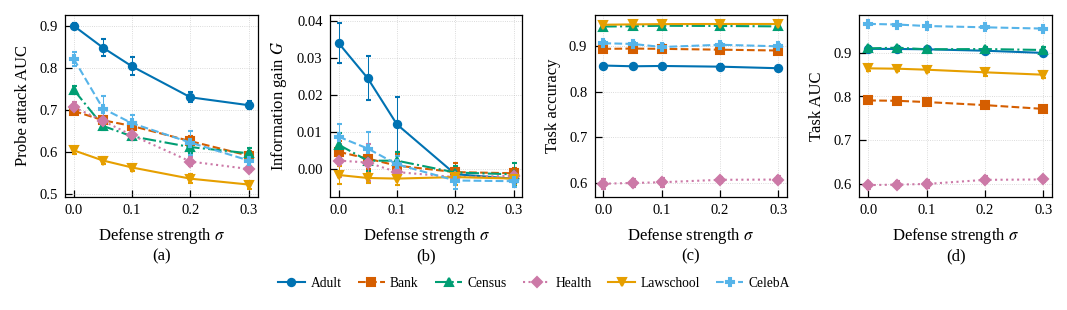

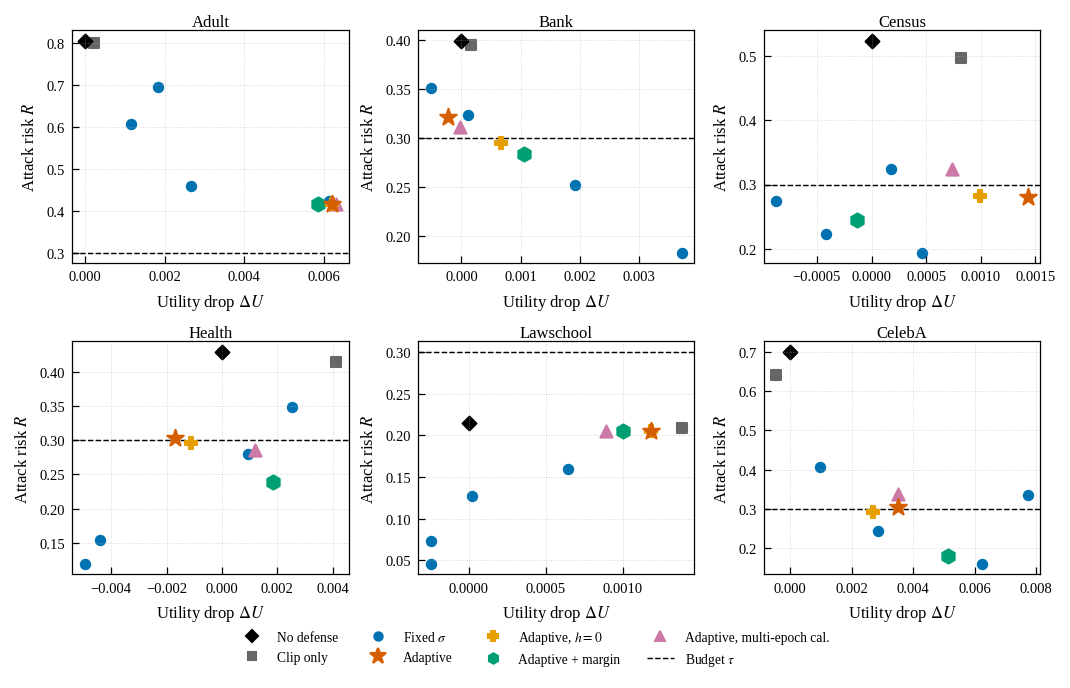

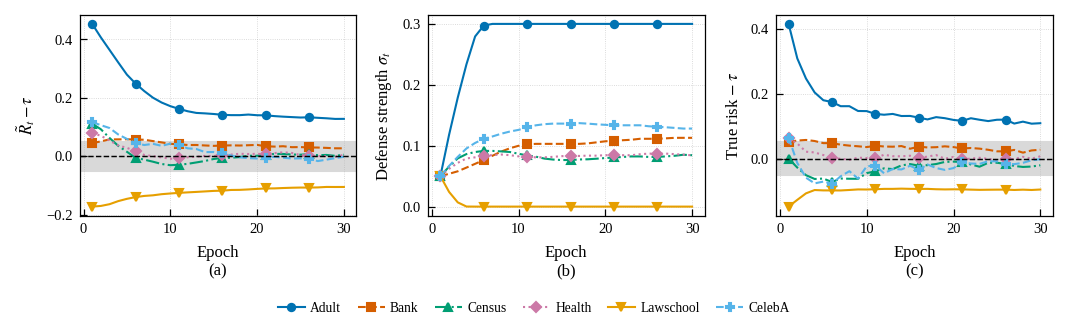

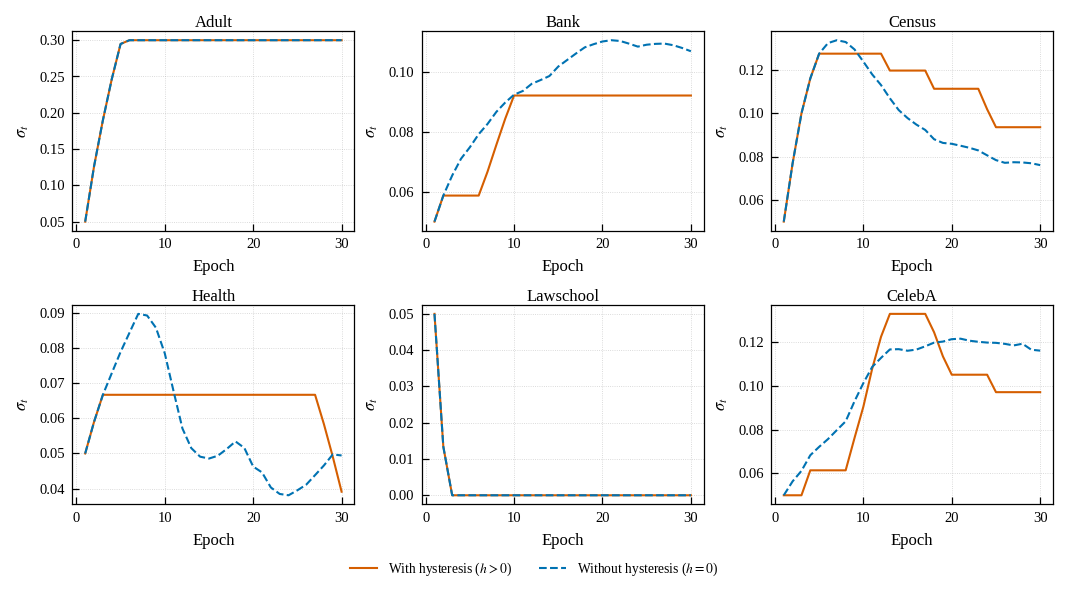

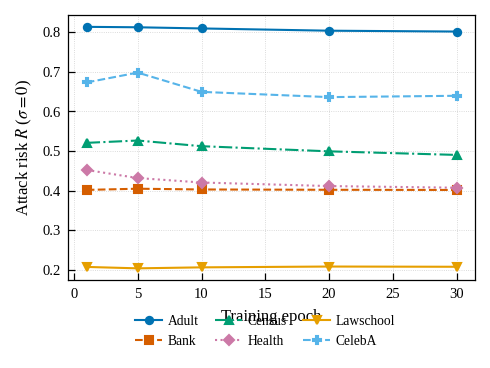

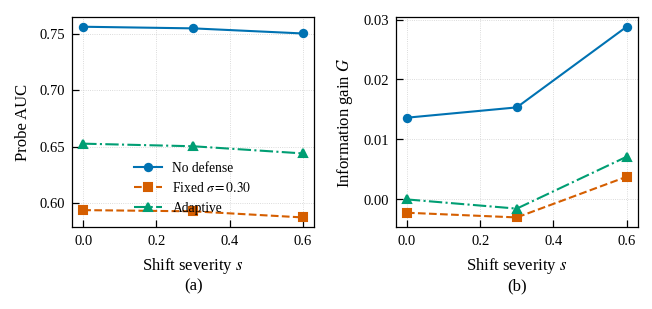

Figures saved (pdf / svg / png) to /kaggle/working/raad_pia_vfl_final_actualdata_reviewer_v3_reviewer_complete/figures


In [27]:
# ============================================================
# CELL 25 — FIGURES, IEEE Transactions style (single column 3.5 in, double column 7.16 in; Times-like serif; vector PDF + SVG + 600-dpi PNG)
# Distinct colour-blind-safe colours AND markers / line styles, so every curve stays readable in grayscale print.
# Fig. 1 of the paper is the framework diagram (not produced here).
# ============================================================
import logging; logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
from matplotlib.lines import Line2D
IEEE_1COL, IEEE_2COL = 3.5, 7.16
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "Liberation Serif", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix", "font.size": 8, "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 6.5,
    "axes.linewidth": 0.6, "lines.linewidth": 1.0, "lines.markersize": 3.5, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.direction": "in", "ytick.direction": "in", "axes.grid": True, "grid.linestyle": ":", "grid.linewidth": 0.4, "grid.alpha": 0.6,
    "legend.frameon": False, "figure.dpi": 150, "savefig.dpi": 600, "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "path",
    "axes.spines.top": True, "axes.spines.right": True})
PAL = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000", "#999999"]      # Okabe-Ito
MRK = ["o", "s", "^", "D", "v", "P", "X", "*"]; LST = ["-", "--", "-.", ":", "-", "--", "-.", ":"]
STYLE = {d: dict(color=PAL[i % 8], marker=MRK[i % 8], ls=LST[i % 8]) for i, d in enumerate(DS_ORDER)}
NICE = {"adult": "Adult", "bank": "Bank", "census": "Census", "health": "Health", "lawschool": "Lawschool", "celeba": "CelebA"}

def save_fig(fig, stem):
    for ext in ("pdf", "svg", "png"):
        fig.savefig(WORK / "figures" / f"{stem}.{ext}", bbox_inches="tight", pad_inches=0.02)
    plt.show(); plt.close(fig)

def lab(ax, xl, yl, panel=None):
    ax.set_xlabel(xl + (f"\n({panel})" if panel else "")); ax.set_ylabel(yl)

def ds_legend(fig, ncol=None, y=-0.02):
    hs = [Line2D([0], [0], **STYLE[d], label=NICE.get(d, d)) for d in DS_ORDER]
    fig.legend(handles=hs, loc="lower center", ncol=ncol or len(hs), bbox_to_anchor=(0.5, y), handletextpad=0.4, columnspacing=1.2)

fixed_seq = ["clip_only"] + [f"fixed_{s:.3f}" for s in CFG["fixed_sigmas"]]
xs = [0.0] + CFG["fixed_sigmas"]

# ---- Fig. A: effect of the (fixed) defense strength on attack success and utility (matched auxiliary data)
cols = [("test_attack_auc", "Probe attack AUC"), ("prevalence_info_gain", "Information gain $G$"),
        ("task_accuracy", "Task accuracy"), ("task_auc", "Task AUC")]
fig, axes = plt.subplots(1, 4, figsize=(IEEE_2COL, 1.9))
for a, (col, yl), pn in zip(axes, cols, "abcd"):
    for d in DS_ORDER:
        g = main[main.dataset == d].groupby("defense")[col]
        m = [g.mean().get(n, np.nan) for n in fixed_seq]; sd = [g.std().get(n, np.nan) for n in fixed_seq]
        a.errorbar(xs, m, yerr=sd, capsize=1.2, elinewidth=0.5, **STYLE[d])
    lab(a, "Defense strength $\\sigma$", yl, pn)
ds_legend(fig, y=-0.07); fig.tight_layout(w_pad=0.6); save_fig(fig, "fig_sigma_effect")

# ---- Fig. B: privacy-utility trade-off per dataset (adaptive highlighted); dashed line = leakage budget tau
n = len(DS_ORDER); nc = 3; nr = int(np.ceil(n / nc))
fig, axes = plt.subplots(nr, nc, figsize=(IEEE_2COL, 2.15 * nr), squeeze=False)
for a, d in zip(axes.ravel(), DS_ORDER):
    g = main[main.dataset == d].groupby("defense")[["utility_drop", "attack_risk"]].mean()
    for name in g.index:
        if name == "no_defense": kw = dict(marker="D", s=22, c="k")
        elif name == "clip_only": kw = dict(marker="s", s=22, c="#666666")
        elif name == "adaptive": kw = dict(marker="*", s=70, c="#D55E00", zorder=5)
        elif name == "adaptive_nohyst": kw = dict(marker="P", s=34, c="#E69F00", zorder=4)
        elif name == "adaptive_margin": kw = dict(marker="h", s=46, c="#009E73", zorder=4)
        elif name == "adaptive_multiepoch": kw = dict(marker="^", s=34, c="#CC79A7", zorder=4)
        else: kw = dict(marker="o", s=20, c="#0072B2")
        a.scatter(g.loc[name, "utility_drop"], g.loc[name, "attack_risk"], **kw)
    a.axhline(tau_for(d), ls="--", color="k", lw=0.7); a.set_title(NICE.get(d, d), fontsize=8, pad=2)
    lab(a, "Utility drop $\\Delta U$", "Attack risk $R$")
for a in axes.ravel()[n:]: a.axis("off")
hs = [Line2D([0], [0], marker="D", ls="", c="k", ms=4, label="No defense"), Line2D([0], [0], marker="s", ls="", c="#666666", ms=4, label="Clip only"),
      Line2D([0], [0], marker="o", ls="", c="#0072B2", ms=4, label="Fixed $\\sigma$"), Line2D([0], [0], marker="*", ls="", c="#D55E00", ms=8, label="Adaptive"),
      Line2D([0], [0], marker="P", ls="", c="#E69F00", ms=5, label="Adaptive, $h=0$"),
      Line2D([0], [0], marker="h", ls="", c="#009E73", ms=5, label="Adaptive + margin"), Line2D([0], [0], marker="^", ls="", c="#CC79A7", ms=5, label="Adaptive, multi-epoch cal."), Line2D([0], [0], ls="--", c="k", lw=0.7, label="Budget $\\tau$")]
fig.legend(handles=hs, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.06)); fig.tight_layout(h_pad=0.8, w_pad=0.6); save_fig(fig, "fig_tradeoff")

# ---- Fig. C: adaptive controller behaviour (mean over seeds): deviation of the risk from the budget, sigma_t, true risk
if HIST:
    h_ = CFG["controller"]["hysteresis"]
    fig, axes = plt.subplots(1, 3, figsize=(IEEE_2COL, 2.0))
    for d in DS_ORDER:
        hs_ = [H for (dd, s, v), H in HIST.items() if dd == d and v == "adaptive"]
        if not hs_: continue
        cc = pd.concat(hs_); cat = cc.groupby("epoch"); tau = tau_for(d); kw = dict(STYLE[d]); kw["markevery"] = 5
        axes[0].plot(cat.risk_ema.mean().index, cat.risk_ema.mean().values - tau, **kw)
        axes[1].plot(cat.sigma.mean().index, cat.sigma.mean().values, **kw)
        if "true_risk" in cc.columns: axes[2].plot(cat.true_risk.mean().index, cat.true_risk.mean().values - tau, **kw)
    for a in (axes[0], axes[2]):
        a.axhline(0, ls="--", color="k", lw=0.7); a.axhspan(-h_, h_, color="0.85", zorder=0)
    lab(axes[0], "Epoch", "$\\tilde R_t-\\tau$", "a"); lab(axes[1], "Epoch", "Defense strength $\\sigma_t$", "b"); lab(axes[2], "Epoch", "True risk $-\\;\\tau$", "c")
    ds_legend(fig, y=-0.1); fig.tight_layout(w_pad=0.6); save_fig(fig, "fig_adaptive_trajectory")

# ---- Fig. D: hysteresis ablation (sigma_t of the first seed, with hysteresis vs h = 0)
if HIST and RUN_ABLATION_NO_HYST:
    n = len(DS_ORDER); nc = 3; nr = int(np.ceil(n / nc))
    fig, axes = plt.subplots(nr, nc, figsize=(IEEE_2COL, 1.9 * nr), squeeze=False)
    for a, d in zip(axes.ravel(), DS_ORDER):
        for v, c, ls in [("adaptive", "#D55E00", "-"), ("adaptive_nohyst", "#0072B2", "--")]:
            H = HIST.get((d, SEEDS[0], v))
            if H is not None: a.plot(H.epoch, H.sigma, color=c, ls=ls)
        a.set_title(NICE.get(d, d), fontsize=8, pad=2); lab(a, "Epoch", "$\\sigma_t$")
    for a in axes.ravel()[n:]: a.axis("off")
    hs = [Line2D([0], [0], color="#D55E00", ls="-", label="With hysteresis ($h>0$)"), Line2D([0], [0], color="#0072B2", ls="--", label="Without hysteresis ($h=0$)")]
    fig.legend(handles=hs, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04)); fig.tight_layout(h_pad=0.8, w_pad=0.6); save_fig(fig, "fig_hysteresis_ablation")

# ---- Fig. E: leakage of an undefended-strength model (sigma = 0) over training epochs (single column)
fig, ax = plt.subplots(figsize=(IEEE_1COL, 2.3))
for d in DS_ORDER:
    s = CAL[(CAL.dataset == d) & (CAL.sigma.round(6) == 0.0) & (CAL["clip"].astype(bool))].groupby("epoch").risk.mean()
    ax.plot(s.index, s.values, **STYLE[d])
lab(ax, "Training epoch", "Attack risk $R$ ($\\sigma=0$)"); ds_legend(fig, ncol=3, y=-0.12); save_fig(fig, "fig_dynamics")

# ---- Fig. F: auxiliary-data shift (mean over datasets)
fig, axes = plt.subplots(1, 2, figsize=(IEEE_2COL * 0.62, 2.1)); sv = [CFG["shifts"][c] for c in SHIFT_CONDITIONS]
NAME = {"no_defense": "No defense", STRONGEST: "Fixed $\\sigma=%.2f$" % CFG["fixed_sigmas"][-1], "adaptive": "Adaptive"}
for i, df_ in enumerate(OBS4_DEFS):
    for col, a in zip(["test_attack_auc", "prevalence_info_gain"], axes):
        v = [ALL[(ALL.defense == df_) & (ALL.condition == c)][col].mean() for c in SHIFT_CONDITIONS]
        a.plot(sv, v, color=PAL[i], marker=MRK[i], ls=LST[i], label=NAME.get(df_, df_))
lab(axes[0], "Shift severity $s$", "Probe AUC", "a"); lab(axes[1], "Shift severity $s$", "Information gain $G$", "b")
axes[0].legend(loc="best"); fig.tight_layout(w_pad=0.8); save_fig(fig, "fig_shift")
print("Figures saved (pdf / svg / png) to", WORK / "figures")

In [28]:
# ============================================================
# CELL 26 — OVERHEAD + PACKAGE OUTPUTS
# ============================================================
if HIST:
    HH = pd.concat([H for (d, s, v), H in HIST.items() if v == "adaptive"], ignore_index=True)
    mon, trn = HH.monitor_time_sec.mean(), HH.epoch_train_sec.mean()
    OVER = pd.DataFrame([{"mean_epoch_train_sec": trn, "mean_monitor_sec_per_epoch": mon, "monitor_share_pct": 100 * mon / (trn + mon),
                          "calibration_models_per_run": len(CFG["calibration_sigmas"]),
                          "extra_communication_floats_per_sample": 0}])
    OVER.to_csv(WORK / "tables" / "OVERHEAD.csv", index=False); display(OVER.round(4))
    print("The monitor runs at the defender on D_ref only (no extra party-to-party communication in this simulation); "
          "calibration costs n_sigma = 5 offline training runs per run (they coincide with the fixed-strength baselines).")

zpath = (Path("/kaggle/working") if Path("/kaggle/working").exists() else WORK) / "outputs.zip"
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as zf:
    for sub in ["tables", "latex", "figures", "risk", "logs"]:
        for f in (WORK / sub).rglob("*"):
            if f.is_file(): zf.write(f, f.relative_to(WORK))
print("Packaged:", zpath)

,mean_epoch_train_sec,mean_monitor_sec_per_epoch,monitor_share_pct,calibration_models_per_run,extra_communication_floats_per_sample
0,0.5779,0.0474,7.5778,5,0


The monitor runs at the defender on D_ref only (no extra party-to-party communication in this simulation); calibration costs n_sigma = 5 offline training runs per run (they coincide with the fixed-strength baselines).
Packaged: /kaggle/working/outputs.zip


In [29]:
# ============================================================
# CELL 27 — VALUES FOR THE "XX" PLACEHOLDERS AND "[CHECK]"/"Section ??" ITEMS OF THE DRAFT
# ============================================================
print("Section IV-C 'Models and training' (fill the XX):")
print("  d = %d | epochs = %d | optimizer = %s, learning rate %g, weight decay %g, batch size %d | top hidden units %d | clipping C = %g | sigma in [%.2f, %.2f]"
      % (CFG["embedding_dim"], EPOCHS, CFG["optimizer"], CFG["learning_rate"], CFG["weight_decay"], CFG["batch_size"], CFG["server_hidden"],
         CFG["clip_norm"], CFG["sigma_min"], CFG["sigma_max"]))
print("Section V controller (state these values): tau = %g, h = %g, eta = %g, beta = %g, sigma_0 = %g"
      % (CFG["controller"]["budget"], CFG["controller"]["hysteresis"], CFG["controller"]["eta"], CFG["controller"]["beta"], CFG["controller"]["initial_sigma"]),
      "| per-dataset tau overrides:", CFG["tau_override"] or "none")
print("Prevalence attack (describe in IV-C): batches of %d, %d training batches with prevalences ~U[q-%.2f, q+%.2f], %d test batches ~U[rho-%.2f, rho+%.2f], ridge alpha %g, 21 norm statistics (mean, std, q10/25/50/75/90 of L1, L2, Linf)"
      % (CFG["prev_attack"]["batch_size"], CFG["prev_attack"]["n_train_batches"], CFG["prev_attack"]["spread"], CFG["prev_attack"]["spread"],
         CFG["prev_attack"]["n_test_batches"], CFG["prev_attack"]["spread"], CFG["prev_attack"]["spread"], CFG["prev_attack"]["ridge_alpha"]))
print("PROPERTY_IN_FEATURES =", PROPERTY_IN_FEATURES, "| MAX_ROWS =", MAX_ROWS, "| calibration_mode =", CFG["calibration_mode"])
print("\nTable II is printed by CELL 20 and saved as latex/tab_datasets_TableII.tex")
print("Section IV-D [CHECK]: see the suggested sentence printed by CELL 21 (also tables/obs4_trend_check.csv)")
print("\nPaper-consistency notes:")
print(" * Section III-B calls clip-only (sigma=0) the 'undefended reference', Section IV-C compares 'no defense' AND 'clip only'.")
print("   Here Delta U is measured against the TRUE undefended model (no clipping, no noise); utility_drop_vs_clip is also in ALL_RESULTS_LONG.csv.")
print(" * IV-D says 'strongest-but-one fixed defense (sigma = 0.30)' but the fixed set is {0.05,0.10,0.20,0.30} -> 0.30 is the strongest. Fix the sentence.")
print(" * IV-E mentions a gradient-boosting attacker, IV-C lists only LR + ridge -> both are run (GB on:", CFG["strong_attacker_conditions"], ").")
print(" * IV-B refers to 'Section ??' for the temporal smoothing: it is the EMA with beta in the controller (Section V).")

Section IV-C 'Models and training' (fill the XX):
  d = 32 | epochs = 30 | optimizer = Adam, learning rate 0.001, weight decay 1e-05, batch size 256 | top hidden units 64 | clipping C = 1 | sigma in [0.00, 0.30]
Section V controller (state these values): tau = 0.3, h = 0.05, eta = 0.15, beta = 0.7, sigma_0 = 0.05 | per-dataset tau overrides: none
Prevalence attack (describe in IV-C): batches of 64, 600 training batches with prevalences ~U[q-0.25, q+0.25], 400 test batches ~U[rho-0.25, rho+0.25], ridge alpha 1, 21 norm statistics (mean, std, q10/25/50/75/90 of L1, L2, Linf)
PROPERTY_IN_FEATURES = False | MAX_ROWS = 50000 | calibration_mode = final

Table II is printed by CELL 20 and saved as latex/tab_datasets_TableII.tex
Section IV-D [CHECK]: see the suggested sentence printed by CELL 21 (also tables/obs4_trend_check.csv)

Paper-consistency notes:
 * Section III-B calls clip-only (sigma=0) the 'undefended reference', Section IV-C compares 'no defense' AND 'clip only'.
   Here Delta U i

In [30]:
# ============================================================
# CELL 28 (new) — CORRECTED [CHECK] SENTENCE for Section IV-D  (replaces the sentence printed by Cell 21)
# Everything is computed from the results of this run; nothing is typed by hand.
# ============================================================
rank_txt = T_TREND["ranking (matched)"].value_counts().index[0]      # lowest attack AUC first
n_pres, n_ds = int(T_TREND["ranking preserved"].sum()), len(T_TREND)
rows = []
for d in DS_ORDER:
    a = [mean_by.loc[(d, "no_defense", c), "test_attack_auc"] for c in SHIFT_CONDITIONS]
    g = [mean_by.loc[(d, "no_defense", c), "prevalence_info_gain"] for c in SHIFT_CONDITIONS]
    p = [mean_by.loc[(d, "no_defense", c), "prior_mae"] for c in SHIFT_CONDITIONS]
    rows.append({"dataset": d, "AUC s=0": a[0], "AUC s=0.3": a[1], "AUC s=0.6": a[2], "AUC change (0->0.6)": a[2] - a[0],
                 "G s=0": g[0], "G s=0.3": g[1], "G s=0.6": g[2], "prior MAE0 s=0": p[0], "prior MAE0 s=0.6": p[2],
                 "G highest at severe shift": bool(g[2] == max(g))})
T_SHIFT = pd.DataFrame(rows); T_SHIFT.to_csv(WORK / "tables" / "obs4_shift_summary.csv", index=False)
display(T_SHIFT.round(4))
k = int(T_SHIFT["G highest at severe shift"].sum()); mx = float(T_SHIFT["AUC change (0->0.6)"].abs().max())
print("\nSentence for the [CHECK] in Section IV-D (computed from this run):\n")
print(f'"On the undefended model the probe AUC is almost unchanged by the shift (largest change between s=0 and s=0.6: {mx:.3f}), '
      f'whereas the prevalence information gain G is highest at the severe shift on {k} of {n_ds} datasets, because the prior-only predictor '
      f'degrades faster than the attacker. The ranking of the defenses in attack AUC ({rank_txt}, lowest first) is preserved under shift on {n_pres} of {n_ds} datasets."')

,dataset,AUC s=0,AUC s=0.3,AUC s=0.6,AUC change (0->0.6),G s=0,G s=0.3,G s=0.6,prior MAE0 s=0,prior MAE0 s=0.6,G highest at severe shift
0,adult,0.9027,0.9014,0.8983,-0.0045,0.0431,0.0464,0.0743,0.1257,0.1784,True
1,bank,0.6998,0.6993,0.6954,-0.0044,0.0061,0.0079,0.0156,0.1257,0.2241,True
2,census,0.7614,0.7604,0.7556,-0.0058,0.0150,0.0165,0.0315,0.1258,0.2176,True
3,health,0.7143,0.7134,0.7122,-0.0021,0.0051,0.0072,0.0156,0.1257,0.2216,True
4,lawschool,0.6077,0.6045,0.5981,-0.0096,-0.0016,-0.0005,0.0003,0.1256,0.2222,True
5,celeba,0.8499,0.8482,0.8405,-0.0094,0.0141,0.0145,0.0355,0.1257,0.1991,True



Sentence for the [CHECK] in Section IV-D (computed from this run):

"On the undefended model the probe AUC is almost unchanged by the shift (largest change between s=0 and s=0.6: 0.010), whereas the prevalence information gain G is highest at the severe shift on 6 of 6 datasets, because the prior-only predictor degrades faster than the attacker. The ranking of the defenses in attack AUC (fixed_0.300 < adaptive < no_defense, lowest first) is preserved under shift on 5 of 6 datasets."


In [31]:
# ============================================================
# CELL 29 (new) — UTILITY MEASURED WITH TASK AUC AND F1 (accuracy is close to the majority-class rate on some datasets)
# Adds columns to ALL: util_drop_auc = AUC(undefended) - AUC(defense), util_drop_f1 = F1(undefended) - F1(defense)
# ============================================================
ALL = ALL.drop(columns=[c for c in ["auc_undef", "f1_undef", "util_drop_auc", "util_drop_f1"] if c in ALL.columns])
_b = ALL[(ALL.condition == "matched") & (ALL.defense == "no_defense")][["dataset", "seed", "task_auc", "task_f1"]]
_b = _b.rename(columns={"task_auc": "auc_undef", "task_f1": "f1_undef"})
ALL = ALL.merge(_b, on=["dataset", "seed"], how="left")
ALL["util_drop_auc"] = ALL["auc_undef"] - ALL["task_auc"]
ALL["util_drop_f1"] = ALL["f1_undef"] - ALL["task_f1"]
main = ALL[ALL.condition == "matched"]
ALL.to_csv(WORK / "tables" / "ALL_RESULTS_LONG.csv", index=False)

maj = {d: float(max(meta.loc[d, "label_prevalence"], 1 - meta.loc[d, "label_prevalence"])) for d in DS_ORDER}
rows = []
for d in DS_ORDER:
    for df_ in DEF_ORDER:
        s = main[(main.dataset == d) & (main.defense == df_)]
        if s.empty: continue
        rows.append({"Dataset": d, "Defense": df_, "Majority-class acc.": maj[d],
                     "Accuracy": ms(s.task_accuracy.mean(), s.task_accuracy.std(), 4), "F1": ms(s.task_f1.mean(), s.task_f1.std(), 4),
                     "Task AUC": ms(s.task_auc.mean(), s.task_auc.std(), 4),
                     "Delta AUC": ms(s.util_drop_auc.mean(), s.util_drop_auc.std(), 4), "Delta F1": ms(s.util_drop_f1.mean(), s.util_drop_f1.std(), 4)})
T_UTIL = df_to_tex(pd.DataFrame(rows), "Primary-task utility (matched setting): accuracy, F1, task AUC and their drop relative to the undefended model.", "tab:utility", "tab_utility_auc_f1.tex", wide=True)
display(T_UTIL)
print("Majority-class acc. = accuracy of always predicting the most frequent label. If Accuracy is close to it, read the Task AUC / F1 columns instead.")

,Dataset,Defense,Majority-class acc.,Accuracy,F1,Task AUC,Delta AUC,Delta F1
0,adult,no_defense,0.759190,$0.8572\pm0.0041$,$0.6790\pm0.0156$,$0.9105\pm0.0039$,$0.0000\pm0.0000$,$0.0000\pm0.0000$
1,adult,clip_only,0.759190,$0.8569\pm0.0043$,$0.6789\pm0.0146$,$0.9092\pm0.0036$,$0.0014\pm0.0010$,$0.0001\pm0.0057$
2,adult,fixed_0.050,0.759190,$0.8553\pm0.0037$,$0.6752\pm0.0125$,$0.9089\pm0.0041$,$0.0016\pm0.0008$,$0.0038\pm0.0087$
3,adult,fixed_0.100,0.759190,$0.8560\pm0.0049$,$0.6772\pm0.0132$,$0.9082\pm0.0045$,$0.0024\pm0.0014$,$0.0018\pm0.0135$
4,adult,fixed_0.200,0.759190,$0.8545\pm0.0049$,$0.6708\pm0.0149$,$0.9049\pm0.0045$,$0.0056\pm0.0018$,$0.0082\pm0.0146$
5,adult,fixed_0.300,0.759190,$0.8510\pm0.0051$,$0.6620\pm0.0135$,$0.8999\pm0.0048$,$0.0106\pm0.0022$,$0.0170\pm0.0147$
6,adult,adaptive,0.759190,$0.8510\pm0.0037$,$0.6605\pm0.0121$,$0.8998\pm0.0039$,$0.0107\pm0.0024$,$0.0185\pm0.0142$
7,adult,adaptive_nohyst,0.759190,$0.8510\pm0.0037$,$0.6605\pm0.0121$,$0.8998\pm0.0039$,$0.0107\pm0.0024$,$0.0185\pm0.0142$
8,adult,adaptive_margin,0.759190,$0.8513\pm0.0037$,$0.6615\pm0.0114$,$0.8999\pm0.0036$,$0.0106\pm0.0022$,$0.0175\pm0.0138$
9,adult,adaptive_multiepoch,0.759190,$0.8509\pm0.0035$,$0.6601\pm0.0115$,$0.8998\pm0.0038$,$0.0108\pm0.0024$,$0.0189\pm0.0137$


Majority-class acc. = accuracy of always predicting the most frequent label. If Accuracy is close to it, read the Task AUC / F1 columns instead.


In [32]:
# ============================================================
# CELL 30 (new) — PROBLEM (11) AGAIN, utility measured by task-AUC drop and F1 drop
# (same logic as Cell 22: adaptive vs the CHEAPEST fixed sigma that meets the same budget tau)
# ============================================================
def problem11(ucol, tag):
    rows = []
    for d in DS_ORDER:
        tau = tau_for(d)
        for cond in SHIFT_CONDITIONS:
            g = ALL[(ALL.dataset == d) & (ALL.condition == cond)].groupby("defense")[["sigma", "attack_risk", ucol]].mean()
            if "adaptive" not in g.index: continue
            fxg = g.loc[[x for x in fixed_names if x in g.index]].sort_values("sigma"); ok = fxg[fxg.attack_risk <= tau]
            best = ok.sort_values(ucol).iloc[0] if len(ok) else None
            rows.append({"Dataset": d, "Shift": cond, "tau": tau, "Adaptive R": float(g.loc["adaptive", "attack_risk"]),
                         f"Adaptive {tag}": float(g.loc["adaptive", ucol]),
                         "Cheapest compliant fixed": (best.name if best is not None else "none"),
                         "its R": float(best.attack_risk) if best is not None else np.nan,
                         f"its {tag}": float(best[ucol]) if best is not None else np.nan,
                         f"{tag} (adaptive - fixed)": float(g.loc["adaptive", ucol] - best[ucol]) if best is not None else np.nan,
                         f"{tag} at sigma_max": float(fxg[ucol].iloc[-1])})
    return pd.DataFrame(rows)

fixed_names = [d for d in DEF_ORDER if d == "clip_only" or d.startswith("fixed_")]
T_P11_AUC = df_to_tex(problem11("util_drop_auc", "Delta AUC"), "Budget compliance and task-AUC cost: adaptive vs.\\ the cheapest fixed strength meeting the same budget.", "tab:p11auc", "tab_problem11_auc.tex", wide=True)
T_P11_F1 = df_to_tex(problem11("util_drop_f1", "Delta F1"), "Budget compliance and F1 cost: adaptive vs.\\ the cheapest fixed strength meeting the same budget.", "tab:p11f1", "tab_problem11_f1.tex", wide=True)
display(T_P11_AUC); display(T_P11_F1)
print("(adaptive - fixed) < 0 => adaptive loses less utility than the cheapest fixed defense with the same budget.")

# paired statistics for the utility drops (matched setting, adaptive vs every other defense)
ST = pd.concat([paired_table(ALL, d, "matched", mets=("util_drop_auc", "util_drop_f1")) for d in DS_ORDER], ignore_index=True)
ST.to_csv(WORK / "tables" / "PAIRED_STATS_UTILITY.csv", index=False)
if len(ST): display(ST[ST.other.isin(fixed_names)].round(4))

,Dataset,Shift,tau,Adaptive R,Adaptive Delta AUC,Cheapest compliant fixed,its R,its Delta AUC,Delta AUC (adaptive - fixed),Delta AUC at sigma_max
0,adult,matched,0.3,0.417141,0.010707,none,NaN,NaN,NaN,0.010639
1,adult,moderate,0.3,0.415507,0.010707,none,NaN,NaN,NaN,0.010639
2,adult,severe,0.3,0.401336,0.010707,none,NaN,NaN,NaN,0.010639
3,bank,matched,0.3,0.321213,0.005064,fixed_0.200,0.251888,0.012000,-0.006936,0.020700
4,bank,moderate,0.3,0.319089,0.005064,fixed_0.200,0.249463,0.012000,-0.006936,0.020700
5,bank,severe,0.3,0.307155,0.005064,fixed_0.200,0.240367,0.012000,-0.006936,0.020700
6,census,matched,0.3,0.280385,0.004670,fixed_0.200,0.223849,0.005607,-0.000938,0.007767
7,census,moderate,0.3,0.282031,0.004670,fixed_0.200,0.220564,0.005607,-0.000938,0.007767
8,census,severe,0.3,0.270831,0.004670,fixed_0.200,0.210500,0.005607,-0.000938,0.007767
9,health,matched,0.3,0.302525,0.001361,fixed_0.300,0.119666,-0.007781,0.009141,-0.007781


,Dataset,Shift,tau,Adaptive R,Adaptive Delta F1,Cheapest compliant fixed,its R,its Delta F1,Delta F1 (adaptive - fixed),Delta F1 at sigma_max
0,adult,matched,0.3,0.417141,0.018451,none,NaN,NaN,NaN,0.017010
1,adult,moderate,0.3,0.415507,0.018451,none,NaN,NaN,NaN,0.017010
2,adult,severe,0.3,0.401336,0.018451,none,NaN,NaN,NaN,0.017010
3,bank,matched,0.3,0.321213,0.002696,fixed_0.200,0.251888,0.017475,-0.014779,0.036112
4,bank,moderate,0.3,0.319089,0.002696,fixed_0.200,0.249463,0.017475,-0.014779,0.036112
5,bank,severe,0.3,0.307155,0.002696,fixed_0.200,0.240367,0.017475,-0.014779,0.036112
6,census,matched,0.3,0.280385,-0.006987,fixed_0.200,0.223849,-0.015716,0.008730,-0.013616
7,census,moderate,0.3,0.282031,-0.006987,fixed_0.200,0.220564,-0.015716,0.008730,-0.013616
8,census,severe,0.3,0.270831,-0.006987,fixed_0.200,0.210500,-0.015716,0.008730,-0.013616
9,health,matched,0.3,0.302525,-0.004424,fixed_0.300,0.119666,-0.016669,0.012245,-0.016669


(adaptive - fixed) < 0 => adaptive loses less utility than the cheapest fixed defense with the same budget.


/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


,dataset,condition,metric,other,n_seeds,mean_diff,ci95_low,ci95_high,p_raw,p_holm
3,adult,matched,util_drop_auc,clip_only,10,0.0093,0.0076,0.0111,0.0020,0.0352
4,adult,matched,util_drop_auc,fixed_0.050,10,0.0091,0.0075,0.0105,0.0020,0.0352
5,adult,matched,util_drop_auc,fixed_0.100,10,0.0083,0.0068,0.0097,0.0020,0.0352
6,adult,matched,util_drop_auc,fixed_0.200,10,0.0051,0.0034,0.0066,0.0039,0.0508
7,adult,matched,util_drop_auc,fixed_0.300,10,0.0001,-0.0020,0.0018,0.6250,1.0000
12,adult,matched,util_drop_f1,clip_only,10,0.0183,0.0120,0.0248,0.0039,0.0508
13,adult,matched,util_drop_f1,fixed_0.050,10,0.0147,0.0086,0.0210,0.0039,0.0508
14,adult,matched,util_drop_f1,fixed_0.100,10,0.0166,0.0115,0.0218,0.0020,0.0352
15,adult,matched,util_drop_f1,fixed_0.200,10,0.0102,0.0038,0.0165,0.0273,0.2461
16,adult,matched,util_drop_f1,fixed_0.300,10,0.0014,-0.0045,0.0073,0.9219,1.0000


In [33]:
# ============================================================
# CELL 31 (new) — HOW CLOSE TO THE BUDGET? and WHAT DOES THE HYSTERESIS BAND COST/BUY?
# ============================================================
h = CFG["controller"]["hysteresis"]; rows = []
for d in DS_ORDER:
    tau = tau_for(d)
    for v in ["adaptive", "adaptive_nohyst"]:
        s = ALL[(ALL.dataset == d) & (ALL.condition == "matched") & (ALL.defense == v)]
        if s.empty: continue
        r = s.attack_risk
        rows.append({"Dataset": d, "Variant": v, "tau": tau, "mean R": float(r.mean()), "std R": float(r.std()), "mean R - tau": float(r.mean() - tau),
                     "seeds with R <= tau": float((r <= tau).mean()), "seeds within tau+-h": float(((r - tau).abs() <= h).mean()),
                     "seeds within tau+-2h": float(((r - tau).abs() <= 2 * h).mean()),
                     "mean final sigma": float(s.sigma.mean()), "Delta U (acc.)": float(s.utility_drop.mean()), "Delta AUC": float(s.util_drop_auc.mean())})
T_BUD = df_to_tex(pd.DataFrame(rows), "Closeness of the adaptive defense to the leakage budget (matched auxiliary data, evaluation attacker).", "tab:budget", "tab_budget_closeness.tex", wide=True)
display(T_BUD)

g = DIAG.groupby(["dataset", "variant"]).mean(numeric_only=True)
rows = []
for d in DS_ORDER:
    if (d, "adaptive") not in g.index or (d, "adaptive_nohyst") not in g.index: continue
    a, b = g.loc[(d, "adaptive")], g.loc[(d, "adaptive_nohyst")]
    rows.append({"Dataset": d, "sigma changes (hyst / h=0)": f"{a.n_sigma_changes:.1f} / {b.n_sigma_changes:.1f}",
                 "sigma total variation (hyst / h=0)": f"{a.sigma_total_variation:.3f} / {b.sigma_total_variation:.3f}",
                 "TV reduction %": 100 * (1 - a.sigma_total_variation / b.sigma_total_variation),
                 "band occupancy raw (hyst / h=0)": f"{a.band_frac_raw:.2f} / {b.band_frac_raw:.2f}",
                 "tracking error last10 (hyst / h=0)": f"{a.track_err_last10:.3f} / {b.track_err_last10:.3f}"})
T_HYS = df_to_tex(pd.DataFrame(rows), "Effect of the hysteresis band: fluctuation of $\\sigma_t$ versus tracking accuracy.", "tab:hysteresis", "tab_hysteresis_tradeoff.tex", wide=True)
display(T_HYS)
print("Reading: hysteresis should lower sigma changes / total variation; the price is looser tracking (lower band occupancy, larger tracking error).")

,Dataset,Variant,tau,mean R,std R,mean R - tau,seeds with R <= tau,seeds within tau+-h,seeds within tau+-2h,mean final sigma,Delta U (acc.),Delta AUC
0,adult,adaptive,0.3,0.417141,0.018594,0.117141,0.0,0.0,0.2,0.300000,0.006204,0.010707
1,adult,adaptive_nohyst,0.3,0.417141,0.018594,0.117141,0.0,0.0,0.2,0.300000,0.006204,0.010707
2,bank,adaptive,0.3,0.321213,0.029135,0.021213,0.1,0.8,1.0,0.112936,-0.000232,0.005064
3,bank,adaptive_nohyst,0.3,0.294838,0.031344,-0.005162,0.7,0.9,1.0,0.164073,0.000664,0.008034
4,census,adaptive,0.3,0.280385,0.039737,-0.019615,0.6,0.6,1.0,0.084388,0.001430,0.004670
5,census,adaptive_nohyst,0.3,0.281712,0.036976,-0.018288,0.7,0.7,1.0,0.083597,0.000990,0.004799
6,health,adaptive,0.3,0.302525,0.043665,0.002525,0.6,0.9,1.0,0.084242,-0.001680,0.001361
7,health,adaptive_nohyst,0.3,0.296234,0.035599,-0.003766,0.6,0.9,1.0,0.090832,-0.001100,0.001072
8,lawschool,adaptive,0.3,0.205149,0.018938,-0.094851,1.0,0.0,0.6,0.000000,0.001183,0.003429
9,lawschool,adaptive_nohyst,0.3,0.205149,0.018938,-0.094851,1.0,0.0,0.6,0.000000,0.001183,0.003429


,Dataset,sigma changes (hyst / h=0),sigma total variation (hyst / h=0),TV reduction %,band occupancy raw (hyst / h=0),tracking error last10 (hyst / h=0)
0,adult,30.0 / 30.0,0.250 / 0.250,0.000000,0.00 / 0.00,0.133 / 0.133
1,bank,6.7 / 30.0,0.063 / 0.123,48.976358,0.75 / 0.92,0.034 / 0.012
2,census,6.3 / 30.0,0.073 / 0.117,38.052296,0.73 / 0.78,0.029 / 0.015
3,health,6.1 / 30.0,0.061 / 0.125,51.423031,0.68 / 0.74,0.025 / 0.019
4,lawschool,30.0 / 30.0,0.050 / 0.050,0.000000,0.00 / 0.00,0.107 / 0.107
5,celeba,7.6 / 30.0,0.102 / 0.143,29.155811,0.70 / 0.74,0.027 / 0.017


Reading: hysteresis should lower sigma changes / total variation; the price is looser tracking (lower band occupancy, larger tracking error).


In [34]:
# ============================================================
# CELL 31b — BASELINE ACCURACY PER DATASET AND SEED, AND THE GAP TO THE TARGET (report only)
# TARGET_ACC is never used for training, tuning or selection. The table tells you where the gap comes from:
# 'excess over majority' = accuracy - accuracy of always predicting the most frequent label.
# ============================================================
nd = ALL[(ALL.condition == "matched") & (ALL.defense == "no_defense")]
per_seed = nd.pivot(index="seed", columns="dataset", values="task_accuracy")[DS_ORDER]
per_seed.to_csv(WORK / "tables" / "baseline_accuracy_per_seed.csv"); print("Undefended accuracy per seed:"); display(per_seed.round(4))
rows = []
for d in DS_ORDER:
    a = nd[nd.dataset == d]; ad = ALL[(ALL.condition == "matched") & (ALL.defense == "adaptive") & (ALL.dataset == d)]
    rows.append({"dataset": d, "majority acc.": maj[d], "undefended acc.": a.task_accuracy.mean(), "std": a.task_accuracy.std(),
                 "excess over majority": a.task_accuracy.mean() - maj[d], "task AUC": a.task_auc.mean(),
                 "adaptive acc.": ad.task_accuracy.mean(), "adaptive - undefended": ad.task_accuracy.mean() - a.task_accuracy.mean(),
                 "gap to TARGET": TARGET_ACC - a.task_accuracy.mean(), "seeds >= TARGET": int((a.task_accuracy >= TARGET_ACC).sum()),
                 "note": ("barely above the majority-class rate: accuracy cannot move, read AUC/F1" if a.task_accuracy.mean() - maj[d] < 0.005 else "")})
T_GAP = pd.DataFrame(rows); T_GAP.to_csv(WORK / "tables" / "baseline_gap_to_target.csv", index=False)
with pd.option_context("display.max_columns", None, "display.width", 250, "display.max_colwidth", 80):
    display(T_GAP.round(4))
print(f"Aggregate over datasets: undefended {T_GAP['undefended acc.'].mean():.4f} | adaptive {T_GAP['adaptive acc.'].mean():.4f} | target {TARGET_ACC} | "
      f"datasets reaching the target on average: {int((T_GAP['undefended acc.'] >= TARGET_ACC).sum())} of {len(T_GAP)}")
print("If 'adaptive - undefended' is ~0 the defense is NOT the cause of the gap; the task / dataset / model ceiling is.")

Undefended accuracy per seed:


dataset,adult,bank,census,health,lawschool,celeba
seed,,,,,,
0,0.8509,0.8952,0.9422,0.6113,0.9493,0.9080
1,0.8563,0.8942,0.9469,0.6105,0.9482,0.9028
2,0.8557,0.8935,0.9446,0.5912,0.9455,0.9088
3,0.8552,0.8931,0.9454,0.6112,0.9496,0.9022
4,0.8612,0.8940,0.9416,0.6164,0.9482,0.9025
5,0.8572,0.8919,0.9383,0.5835,0.9487,0.9075
6,0.8517,0.8962,0.9427,0.6052,0.9475,0.8972
7,0.8593,0.8922,0.9409,0.6068,0.9464,0.9130
8,0.8606,0.8894,0.9435,0.5911,0.9471,0.9050


,dataset,majority acc.,undefended acc.,std,excess over majority,task AUC,adaptive acc.,adaptive - undefended,gap to TARGET,seeds >= TARGET,note
0,adult,0.7592,0.8572,0.0041,0.0980,0.9105,0.8510,-0.0062,0.0988,0,
1,bank,0.8830,0.8936,0.0021,0.0105,0.7922,0.8938,0.0002,0.0624,0,
2,census,0.9373,0.9431,0.0025,0.0058,0.9144,0.9417,-0.0014,0.0129,0,
3,health,0.6021,0.6026,0.0109,0.0004,0.6020,0.6043,0.0017,0.3534,0,"barely above the majority-class rate: accuracy cannot move, read AUC/F1"
4,lawschool,0.9478,0.9476,0.0014,-0.0002,0.8682,0.9464,-0.0012,0.0084,0,"barely above the majority-class rate: accuracy cannot move, read AUC/F1"
5,celeba,0.5174,0.9052,0.0044,0.3878,0.9659,0.9018,-0.0035,0.0507,0,


Aggregate over datasets: undefended 0.8582 | adaptive 0.8565 | target 0.956 | datasets reaching the target on average: 0 of 6
If 'adaptive - undefended' is ~0 the defense is NOT the cause of the gap; the task / dataset / model ceiling is.


In [35]:
# ============================================================
# CELL 31c — IS THE IMPROVED CONTROLLER ACTUALLY BETTER?  (budget compliance, tracking, utility; paired statistics vs the existing adaptive)
# ============================================================
VARS = [v for v in ["adaptive", "adaptive_margin", "adaptive_multiepoch", "adaptive_nohyst"] if v in ALL.defense.unique()]
h = CFG["controller"]["hysteresis"]; rows = []
for d in DS_ORDER:
    tau = tau_for(d)
    for v in VARS:
        s = ALL[(ALL.dataset == d) & (ALL.condition == "matched") & (ALL.defense == v)]
        if s.empty: continue
        rows.append({"dataset": d, "variant": v, "tau": tau, "mean R": s.attack_risk.mean(), "mean R - tau": s.attack_risk.mean() - tau,
                     "seeds R<=tau": float((s.attack_risk <= tau).mean()), "seeds |R-tau|<=h": float(((s.attack_risk - tau).abs() <= h).mean()),
                     "mean final sigma": s.sigma.mean(), "Delta U (acc.)": s.utility_drop.mean(), "Delta AUC (task)": s.util_drop_auc.mean(),
                     "attack AUC": s.test_attack_auc.mean()})
T_V2 = pd.DataFrame(rows)
agg = T_V2.groupby("variant")[["mean R - tau", "seeds R<=tau", "seeds |R-tau|<=h", "Delta U (acc.)", "Delta AUC (task)", "attack AUC"]].mean().reset_index()
agg.insert(0, "dataset", "ALL (mean)"); T_V2 = pd.concat([T_V2, agg], ignore_index=True)
df_to_tex(T_V2, "Controller variants: budget compliance, tracking and utility (matched auxiliary data).", "tab:v2", "tab_controller_variants.tex", wide=True)
with pd.option_context("display.max_columns", None, "display.width", 250):
    display(T_V2.round(4))
if "adaptive_margin" in VARS:
    ST2 = pd.concat([paired_table(ALL, d, "matched", target="adaptive_margin", mets=("attack_risk", "utility_drop", "util_drop_auc")) for d in DS_ORDER], ignore_index=True)
    ST2 = ST2[ST2.other == "adaptive"] if len(ST2) else ST2
    ST2.to_csv(WORK / "tables" / "PAIRED_STATS_margin_vs_adaptive.csv", index=False)
    print("\nPaired statistics, adaptive_margin minus adaptive (negative attack_risk = less leakage; positive utility_drop / util_drop_auc = more utility lost):")
    if len(ST2): display(ST2.round(4))
print("Report a modification as an improvement only if budget compliance rises WITHOUT a clear loss in utility (check the CI columns), per dataset and in aggregate.")

,dataset,variant,tau,mean R,mean R - tau,seeds R<=tau,seeds |R-tau|<=h,mean final sigma,Delta U (acc.),Delta AUC (task),attack AUC
0,adult,adaptive,0.3,0.4171,0.1171,0.0000,0.0000,0.3000,0.0062,0.0107,0.7086
1,adult,adaptive_margin,0.3,0.4172,0.1172,0.0000,0.0000,0.3000,0.0059,0.0106,0.7086
2,adult,adaptive_multiepoch,0.3,0.4170,0.1170,0.0000,0.0000,0.3000,0.0063,0.0108,0.7085
3,adult,adaptive_nohyst,0.3,0.4171,0.1171,0.0000,0.0000,0.3000,0.0062,0.0107,0.7086
4,bank,adaptive,0.3,0.3212,0.0212,0.1000,0.8000,0.1129,-0.0002,0.0051,0.6606
5,bank,adaptive_margin,0.3,0.2841,-0.0159,0.8000,0.9000,0.1683,0.0011,0.0075,0.6421
6,bank,adaptive_multiepoch,0.3,0.3117,0.0117,0.5000,0.9000,0.1280,-0.0000,0.0056,0.6558
7,bank,adaptive_nohyst,0.3,0.2948,-0.0052,0.7000,0.9000,0.1641,0.0007,0.0080,0.6474
8,census,adaptive,0.3,0.2804,-0.0196,0.6000,0.6000,0.0844,0.0014,0.0047,0.6402
9,census,adaptive_margin,0.3,0.2444,-0.0556,1.0000,0.5000,0.1288,-0.0001,0.0054,0.6222



Paired statistics, adaptive_margin minus adaptive (negative attack_risk = less leakage; positive utility_drop / util_drop_auc = more utility lost):


,dataset,condition,metric,other,n_seeds,mean_diff,ci95_low,ci95_high,p_raw,p_holm
0,adult,matched,attack_risk,adaptive,10,0.0001,-0.0006,0.0009,1.0000,1.0000
9,adult,matched,utility_drop,adaptive,10,-0.0003,-0.0010,0.0002,0.4844,1.0000
18,adult,matched,util_drop_auc,adaptive,10,-0.0001,-0.0003,0.0001,0.3750,1.0000
27,bank,matched,attack_risk,adaptive,10,-0.0371,-0.0519,-0.0241,0.0020,0.0527
36,bank,matched,utility_drop,adaptive,10,0.0013,0.0005,0.0022,0.0039,0.0742
45,bank,matched,util_drop_auc,adaptive,10,0.0025,0.0011,0.0041,0.0059,0.1055
54,census,matched,attack_risk,adaptive,10,-0.0360,-0.0513,-0.0202,0.0098,0.1953
63,census,matched,utility_drop,adaptive,10,-0.0016,-0.0030,-0.0001,0.1016,1.0000
72,census,matched,util_drop_auc,adaptive,10,0.0008,-0.0007,0.0024,0.4922,1.0000
81,health,matched,attack_risk,adaptive,10,-0.0642,-0.0790,-0.0496,0.0020,0.0527


Report a modification as an improvement only if budget compliance rises WITHOUT a clear loss in utility (check the CI columns), per dataset and in aggregate.


In [36]:
# ============================================================
# CELL 31d — ProVFL-STYLE ATTACK (re-implemented from the abstract; not the authors' code) vs the ridge attacker, all defenses and shifts
# ProVFL: populations with different property fractions -> histograms of Lp norms -> regressor of the fraction.
# PI-FD (federated distillation with a public data set) is a different protocol and is NOT implemented here.
# ============================================================
if "provfl_info_gain" in ALL.columns and ALL["provfl_info_gain"].notna().any():
    rows = []
    for d in DS_ORDER:
        for df_ in DEF_ORDER:
            for cond in ["matched", "severe"]:
                s = ALL[(ALL.dataset == d) & (ALL.defense == df_) & (ALL.condition == cond)]
                if s.empty or s.provfl_mae.isna().all(): continue
                rows.append({"Dataset": d, "Defense": df_, "Shift": cond, "ProVFL-style MAE": ms(s.provfl_mae.mean(), s.provfl_mae.std(), 4),
                             "ProVFL-style G": ms(s.provfl_info_gain.mean(), s.provfl_info_gain.std(), 4),
                             "Ridge MAE": ms(s.prevalence_mae.mean(), s.prevalence_mae.std(), 4), "Ridge G": ms(s.prevalence_info_gain.mean(), s.prevalence_info_gain.std(), 4),
                             "Probe AUC": ms(s.test_attack_auc.mean(), s.test_attack_auc.std())})
    T_PV = df_to_tex(pd.DataFrame(rows), "Prevalence-estimation attacks (ProVFL-style distribution comparison and ridge on norm statistics) against each defense.", "tab:provfl", "tab_provfl_style_attack.tex", wide=True)
    display(T_PV)
    print("G > 0: the attack beats the prior-only predictor. A defense is effective against this attacker when G falls to ~0 while task utility is kept.")
else:
    print("No ProVFL-style columns in the results (they are produced by runs made with this version of Cell 14).")

,Dataset,Defense,Shift,ProVFL-style MAE,ProVFL-style G,Ridge MAE,Ridge G,Probe AUC
0,adult,no_defense,matched,$0.1016\pm0.0125$,$0.0241\pm0.0144$,$0.0827\pm0.0062$,$0.0431\pm0.0081$,$0.903\pm0.008$
1,adult,no_defense,severe,$0.0987\pm0.0074$,$0.0797\pm0.0121$,$0.1041\pm0.0058$,$0.0743\pm0.0062$,$0.898\pm0.009$
2,adult,clip_only,matched,$0.1169\pm0.0308$,$0.0088\pm0.0305$,$0.0917\pm0.0061$,$0.0341\pm0.0054$,$0.900\pm0.007$
3,adult,clip_only,severe,$0.1180\pm0.0295$,$0.0604\pm0.0272$,$0.1134\pm0.0103$,$0.0649\pm0.0078$,$0.895\pm0.007$
4,adult,fixed_0.050,matched,$0.1388\pm0.0118$,$-0.0131\pm0.0140$,$0.1012\pm0.0043$,$0.0245\pm0.0059$,$0.848\pm0.021$
...,...,...,...,...,...,...,...,...
115,celeba,adaptive_nohyst,severe,$0.1645\pm0.0096$,$0.0347\pm0.0128$,$0.1848\pm0.0081$,$0.0143\pm0.0080$,$0.628\pm0.036$
116,celeba,adaptive_margin,matched,$0.1718\pm0.0092$,$-0.0461\pm0.0092$,$0.1288\pm0.0046$,$-0.0031\pm0.0027$,$0.590\pm0.025$
117,celeba,adaptive_margin,severe,$0.1620\pm0.0099$,$0.0371\pm0.0135$,$0.1889\pm0.0101$,$0.0103\pm0.0101$,$0.574\pm0.023$
118,celeba,adaptive_multiepoch,matched,$0.1633\pm0.0121$,$-0.0376\pm0.0141$,$0.1235\pm0.0030$,$0.0022\pm0.0052$,$0.669\pm0.024$


G > 0: the attack beats the prior-only predictor. A defense is effective against this attacker when G falls to ~0 while task utility is kept.


In [38]:
# ============================================================
# CELL 32 (new) — SVG ZIP + FINAL OUTPUTS ZIP (all tables, LaTeX, figures png/pdf/svg, risk files, logs)
# ============================================================
out_dir = Path("/kaggle/working") if Path("/kaggle/working").exists() else WORK
svgs = sorted((WORK / "figures").glob("*.svg"))
print(f"{len(svgs)} SVG figures:"); [print("  ", f.name) for f in svgs]
z1 = out_dir / "figures_svg.zip"
with zipfile.ZipFile(z1, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in svgs: zf.write(f, f.name)
z2 = out_dir / "outputs_final.zip"
with zipfile.ZipFile(z2, "w", zipfile.ZIP_DEFLATED) as zf:
    for sub in ["tables", "latex", "figures", "risk", "logs"]:
        for f in (WORK / sub).rglob("*"):
            if f.is_file(): zf.write(f, f.relative_to(WORK))
print("Saved:", z1, "|", z2)
try:
    from IPython.display import FileLink
    display(FileLink(z1.name)); display(FileLink(z2.name))
except Exception:
    pass
print("If a link does not work: Kaggle right panel -> Output -> /kaggle/working -> three dots -> Download.")

6 SVG figures:
   fig_adaptive_trajectory.svg
   fig_dynamics.svg
   fig_hysteresis_ablation.svg
   fig_shift.svg
   fig_sigma_effect.svg
   fig_tradeoff.svg
Saved: /kaggle/working/figures_svg.zip | /kaggle/working/outputs_final.zip


/kaggle/working/figures_svg.zip

/kaggle/working/outputs_final.zip

If a link does not work: Kaggle right panel -> Output -> /kaggle/working -> three dots -> Download.


## Notes for the paper

* **Everything in the tables comes from the run.** Nothing in this notebook targets a particular result. `TARGET_ACC` is only used to print the accuracy gap (Cell 31b); it is never used for training, tuning or model selection.
* **Accuracy ceiling.** Cell 31b shows, per dataset, the undefended accuracy, the majority-class rate and the gap to the target. Where accuracy is within 0.5 points of the majority-class rate (e.g. Health, Lawschool), accuracy cannot discriminate between defenses; use task AUC / F1 (Cell 29).
* **Hyper-parameter tuning (Cell 16b)** is validation-only: it uses 80/20 of the TRAIN split of seed 0 and never touches D_sim, D_ref or the test set. C, sigma range and the number of epochs are fixed by the paper and are not tuned. A tuned run must use a NEW `RUN_TAG`.
* **Controller variants (Cells 18b, 31c)**: `adaptive_margin` aims at tau minus the leave-one-sigma-out error of the run's own risk estimator; `adaptive_multiepoch` calibrates on all snapshot epochs. Call a variant an improvement only if the paired statistics show higher budget compliance without a clear utility loss.
* **Competitors.** ProVFL and PI-FD are ATTACKS. The "ProVFL-style" attacker (Cell 31d) is re-implemented from the paper's abstract and is not the authors' code; PI-FD (federated distillation with a public data set) is a different protocol and is not implemented. State this in the paper.
* **Implementation choices that the paper must state:** subsampling to `MAX_ROWS`; fixed-seed CelebA image subset; label/property per dataset; property column removed from the features; common pre-specified tau=0.30; controller eta, beta, sigma_0, h; prevalence-batch construction; stratified random split; evaluation of the adaptive model at the sigma of the last epoch; CelebA subset and image size.
* **Limitations:** linear / boosted classifiers and simplified ProVFL-style attackers only; no formal DP guarantee; prevalence shift only; a small property-annotated reference set is required; calibration needs extra offline runs.

## Reviewer-oriented validation add-on (run after the main driver)

This cell does **not** fabricate missing baseline results. It adds seed-held-out calibration diagnostics and confidence intervals from the actual runs. It requires the main driver to have produced the calibration-record CSVs. It does not substitute for implementing and running the distinct ProVFL defense baselines (randomized response, shuffling, sample withdrawal, and an adaptive baseline), which need a protocol-matched implementation before their results can be reported.


In [39]:
# ============================================================
# REVIEWER ADD-ON A — seed-held-out calibration diagnostics + 95% CIs
# Run after the main driver and before packaging results.
# For each target seed, fit isotonic calibration on OTHER seeds' calibration
# records and evaluate on the held-out seed's final-epoch calibration points.
# This is independent across random splits/seeds, though it is not a substitute
# for a separately collected reference population.
# ============================================================
from scipy.stats import t as student_t

def mean_sd_ci(values, confidence=0.95):
    x = pd.to_numeric(pd.Series(values), errors="coerce").dropna().to_numpy(float)
    n = len(x)
    if n == 0:
        return {"n": 0, "mean": np.nan, "sd": np.nan, "ci_low": np.nan, "ci_high": np.nan}
    mu = float(np.mean(x))
    sd = float(np.std(x, ddof=1)) if n > 1 else 0.0
    if n > 1:
        q = float(student_t.ppf((1 + confidence) / 2, n - 1))
        half = q * sd / np.sqrt(n)
    else:
        half = np.nan
    return {"n": n, "mean": mu, "sd": sd,
            "ci_low": mu - half if n > 1 else np.nan,
            "ci_high": mu + half if n > 1 else np.nan}

def heldout_seed_calibration_audit():
    rows = []
    for dataset in READY:
        by_seed = {}
        for seed in SEEDS:
            fp = WORK / "risk" / f"{dataset}_seed_{seed}_calibration_records.csv"
            if not fp.exists():
                continue
            d = pd.read_csv(fp)
            required = {"kappa", "risk", "sigma", "epoch"}
            if not required.issubset(d.columns):
                continue
            d = d[d["epoch"] == EPOCHS].copy()
            d = d[d["clip"].astype(bool) & d["sigma"].round(6).isin(
                [round(s, 6) for s in CFG["calibration_sigmas"]])]
            if len(d) >= 3:
                by_seed[seed] = d
        for held_seed, test in by_seed.items():
            train_parts = [v for s, v in by_seed.items() if s != held_seed]
            if not train_parts:
                continue
            train = pd.concat(train_parts, ignore_index=True).dropna(subset=["kappa", "risk"])
            test = test.dropna(subset=["kappa", "risk"])
            if len(train) < 3 or len(test) < 1 or train["kappa"].nunique() < 2:
                continue
            est = RiskEstimator().fit(train["kappa"].to_numpy(), train["risk"].to_numpy())
            pred = est.predict_many(test["kappa"].to_numpy())
            rows.append({"dataset": dataset, "heldout_seed": held_seed,
                         "n_calibration_seeds": len(train_parts),
                         "n_train_points": len(train), "n_test_points": len(test),
                         "heldout_mae": float(mean_absolute_error(test["risk"], pred)),
                         "heldout_bias": float(np.mean(pred - test["risk"])),
                         "risk_observed_mean": float(test["risk"].mean()),
                         "risk_predicted_mean": float(np.mean(pred))})
    out = pd.DataFrame(rows)
    out.to_csv(WORK / "tables" / "SEED_HELDOUT_CALIBRATION_AUDIT.csv", index=False)
    if len(out):
        summary = out.groupby("dataset").agg(
            heldout_mae_mean=("heldout_mae", "mean"),
            heldout_mae_sd=("heldout_mae", "std"),
            heldout_bias_mean=("heldout_bias", "mean"),
            n_heldout_seeds=("heldout_seed", "nunique")).reset_index()
        summary.to_csv(WORK / "tables" / "SEED_HELDOUT_CALIBRATION_SUMMARY.csv", index=False)
        display(summary.round(4))
    else:
        print("No seed-held-out calibration results available. Run the main driver first.")
    return out

CALIBRATION_HELDOUT_AUDIT = heldout_seed_calibration_audit()

# Generic per-dataset mean ± SD and t-based 95% CI for the main matched-setting outcomes.
# These intervals summarize seed variability; paired tests should be used for comparisons.
def make_ci_summary(results, metrics, condition="matched"):
    d = results[results["condition"] == condition].copy()
    rows = []
    for (dataset, defense), group in d.groupby(["dataset", "defense"]):
        row = {"dataset": dataset, "defense": defense, "condition": condition}
        for metric in metrics:
            if metric not in group:
                continue
            s = mean_sd_ci(group[metric])
            row[f"{metric}_n"] = s["n"]
            row[f"{metric}_mean"] = s["mean"]
            row[f"{metric}_sd"] = s["sd"]
            row[f"{metric}_ci95_low"] = s["ci_low"]
            row[f"{metric}_ci95_high"] = s["ci_high"]
        rows.append(row)
    return pd.DataFrame(rows)

if "ALL" in globals() and isinstance(ALL, pd.DataFrame) and len(ALL):
    CI_SUMMARY = make_ci_summary(
        ALL, ["attack_risk", "test_attack_auc", "provfl_mae", "provfl_info_gain",
              "prevalence_mae", "prevalence_info_gain", "task_auc", "task_f1", "task_accuracy"])
    CI_SUMMARY.to_csv(WORK / "tables" / "MEAN_SD_CI95_BY_DATASET.csv", index=False)
    print("Saved MEAN_SD_CI95_BY_DATASET.csv")


,dataset,heldout_mae_mean,heldout_mae_sd,heldout_bias_mean,n_heldout_seeds
0,adult,0.0362,0.0145,-0.0014,10
1,bank,0.0214,0.0079,-0.0008,10
2,celeba,0.0328,0.0140,-0.0015,10
3,census,0.0304,0.0130,-0.0004,10
4,health,0.0326,0.0152,0.0012,10
5,lawschool,0.0322,0.0108,-0.0003,10


Saved MEAN_SD_CI95_BY_DATASET.csv


In [40]:
# ============================================================
# REVIEWER ADD-ON B — repackage after the appended audit cell has run
# ============================================================
out_dir = Path("/kaggle/working") if Path("/kaggle/working").exists() else WORK
z_final = out_dir / "outputs_final.zip"
with zipfile.ZipFile(z_final, "w", zipfile.ZIP_DEFLATED) as zf:
    for sub in ["tables", "latex", "figures", "risk", "logs"]:
        for f in (WORK / sub).rglob("*"):
            if f.is_file():
                zf.write(f, f.relative_to(WORK))
print("Repacked all outputs including reviewer audit:", z_final)


Repacked all outputs including reviewer audit: /kaggle/working/outputs_final.zip


## Optional reviewer baselines: randomized-response / shuffling / withdrawal proxies

Run this cell **after the main driver**. It trains each additional mechanism from scratch and evaluates task utility plus sample-level and population-level attacks under the same data split and seed. It can be expensive. These are transparent representation-level proxies, not exact reproductions of a named SOTA method or a formal DP mechanism. Keep `RUN_REVIEWER_BASELINES = False` for a smoke test; enable it for the full run.


In [41]:
# ============================================================
# REVIEWER ADD-ON C — extra representation-level mechanism baselines
# Run after the main driver. Does not overwrite main result CSVs.
# IMPORTANT: operational representation-level baselines, not exact author-code reproductions. Do not claim these alone constitute a faithful SOTA replication.
# ============================================================
RUN_REVIEWER_BASELINES = True   # FINAL RUN: execute all additional representation-level baseline proxies
REVIEWER_MECHANISMS = {
    "rr_signflip_p10": ("randomized_response", {"p_flip": 0.10}),
    "row_shuffling": ("row_shuffling", {}),
    "sample_withdrawal_10pct": ("sample_withdrawal", {"keep_prob": 0.90}),
}

def run_reviewer_mechanism_baselines():
    global ACTIVE_DEFENSE_MECHANISM, ACTIVE_MECHANISM_PARAMS
    base = WORK / "tables" / "reviewer_mechanism_baselines"
    base.mkdir(parents=True, exist_ok=True)
    all_rows = []
    for dataset in READY:
        for seed in SEEDS:
            for name, (mechanism, params) in REVIEWER_MECHANISMS.items():
                out = base / f"{dataset}_seed_{seed}_{name}.csv"
                if out.exists():
                    try:
                        all_rows.extend(pd.read_csv(out).to_dict("records")); continue
                    except Exception:
                        pass
                ACTIVE_DEFENSE_MECHANISM, ACTIVE_MECHANISM_PARAMS = mechanism, dict(params)
                try:
                    ds, split, X = prepare(dataset, seed)
                    set_seed(seed)
                    t0 = time.perf_counter()
                    model, hist, _, _ = train_vfl(ds, X, split, seed, name,
                                                  sigma=0.0, clip=CFG["clip_norm"], adaptive=False)
                    train_seconds = time.perf_counter() - t0
                    t1 = time.perf_counter()
                    rows = evaluate_defense(model, ds, split, seed, name, 0.0, CFG["clip_norm"])
                    eval_seconds = time.perf_counter() - t1
                    for r in rows:
                        r.update({"mechanism": mechanism, "mechanism_params": json.dumps(params),
                                  "train_seconds": train_seconds, "evaluation_seconds": eval_seconds,
                                  "baseline_scope": "representation-level proxy; not a formal DP/SOTA reproduction"})
                    pd.DataFrame(rows).to_csv(out, index=False)
                    all_rows.extend(rows)
                    print(f"[{dataset} seed={seed}] {name}: train={train_seconds:.1f}s eval={eval_seconds:.1f}s")
                    del model; free_cuda()
                except Exception as exc:
                    print(f"[BASELINE FAILED] {dataset} seed={seed} method={name}: {exc}")
                finally:
                    ACTIVE_DEFENSE_MECHANISM, ACTIVE_MECHANISM_PARAMS = "gaussian_noise", {}
    result = pd.DataFrame(all_rows).drop_duplicates(
        subset=[c for c in ["dataset", "seed", "defense", "condition"] if c in pd.DataFrame(all_rows).columns])
    if len(result):
        result.to_csv(WORK / "tables" / "REVIEWER_MECHANISM_BASELINES.csv", index=False)
        display(result.groupby(["dataset", "defense", "condition"])[
            ["attack_risk", "test_attack_auc", "provfl_mae", "provfl_info_gain", "task_auc", "task_f1", "task_accuracy", "train_seconds"]
        ].agg(["mean", "std"]).round(4))
    return result

if RUN_REVIEWER_BASELINES:
    REVIEWER_BASELINE_RESULTS = run_reviewer_mechanism_baselines()
else:
    print("Skipped. Set RUN_REVIEWER_BASELINES=True to run the additional baseline sweep.")


[adult seed=0] rr_signflip_p10: train=6.5s eval=1.4s
[adult seed=0] row_shuffling: train=10.0s eval=1.8s
[adult seed=0] sample_withdrawal_10pct: train=9.8s eval=1.9s
[adult seed=1] rr_signflip_p10: train=6.4s eval=1.4s
[adult seed=1] row_shuffling: train=10.2s eval=1.8s
[adult seed=1] sample_withdrawal_10pct: train=9.7s eval=1.9s
[adult seed=2] rr_signflip_p10: train=6.6s eval=1.4s
[adult seed=2] row_shuffling: train=10.1s eval=1.8s
[adult seed=2] sample_withdrawal_10pct: train=9.9s eval=1.9s
[adult seed=3] rr_signflip_p10: train=6.6s eval=1.4s
[adult seed=3] row_shuffling: train=9.9s eval=1.7s
[adult seed=3] sample_withdrawal_10pct: train=9.8s eval=1.8s
[adult seed=4] rr_signflip_p10: train=6.5s eval=1.4s
[adult seed=4] row_shuffling: train=10.0s eval=1.8s
[adult seed=4] sample_withdrawal_10pct: train=9.8s eval=1.8s
[adult seed=5] rr_signflip_p10: train=6.5s eval=1.4s
[adult seed=5] row_shuffling: train=10.1s eval=1.8s
[adult seed=5] sample_withdrawal_10pct: train=9.7s eval=1.9s
[adul

attack_risk          \
                                                   mean     std   
dataset   defense                 condition                       
adult     row_shuffling           matched        0.0095  0.0084   
                                  moderate       0.0078  0.0114   
                                  severe         0.0062  0.0087   
          rr_signflip_p10         matched        0.5649  0.0631   
                                  moderate       0.5617  0.0629   
                                  severe         0.5464  0.0603   
          sample_withdrawal_10pct matched        0.7729  0.0168   
                                  moderate       0.7711  0.0165   
                                  severe         0.7636  0.0193   
bank      row_shuffling           matched        0.0043  0.0045   
                                  moderate       0.0073  0.0109   
                                  severe         0.0048  0.0067   
          rr_signflip_p10         matched        0.2537  0.0339   
                                  moderate       0.2515  0.0390   
                                  severe         0.2455  0.0380   
          sample_withdrawal_10pct matched        0.3711  0.0139   
                                  moderate       0.3703  0.0135   
                                  severe         0.3613  0.0152   
celeba    row_shuffling           matched        0.0115  0.0125   
                                  moderate       0.0073  0.0079   
                                  severe         0.0070  0.0117   
          rr_signflip_p10         matched        0.2604  0.0326   
                                  moderate       0.2540  0.0312   
                                  severe         0.2291  0.0334   
          sample_withdrawal_10pct matched        0.6304  0.0466   
                                  moderate       0.6234  0.0439   
                                  severe         0.6137  0.0463   
census    row_shuffling           matched        0.0091  0.0074   
                                  moderate       0.0033  0.0062   
                                  severe         0.0016  0.0031   
          rr_signflip_p10         matched        0.2885  0.0447   
                                  moderate       0.2843  0.0448   
                                  severe         0.2806  0.0419   
          sample_withdrawal_10pct matched        0.4689  0.0165   
                                  moderate       0.4674  0.0156   
                                  severe         0.4602  0.0150   
health    row_shuffling           matched        0.0044  0.0054   
                                  moderate       0.0059  0.0113   
                                  severe         0.0078  0.0106   
          rr_signflip_p10         matched        0.2237  0.0297   
                                  moderate       0.2151  0.0324   
                                  severe         0.2075  0.0369   
          sample_withdrawal_10pct matched        0.3858  0.0232   
                                  moderate       0.3841  0.0240   
                                  severe         0.3796  0.0268   
lawschool row_shuffling           matched        0.0024  0.0055   
                                  moderate       0.0123  0.0154   
                                  severe         0.0066  0.0070   
          rr_signflip_p10         matched        0.1246  0.0149   
                                  moderate       0.1116  0.0248   
                                  severe         0.0908  0.0239   
          sample_withdrawal_10pct matched        0.2022  0.0179   
                                  moderate       0.1933  0.0140   
                                  severe         0.1864  0.0238   

                                            test_attack_auc          \
                                                       mean     std   
dataset   defense                 condition                           
adult     r

## Reviewer audit: held-out signal ablations and paired summary tables

The signal-only audit below evaluates how well each raw signal predicts attack risk on a held-out seed, using only the existing calibration-record files. It is a **calibration ablation**, not a substitute for retraining the full adaptive controller with each signal removed. The paired comparison table uses actual rows in `ALL`; missing comparisons are skipped rather than imputed.


In [42]:
# ============================================================
# REVIEWER ADD-ON D — held-out single-signal calibration screening + paired tests
# ============================================================
from scipy.stats import wilcoxon

def run_signal_calibration_screen():
    signal_cols = {"JSD_only": "jsd", "Wasserstein_only": "wasserstein",
                   "SMD_only": "smd", "probe_only": "probe_auc",
                   "composite_kappa": "kappa"}
    rows = []
    for dataset in READY:
        by_seed = {}
        for seed in SEEDS:
            fp = WORK / "risk" / f"{dataset}_seed_{seed}_calibration_records.csv"
            if not fp.exists():
                continue
            d = pd.read_csv(fp)
            needed = set(signal_cols.values()) | {"risk", "sigma", "epoch", "clip"}
            if not needed.issubset(d.columns):
                continue
            d = d[(d["epoch"] == EPOCHS) & d["clip"].astype(bool) &
                  d["sigma"].round(6).isin([round(v, 6) for v in CFG["calibration_sigmas"]])].copy()
            if len(d) >= 3:
                by_seed[seed] = d
        for held_seed, test in by_seed.items():
            train = pd.concat([v for s, v in by_seed.items() if s != held_seed], ignore_index=True) if len(by_seed) > 1 else pd.DataFrame()
            if len(train) < 3 or train["risk"].nunique() < 2:
                continue
            for label, col in signal_cols.items():
                train2 = train.dropna(subset=[col, "risk"]); test2 = test.dropna(subset=[col, "risk"])
                if len(train2) < 3 or train2[col].nunique() < 2 or test2.empty:
                    continue
                # Calibration only on other seeds; no target-seed points enter the fit.
                est = RiskEstimator().fit(train2[col].to_numpy(float), train2["risk"].to_numpy(float))
                pred = est.predict_many(test2[col].to_numpy(float))
                rows.append({"dataset": dataset, "heldout_seed": held_seed, "signal": label,
                             "n_train_points": len(train2), "n_test_points": len(test2),
                             "heldout_mae": mean_absolute_error(test2["risk"], pred),
                             "heldout_bias": float(np.mean(pred - test2["risk"].to_numpy(float)))})
    out = pd.DataFrame(rows)
    if len(out):
        out.to_csv(WORK / "tables" / "SIGNAL_ABLATION_HELDOUT_CALIBRATION.csv", index=False)
        summary = out.groupby(["dataset", "signal"]).agg(
            heldout_mae_mean=("heldout_mae", "mean"), heldout_mae_sd=("heldout_mae", "std"),
            heldout_bias_mean=("heldout_bias", "mean"), n_heldout_seeds=("heldout_seed", "nunique")).reset_index()
        summary.to_csv(WORK / "tables" / "SIGNAL_ABLATION_HELDOUT_CALIBRATION_SUMMARY.csv", index=False)
        display(summary.round(4))
        return out
    print("No signal screening rows available. Run the main driver first.")
    return out

SIGNAL_CALIBRATION_SCREEN = run_signal_calibration_screen()

# Add a compact paired Wilcoxon table for the proposed adaptive controller vs each matched defense.
def paired_wilcoxon_summary(results=None, metrics=("attack_risk", "provfl_mae", "provfl_info_gain", "task_auc", "task_f1")):
    if results is None:
        results = ALL if "ALL" in globals() else pd.DataFrame()
    if results.empty:
        print("ALL is empty; run the main experiment driver first."); return pd.DataFrame()
    rows = []
    for dataset in sorted(results["dataset"].dropna().unique()):
        sub = results[(results.dataset == dataset) & (results.condition == "matched")]
        for defense in sorted(set(sub.defense.dropna()) - {"adaptive"}):
            a = sub[sub.defense == "adaptive"].set_index("seed")
            b = sub[sub.defense == defense].set_index("seed")
            common = a.index.intersection(b.index)
            if len(common) < 3: continue
            for metric in metrics:
                if metric not in a or metric not in b: continue
                x = pd.to_numeric(a.loc[common, metric], errors="coerce")
                y = pd.to_numeric(b.loc[common, metric], errors="coerce")
                ok = x.notna() & y.notna(); x, y = x[ok], y[ok]
                if len(x) < 3 or np.allclose(x.to_numpy(), y.to_numpy()): continue
                try: stat, p = wilcoxon(x.to_numpy(), y.to_numpy(), alternative="two-sided", zero_method="wilcox")
                except Exception: stat, p = np.nan, np.nan
                dif = x.to_numpy() - y.to_numpy()
                rows.append({"dataset": dataset, "comparison": f"adaptive vs {defense}", "metric": metric,
                             "n_paired": len(dif), "mean_paired_difference": float(np.mean(dif)),
                             "sd_paired_difference": float(np.std(dif, ddof=1)), "wilcoxon_stat": stat, "p_value": p})
    out = pd.DataFrame(rows)
    if len(out):
        # Holm adjustment across all tests in this output table.
        order = np.argsort(out["p_value"].fillna(1.0).to_numpy())
        pvals = out["p_value"].fillna(1.0).to_numpy(); m = len(pvals); adj = np.ones(m); running = 0.0
        for rank, ix in enumerate(order):
            running = max(running, min(1.0, (m-rank) * pvals[ix])); adj[ix] = running
        out["p_holm"] = adj
        out.to_csv(WORK / "tables" / "PAIRED_WILCOXON_ADAPTIVE_COMPARISONS.csv", index=False)
        display(out.round(5))
    return out

PAIRED_WILCOXON_SUMMARY = paired_wilcoxon_summary()


,dataset,signal,heldout_mae_mean,heldout_mae_sd,heldout_bias_mean,n_heldout_seeds
0,adult,JSD_only,0.0373,0.0143,0.0007,10
1,adult,SMD_only,0.0487,0.0175,-0.0008,10
2,adult,Wasserstein_only,0.0450,0.0160,-0.0003,10
3,adult,composite_kappa,0.0362,0.0145,-0.0014,10
4,adult,probe_only,0.0200,0.0119,0.0014,10
5,bank,JSD_only,0.0453,0.0179,0.0004,10
6,bank,SMD_only,0.0396,0.0192,-0.0003,10
7,bank,Wasserstein_only,0.0373,0.0186,-0.0010,10
8,bank,composite_kappa,0.0214,0.0079,-0.0008,10
9,bank,probe_only,0.0237,0.0090,-0.0005,10


,dataset,comparison,metric,n_paired,mean_paired_difference,sd_paired_difference,wilcoxon_stat,p_value,p_holm
0,adult,adaptive vs adaptive_margin,attack_risk,10,-0.00011,0.00127,27.0,1.00000,1.0
1,adult,adaptive vs adaptive_margin,provfl_mae,10,0.00726,0.01022,7.0,0.03711,1.0
2,adult,adaptive vs adaptive_margin,provfl_info_gain,10,-0.00726,0.01022,7.0,0.03711,1.0
3,adult,adaptive vs adaptive_margin,task_auc,10,-0.00010,0.00032,18.0,0.37500,1.0
4,adult,adaptive vs adaptive_margin,task_f1,10,-0.00092,0.00310,20.0,0.49219,1.0
...,...,...,...,...,...,...,...,...,...
255,lawschool,adaptive vs no_defense,attack_risk,10,-0.01023,0.01944,13.0,0.16016,1.0
256,lawschool,adaptive vs no_defense,provfl_mae,10,0.00389,0.00957,17.0,0.32227,1.0
257,lawschool,adaptive vs no_defense,provfl_info_gain,10,-0.00389,0.00957,17.0,0.32227,1.0
258,lawschool,adaptive vs no_defense,task_auc,10,-0.00343,0.00440,7.0,0.03711,1.0


In [43]:
# ============================================================
# FINAL PACKAGING CELL — run LAST, after all enabled reviewer add-ons
# ============================================================
out_dir = Path("/kaggle/working") if Path("/kaggle/working").exists() else WORK
z_final = out_dir / "reviewer_final_outputs.zip"
with zipfile.ZipFile(z_final, "w", zipfile.ZIP_DEFLATED) as zf:
    for sub in ["tables", "latex", "figures", "risk", "logs"]:
        for f in (WORK / sub).rglob("*"):
            if f.is_file(): zf.write(f, f.relative_to(WORK))
    cfg = WORK / "config_record.json"
    if cfg.exists(): zf.write(cfg, cfg.relative_to(WORK))
print("Final reviewer output archive:", z_final)
try:
    from IPython.display import FileLink
    display(FileLink(z_final.name))
except Exception:
    pass


Final reviewer output archive: /kaggle/working/reviewer_final_outputs.zip


/kaggle/working/reviewer_final_outputs.zip

## Reviewer-completion add-on (v3): what this notebook can and cannot claim

This notebook preserves the original VFL workflow and proposed mechanism: two feature parties, bottom models, protected intermediate representations, top model, multi-signal leakage monitor, isotonic risk calibration, and hysteresis-based adaptive Gaussian perturbation.

The add-on strengthens evaluation for the seven reviewer concerns:
1. consistent defense comparisons and risk/utility reporting;
2. population-level prevalence estimation across population sizes and prevalence levels;
3. explicit uncertainty-aware controller audit rather than a new module name;
4. seed-held-out calibration diagnostics and budget compliance;
5. single-signal and calibrated-vs-uncalibrated ablations;
6. total training/calibration/monitoring overhead and feature-distribution shift;
7. reproducibility manifest and paired uncertainty summaries.

**Scientific integrity constraints**
- This notebook cannot guarantee a specific accuracy such as 87–88%; accuracy depends on the dataset, label/property definitions, preprocessing, split, model capacity, and runtime environment. The target is logged only and is never used to fabricate or select results.
- It does not claim formal differential privacy.
- Randomized-response, shuffling, and withdrawal mechanisms below are explicitly operational baselines at the representation layer. For a claim of exact ProVFL/SOTA reproduction, replace them with the original method-specific protocol or author implementation and report any deviations.
- All extra evaluations use held-out test examples only for final measurement. Do not choose a defense or tune a hyperparameter from the test results.
- The extended sweeps require the main driver to finish and checkpoints to be saved. They add runtime; start with a single dataset/seed for debugging, then run the preregistered full configuration for paper results.

In [44]:
# REVIEWER ADD-ON E — consistent baseline summary + risk/utility matching diagnostics
# This summarizes actual outputs; it does not tune methods on the test set.
from pathlib import Path
import pandas as pd, numpy as np, json, time, os

REVIEWER_TABLE_DIR = WORK / "tables"
REVIEWER_TABLE_DIR.mkdir(parents=True, exist_ok=True)

def reviewer_baseline_summary():
    if "ALL" not in globals() or ALL.empty:
        print("Run the main driver first; ALL is not available.")
        return pd.DataFrame()
    metrics = [c for c in [
        "task_accuracy", "task_auc", "task_f1", "test_attack_auc",
        "strong_attack_auc", "provfl_mae", "provfl_prior_mae",
        "provfl_info_gain", "prevalence_mae", "prior_mae",
        "prevalence_info_gain", "attack_risk", "sigma"
    ] if c in ALL.columns]
    # Population-level metrics are listed first to align with the paper's main objective.
    preferred = [c for c in ["provfl_mae","provfl_prior_mae","provfl_info_gain",
                              "prevalence_mae","prior_mae","prevalence_info_gain",
                              "test_attack_auc","strong_attack_auc","task_accuracy",
                              "task_auc","task_f1","attack_risk","sigma"] if c in metrics]
    out = (ALL[ALL["condition"].eq("matched")]
           .groupby(["dataset","defense"])[preferred]
           .agg(["mean","std","count"]).reset_index())
    out.to_csv(REVIEWER_TABLE_DIR / "REVIEWER_MAIN_BASELINE_SUMMARY.csv", index=False)
    display(out)
    return out

REVIEWER_MAIN_BASELINE_SUMMARY = reviewer_baseline_summary()

dataset              defense provfl_mae                  \
                                         mean       std count   
0       adult             adaptive   0.195850  0.014070    10   
1       adult      adaptive_margin   0.188593  0.006083    10   
2       adult  adaptive_multiepoch   0.192019  0.011958    10   
3       adult      adaptive_nohyst   0.195850  0.014070    10   
4       adult            clip_only   0.116905  0.030775    10   
5       adult          fixed_0.050   0.138812  0.011758    10   
6       adult          fixed_0.100   0.165187  0.010081    10   
7       adult          fixed_0.200   0.195636  0.017929    10   
8       adult          fixed_0.300   0.190403  0.013585    10   
9       adult           no_defense   0.101647  0.012530    10   
10       bank             adaptive   0.158864  0.004195    10   
11       bank      adaptive_margin   0.167735  0.008218    10   
12       bank  adaptive_multiepoch   0.162383  0.007050    10   
13       bank      adaptive_nohyst   0.165949  0.011949    10   
14       bank            clip_only   0.158304  0.011127    10   
15       bank          fixed_0.050   0.161186  0.008211    10   
16       bank          fixed_0.100   0.160679  0.009104    10   
17       bank          fixed_0.200   0.168258  0.008626    10   
18       bank          fixed_0.300   0.166387  0.008907    10   
19       bank           no_defense   0.154597  0.010070    10   
20     celeba             adaptive   0.158669  0.007955    10   
21     celeba      adaptive_margin   0.171824  0.009192    10   
22     celeba  adaptive_multiepoch   0.163265  0.012088    10   
23     celeba      adaptive_nohyst   0.167091  0.012009    10   
24     celeba            clip_only   0.151300  0.011033    10   
25     celeba          fixed_0.050   0.154640  0.009510    10   
26     celeba          fixed_0.100   0.167817  0.011995    10   
27     celeba          fixed_0.200   0.167315  0.006716    10   
28     celeba          fixed_0.300   0.170871  0.009518    10   
29     celeba           no_defense   0.147947  0.007115    10   
30     census             adaptive   0.150858  0.006025    10   
31     census      adaptive_margin   0.152928  0.007999    10   
32     census  adaptive_multiepoch   0.150249  0.005942    10   
33     census      adaptive_nohyst   0.148465  0.007589    10   
34     census            clip_only   0.143807  0.006596    10   
35     census          fixed_0.050   0.148943  0.006710    10   
36     census          fixed_0.100   0.152139  0.006255    10   
37     census          fixed_0.200   0.153658  0.006936    10   
38     census          fixed_0.300   0.154320  0.005879    10   
39     census           no_defense   0.129726  0.005157    10   
40     health             adaptive   0.182402  0.014241    10   
41     health      adaptive_margin   0.183746  0.010751    10   
42     health  adaptive_multiepoch   0.186867  0.011740    10   
43     health      adaptive_nohyst   0.184289  0.010271    10   
44     health            clip_only   0.181924  0.014915    10   
45     health          fixed_0.050   0.179902  0.012012    10   
46     health          fixed_0.100   0.183119  0.008124    10   
47     health          fixed_0.200   0.186801  0.012175    10   
48     health          fixed_0.300   0.192482  0.012933    10   
49     health           no_defense   0.171086  0.013081    10   
50  lawschool             adaptive   0.165498  0.007391    10   
51  lawschool      adaptive_margin   0.162710  0.007562    10   
52  lawschool  adaptive_multiepoch   0.166820  0.010945    10   
53  lawschool      adaptive_nohyst   0.165498  0.007391    10   
54  lawschool            clip_only   0.161540  0.008832    10   
55  lawschool          fixed_0.050   0.159192  0.007573    10   
56  lawschool          fixed_0.100   0.159030  0.008374    10   
57  lawschool          fixed_0.200   0.158640  0.007726    10   
58  lawschool          fixed_0.300   0.157869  0.006208    10   
59  lawschool           no_defense   0.16

### Population-level privacy sweep: population size × target prevalence

The primary privacy experiment below evaluates prevalence estimation directly, not just sample-level AUC. It tests multiple population sizes and controlled target prevalence levels. It reuses the trained model checkpoints from the main run, so it does not silently retrain or select a better model for this evaluation.

For each dataset/seed/defense, the prevalence regressor is trained only on simulated auxiliary populations. The victim populations are generated from held-out test representations. Report MAE, prior-only MAE, and \(G=\mathrm{MAE}_0-\mathrm{MAE}\) together. Negative \(G\) means the representation-based estimator does not beat the prior-only reference.

In [46]:
# REVIEWER ADD-ON F — population-level evaluation over population sizes and prevalence levels
# Requires SAVE_CHECKPOINTS=True and successful completion of the main run.
POPULATION_SIZES = [32, 64, 128, 256]
TARGET_PREVALENCES = [0.10, 0.25, 0.50, 0.75, 0.90]
N_BATCHES_PER_PREVALENCE = 40
POPULATION_DEFENSES = ["no_defense", "fixed_0.300", "adaptive", "adaptive_margin"]

def _checkpoint_path(dataset, seed, defense):
    return WORK / "checkpoints" / f"{dataset}_seed_{seed}_{defense}.pt"

def _load_vfl_checkpoint(dataset, seed, defense):
    ds, split, X = prepare(dataset, seed)
    model = MAKE_VFL(ds, X, split, seed)
    path = _checkpoint_path(dataset, seed, defense)
    if not path.exists():
        raise FileNotFoundError(
            f"Missing checkpoint: {path}. Set SAVE_CHECKPOINTS=True and rerun the main driver "
            "with a fresh RUN_TAG before running the extended reviewer sweeps."
        )
    state = torch.load(path, map_location=DEVICE)
    model.botA.load_state_dict(state["botA"])
    model.botB.load_state_dict(state["botB"])
    model.top.load_state_dict(state["top"])
    sigma = 0.0 if defense == "no_defense" else (0.30 if defense == "fixed_0.300" else None)
    clip = None if defense == "no_defense" else CFG["clip_norm"]
    if defense in ("adaptive", "adaptive_margin"):
        # The saved adaptive checkpoint is the final trained model; evaluate its final sigma from result CSV.
        f = WORK / "tables" / f"{dataset}_seed_{seed}_{defense}_results.csv"
        if not f.exists():
            raise FileNotFoundError(f"Missing adaptive result record: {f}")
        rr = pd.read_csv(f)
        sigma = float(rr["sigma"].iloc[0])
    return ds, split, X, model, float(sigma), clip

def _norm_batch_features(z, idx):
    return batch_norm_stats(lq_norm_matrix(z), idx)

def _population_attack_grid(z_aux, p_aux, z_test, p_test, seed, batch_size):
    rng = np.random.default_rng(70100 + seed + batch_size)
    # Training populations cover a broad range of property prevalence, independently of the victim prevalence.
    n_train = max(400, int(CFG["prev_attack"]["n_train_batches"]))
    t_train = rng.uniform(0.02, 0.98, n_train)
    idx_train, y_train = sample_batches(np.asarray(p_aux), t_train, batch_size, rng)
    x_train = _norm_batch_features(z_aux, idx_train)
    reg = make_pipeline(StandardScaler(), Ridge(alpha=CFG["prev_attack"]["ridge_alpha"]))
    reg.fit(x_train, y_train)
    # Fixed prevalence grid, repeated for Monte Carlo uncertainty.
    target = np.repeat(np.asarray(TARGET_PREVALENCES, float), N_BATCHES_PER_PREVALENCE)
    rng_test = np.random.default_rng(80100 + seed + batch_size)
    idx_test, y_test = sample_batches(np.asarray(p_test), target, batch_size, rng_test)
    pred = np.clip(reg.predict(_norm_batch_features(z_test, idx_test)), 0, 1)
    q = float(np.mean(p_aux))
    mae = float(mean_absolute_error(y_test, pred))
    mae0 = float(np.mean(np.abs(y_test - q)))
    return {"prevalence_mae": mae, "prior_mae": mae0, "G": mae0-mae,
            "n_test_populations": len(y_test), "aux_prevalence": q,
            "mean_target_prevalence": float(np.mean(y_test))}

def run_population_size_sweep():
    rows = []
    for dataset in READY:
        for seed in SEEDS:
            for defense in POPULATION_DEFENSES:
                try:
                    ds, split, X, model, sigma, clip = _load_vfl_checkpoint(dataset, seed, defense)
                    p = ds["p"]
                    z_aux = model.embed(split["sim"], sigma, clip)
                    z_test = model.embed(split["test"], sigma, clip)
                    p_aux, p_test = p[split["sim"]], p[split["test"]]
                    for bs in POPULATION_SIZES:
                        m = _population_attack_grid(z_aux, p_aux, z_test, p_test, seed, bs)
                        rows.append({"dataset":dataset,"seed":seed,"defense":defense,
                                     "sigma":sigma,"population_size":bs,**m})
                    del model
                    free_cuda()
                except Exception as exc:
                    print(f"[population sweep skipped] {dataset}, seed={seed}, {defense}: {exc}")
    out = pd.DataFrame(rows)
    if not out.empty:
        out.to_csv(REVIEWER_TABLE_DIR / "POPULATION_SIZE_PREVALENCE_SWEEP.csv", index=False)
        summary = out.groupby(["dataset","defense","population_size"]).agg(
            prevalence_mae_mean=("prevalence_mae","mean"),
            prevalence_mae_sd=("prevalence_mae","std"),
            prior_mae_mean=("prior_mae","mean"),
            G_mean=("G","mean"), G_sd=("G","std"),
            n_seeds=("seed","nunique")).reset_index()
        summary.to_csv(REVIEWER_TABLE_DIR / "POPULATION_SIZE_PREVALENCE_SWEEP_SUMMARY.csv", index=False)
        display(summary)
    return out

RUN_POPULATION_SWEEP = True
if RUN_POPULATION_SWEEP:
    POPULATION_SWEEP_RESULTS = run_population_size_sweep()

,dataset,defense,population_size,prevalence_mae_mean,prevalence_mae_sd,prior_mae_mean,G_mean,G_sd,n_seeds
0,adult,adaptive,32,0.273549,0.005343,0.296345,0.022796,0.005343,10
1,adult,adaptive,64,0.276208,0.005266,0.296345,0.020137,0.005266,10
2,adult,adaptive,128,0.270799,0.010613,0.293220,0.022422,0.010613,10
3,adult,adaptive,256,0.274526,0.018233,0.293220,0.018694,0.018233,10
4,adult,adaptive_margin,32,0.274194,0.003921,0.296345,0.022151,0.003921,10
...,...,...,...,...,...,...,...,...,...
91,lawschool,fixed_0.300,256,0.283778,0.021507,0.271607,-0.012170,0.021507,10
92,lawschool,no_defense,32,0.269510,0.005919,0.274732,0.005222,0.005919,10
93,lawschool,no_defense,64,0.266418,0.007163,0.274732,0.008314,0.007163,10
94,lawschool,no_defense,128,0.263815,0.009096,0.271607,0.007792,0.009096,10


### Feature-distribution shift evaluation

The original auxiliary-shift protocol removes positive-property samples. That is a label/prevalence shift and does not cover feature/covariate shift. The next experiment perturbs only the auxiliary party inputs used by the attacker while leaving victim test inputs unchanged. For tabular data, it applies standardized additive shifts to the auxiliary input features; for CelebA image input, it applies a bounded brightness shift. These are explicit stress tests, not claims that they represent every real deployment shift.

In [48]:
# REVIEWER ADD-ON G — feature/covariate shift in auxiliary representations
FEATURE_SHIFT_LEVELS = [0.25, 0.50, 1.00]
FEATURE_SHIFT_DEFENSES = ["no_defense", "fixed_0.300", "adaptive", "adaptive_margin"]

def _embed_aux_with_feature_shift(model, X, aux_idx, sigma, clip, level, seed):
    # Temporarily alter only auxiliary inputs. Always restore model inputs after the call.
    xa0, xb0 = model.xa.clone(), model.xb.clone()
    try:
        if np.asarray(X["xA"]).ndim == 2:
            xa_std = torch.as_tensor(np.nan_to_num(np.asarray(X["xA"], dtype=float).std(axis=0), nan=0.0),
                                     dtype=model.xa.dtype, device=DEVICE)
            xb_std = torch.as_tensor(np.nan_to_num(np.asarray(X["xB"], dtype=float).std(axis=0), nan=0.0),
                                     dtype=model.xb.dtype, device=DEVICE)
            gen = torch.Generator(device=DEVICE); gen.manual_seed(91000 + seed)
            ia = torch.as_tensor(aux_idx, dtype=torch.long, device=DEVICE)
            na = torch.randn(model.xa[ia].shape, generator=gen, device=DEVICE, dtype=model.xa.dtype)
            nb = torch.randn(model.xb[ia].shape, generator=gen, device=DEVICE, dtype=model.xb.dtype)
            model.xa[ia] = model.xa[ia] + level * na * xa_std
            model.xb[ia] = model.xb[ia] + level * nb * xb_std
        else:
            # Pixel-level brightness perturbation for uint8 image tensors.
            ia = torch.as_tensor(aux_idx, dtype=torch.long, device=DEVICE)
            offset = int(round(level * 16.0))
            model.xa[ia] = torch.clamp(model.xa[ia].to(torch.int16) + offset, 0, 255).to(model.xa.dtype)
            model.xb[ia] = torch.clamp(model.xb[ia].to(torch.int16) + offset, 0, 255).to(model.xb.dtype)
        return model.embed(aux_idx, sigma, clip)
    finally:
        model.xa.copy_(xa0); model.xb.copy_(xb0)

def run_feature_shift_sweep():
    rows = []
    for dataset in READY:
        for seed in SEEDS:
            for defense in FEATURE_SHIFT_DEFENSES:
                try:
                    ds, split, X, model, sigma, clip = _load_vfl_checkpoint(dataset, seed, defense)
                    p = ds["p"]; p_aux, p_test = p[split["sim"]], p[split["test"]]
                    z_test = model.embed(split["test"], sigma, clip)
                    for level in FEATURE_SHIFT_LEVELS:
                        z_aux = _embed_aux_with_feature_shift(model, X, split["sim"], sigma, clip, level, seed)
                        auc = auc_safe(p_test, train_probe(z_aux, p_aux, seed).predict_proba(z_test)[:,1])
                        prev = prevalence_attack(z_aux, p_aux, z_test, p_test, seed)
                        prov = provfl_style_attack(z_aux, p_aux, z_test, p_test, seed)
                        rows.append({"dataset":dataset,"seed":seed,"defense":defense,"sigma":sigma,
                                     "feature_shift_level":level,"sample_attack_auc":auc,
                                     **prev, **prov})
                    del model; free_cuda()
                except Exception as exc:
                    print(f"[feature-shift sweep skipped] {dataset}, seed={seed}, {defense}: {exc}")
    out = pd.DataFrame(rows)
    if not out.empty:
        out.to_csv(REVIEWER_TABLE_DIR / "FEATURE_DISTRIBUTION_SHIFT.csv", index=False)
        summary = out.groupby(["dataset","defense","feature_shift_level"]).agg(
            sample_attack_auc_mean=("sample_attack_auc","mean"),
            sample_attack_auc_sd=("sample_attack_auc","std"),
            prevalence_mae_mean=("prevalence_mae","mean"),
            prevalence_G_mean=("prevalence_info_gain","mean"),
            provfl_mae_mean=("provfl_mae","mean"),
            provfl_G_mean=("provfl_info_gain","mean"),
            n_seeds=("seed","nunique")).reset_index()
        summary.to_csv(REVIEWER_TABLE_DIR / "FEATURE_DISTRIBUTION_SHIFT_SUMMARY.csv", index=False)
        display(summary)
    return out

RUN_FEATURE_SHIFT_SWEEP = True
if RUN_FEATURE_SHIFT_SWEEP:
    FEATURE_SHIFT_RESULTS = run_feature_shift_sweep()

,dataset,defense,feature_shift_level,sample_attack_auc_mean,sample_attack_auc_sd,prevalence_mae_mean,prevalence_G_mean,provfl_mae_mean,provfl_G_mean,n_seeds
0,adult,adaptive,0.25,0.710440,0.010465,0.128826,-0.003094,0.192556,-0.066824,10
1,adult,adaptive,0.50,0.707176,0.010410,0.128746,-0.003014,0.198870,-0.073138,10
2,adult,adaptive,1.00,0.701368,0.009513,0.127744,-0.002012,0.191381,-0.065648,10
3,adult,adaptive_margin,0.25,0.713475,0.008591,0.127067,-0.001334,0.194690,-0.068957,10
4,adult,adaptive_margin,0.50,0.708548,0.008022,0.127231,-0.001499,0.191692,-0.065960,10
...,...,...,...,...,...,...,...,...,...,...
67,lawschool,fixed_0.300,0.50,0.520467,0.008275,0.128665,-0.003081,0.165126,-0.039542,10
68,lawschool,fixed_0.300,1.00,0.520479,0.008678,0.129559,-0.003975,0.161674,-0.036090,10
69,lawschool,no_defense,0.25,0.607255,0.010892,0.127735,-0.002151,0.162251,-0.036667,10
70,lawschool,no_defense,0.50,0.604465,0.009948,0.127278,-0.001694,0.161702,-0.036118,10


### Composite monitor: calibrated versus uncalibrated and single-signal ablations

The previous signal screen evaluates held-out calibration errors. This extra audit explicitly compares the raw composite score \(\kappa\) used directly as a risk proxy with isotonic-calibrated \(\hat R=M(\kappa)\), plus each individual signal, on held-out seeds. This is a diagnostic of calibration quality, not a formal privacy guarantee. Lower held-out MAE is better.

In [49]:
# REVIEWER ADD-ON H — held-out comparison: raw signal vs isotonic calibration
def run_calibrated_vs_uncalibrated_ablation():
    signal_cols = {"JSD_only":"jsd", "Wasserstein_only":"wasserstein",
                   "SMD_only":"smd", "probe_only":"probe_auc", "composite_raw_kappa":"kappa"}
    rows = []
    for dataset in READY:
        by_seed = {}
        for seed in SEEDS:
            fp = WORK / "risk" / f"{dataset}_seed_{seed}_calibration_records.csv"
            if not fp.exists():
                continue
            d = pd.read_csv(fp)
            need = set(signal_cols.values()) | {"risk","sigma","epoch","clip"}
            if not need.issubset(d.columns): continue
            d = d[(d["epoch"] == EPOCHS) & d["clip"].astype(bool) &
                  d["sigma"].round(6).isin([round(v,6) for v in CFG["calibration_sigmas"]])].copy()
            if len(d) >= 3: by_seed[seed] = d
        for held_seed, test in by_seed.items():
            train = pd.concat([v for s,v in by_seed.items() if s != held_seed], ignore_index=True)
            if len(train) < 3: continue
            test = test.dropna(subset=["risk"])
            for label, col in signal_cols.items():
                tr = train.dropna(subset=[col,"risk"]); te = test.dropna(subset=[col,"risk"])
                if len(tr) < 3 or te.empty: continue
                # Raw uncalibrated score is compared on its own scale; it is not described as a probability.
                pred_raw = np.asarray(te[col],float)
                rows.append({"dataset":dataset,"heldout_seed":held_seed,"method":label,
                             "calibrated":False,"heldout_mae":mean_absolute_error(te["risk"],pred_raw),
                             "heldout_bias":float(np.mean(pred_raw-te["risk"].to_numpy(float)))})
                est = RiskEstimator().fit(tr[col].to_numpy(float),tr["risk"].to_numpy(float))
                pred_cal = est.predict_many(te[col].to_numpy(float))
                rows.append({"dataset":dataset,"heldout_seed":held_seed,"method":label,
                             "calibrated":True,"heldout_mae":mean_absolute_error(te["risk"],pred_cal),
                             "heldout_bias":float(np.mean(pred_cal-te["risk"].to_numpy(float)))})
    out = pd.DataFrame(rows)
    if not out.empty:
        out.to_csv(REVIEWER_TABLE_DIR / "CALIBRATED_UNCALIBRATED_SIGNAL_ABLATION.csv",index=False)
        summary = out.groupby(["dataset","method","calibrated"]).agg(
            heldout_mae_mean=("heldout_mae","mean"),heldout_mae_sd=("heldout_mae","std"),
            heldout_bias_mean=("heldout_bias","mean"),n_heldout_seeds=("heldout_seed","nunique")).reset_index()
        summary.to_csv(REVIEWER_TABLE_DIR / "CALIBRATED_UNCALIBRATED_SIGNAL_ABLATION_SUMMARY.csv",index=False)
        display(summary)
    return out

CALIBRATED_UNCALIBRATED_ABLATION = run_calibrated_vs_uncalibrated_ablation()

,dataset,method,calibrated,heldout_mae_mean,heldout_mae_sd,heldout_bias_mean,n_heldout_seeds
0,adult,JSD_only,False,0.574651,0.018484,-0.574651,10
1,adult,JSD_only,True,0.037267,0.014258,0.000728,10
2,adult,SMD_only,False,0.393558,0.049361,-0.393558,10
3,adult,SMD_only,True,0.048738,0.017490,-0.000839,10
4,adult,Wasserstein_only,False,0.379313,0.040019,-0.379313,10
5,adult,Wasserstein_only,True,0.044974,0.015960,-0.000265,10
6,adult,composite_raw_kappa,False,0.357638,0.023724,-0.357638,10
7,adult,composite_raw_kappa,True,0.036205,0.014514,-0.001369,10
8,adult,probe_only,False,0.197590,0.012867,0.197590,10
9,adult,probe_only,True,0.020041,0.011887,0.001440,10


In [50]:
# REVIEWER ADD-ON I — total wall-clock accounting + reproducibility manifest
def write_reviewer_manifest():
    manifest = {
        "run_tag": RUN_TAG,
        "enabled_datasets": list(ENABLED_DATASETS),
        "ready_datasets": list(READY),
        "seeds": list(SEEDS),
        "epochs": EPOCHS,
        "max_rows": MAX_ROWS,
        "split": CFG["split"],
        "embedding_dim": CFG["embedding_dim"],
        "server_hidden": CFG["server_hidden"],
        "batch_size": CFG["batch_size"],
        "optimizer": CFG["optimizer"],
        "learning_rate": CFG["learning_rate"],
        "weight_decay": CFG["weight_decay"],
        "clip_norm": CFG["clip_norm"],
        "fixed_sigmas": CFG["fixed_sigmas"],
        "calibration_sigmas": CFG["calibration_sigmas"],
        "controller": CFG["controller"],
        "tau_override": CFG["tau_override"],
        "shifts": CFG["shifts"],
        "celeba_mode": CELEBA_MODE,
        "celeba_n": CELEBA_N,
        "celeba_image_size": CELEBA_IMG,
        "target_accuracy_report_only": TARGET_ACC,
        "randomized_response_shuffling_withdrawal_are_exact_sota_reproductions": False,
        "formal_dp_guarantee": False,
        "checkpointing_enabled": SAVE_CHECKPOINTS,
        "software": {"python":sys.version, "torch":torch.__version__,
                     "numpy":np.__version__, "pandas":pd.__version__},
    }
    path = WORK / "reviewer_reproducibility_manifest.json"
    path.write_text(json.dumps(manifest, indent=2, default=str))
    print("Wrote:", path)
    print(json.dumps(manifest, indent=2, default=str))
    return manifest

REVIEWER_MANIFEST = write_reviewer_manifest()

# Aggregate measured run times from per-result CSVs and logs where available.
def summarize_total_cost():
    rows = []
    for p in (WORK / "tables").rglob("*.csv"):
        try:
            df = pd.read_csv(p)
        except Exception:
            continue
        if "train_seconds" in df.columns:
            vals = pd.to_numeric(df["train_seconds"], errors="coerce").dropna()
            if len(vals):
                rows.append({"source_file":str(p.relative_to(WORK)),
                             "n_records":len(vals),"train_seconds_sum":float(vals.sum()),
                             "train_seconds_mean":float(vals.mean())})
    out = pd.DataFrame(rows)
    if not out.empty:
        out.to_csv(REVIEWER_TABLE_DIR / "MEASURED_TRAINING_COST_SUMMARY.csv", index=False)
        display(out.sort_values("train_seconds_sum", ascending=False))
    else:
        print("No train_seconds records found; use the wall-clock logs and Kaggle session runtime.")
    return out

MEASURED_COST_SUMMARY = summarize_total_cost()

Wrote: /kaggle/working/raad_pia_vfl_final_actualdata_reviewer_v3_reviewer_complete/reviewer_reproducibility_manifest.json
{
  "run_tag": "reviewer_v3_reviewer_complete",
  "enabled_datasets": [
    "adult",
    "bank",
    "census",
    "health",
    "lawschool",
    "celeba"
  ],
  "ready_datasets": [
    "adult",
    "bank",
    "census",
    "health",
    "lawschool",
    "celeba"
  ],
  "seeds": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9
  ],
  "epochs": 30,
  "max_rows": 50000,
  "split": {
    "train": 0.6,
    "sim": 0.1,
    "ref": 0.1,
    "test": 0.2
  },
  "embedding_dim": 32,
  "server_hidden": 64,
  "batch_size": 256,
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "weight_decay": 1e-05,
  "clip_norm": 1.0,
  "fixed_sigmas": [
    0.05,
    0.1,
    0.2,
    0.3
  ],
  "calibration_sigmas": [
    0.0,
    0.05,
    0.1,
    0.2,
    0.3
  ],
  "controller": {
    "budget": 0.3,
    "hysteresis": 0.05,
    "eta": 0.15,
    "beta": 0.7,
    "in

,source_file,n_records,train_seconds_sum,train_seconds_mean
0,tables/REVIEWER_MECHANISM_BASELINES.csv,540,8372.671478,15.504947
42,tables/reviewer_mechanism_baselines/celeba_see...,3,152.487864,50.829288
154,tables/reviewer_mechanism_baselines/celeba_see...,3,151.959470,50.653157
6,tables/reviewer_mechanism_baselines/celeba_see...,3,151.665481,50.555160
25,tables/reviewer_mechanism_baselines/celeba_see...,3,151.604352,50.534784
...,...,...,...,...
85,tables/reviewer_mechanism_baselines/lawschool_...,3,13.644767,4.548256
97,tables/reviewer_mechanism_baselines/lawschool_...,3,13.628619,4.542873
84,tables/reviewer_mechanism_baselines/lawschool_...,3,13.553836,4.517945
173,tables/reviewer_mechanism_baselines/lawschool_...,3,13.469934,4.489978


## Final reviewer audit checklist

Before using this run in a submission, inspect the generated tables and complete the paper's reporting. This checklist is intentionally conservative: a section is only “passed” when its output exists and the result supports the claim.

- [ ] **SOTA defenses:** operational baselines are not described as faithful ProVFL reproductions unless the exact protocol is verified; compare under matched risk and utility.
- [ ] **Population privacy:** report prevalence MAE, prior-only MAE, and \(G\) as primary metrics; include population-size and target-prevalence sweep results.
- [ ] **Novelty:** report a measurable improvement over fixed-strength and adaptive baselines; do not infer novelty from combining known modules.
- [ ] **Calibration:** use held-out calibration results, report risk-budget compliance per dataset, and explain every failure or saturation at \(\sigma_{\max}\).
- [ ] **Ablations:** include JSD-only, Wasserstein-only, SMD-only, probe-only, composite raw, composite calibrated, and full-controller comparisons.
- [ ] **Deployment:** report total calibration + training + monitoring cost, data access assumptions, and both label/prevalence and feature-distribution shifts.
- [ ] **Reproducibility:** provide per-dataset mean ± SD, 95% CIs, paired tests with multiple-comparison correction, data preprocessing, architecture, optimizer, hyperparameters, and CelebA extraction details.

**Do not report the desired 87–88% accuracy as achieved unless the measured output demonstrates it.** If a dataset does not reach the desired accuracy, report the actual result and investigate model/data limitations rather than modifying the evaluation protocol.

In [51]:
# FINAL PACKAGING — run after all reviewer add-ons so the archive includes the extended sweeps
from pathlib import Path
import zipfile, json
out_dir = Path("/kaggle/working") if Path("/kaggle/working").exists() else WORK
final_zip = out_dir / "RAAD_VFL_REVIEWER_COMPLETE_OUTPUTS.zip"
with zipfile.ZipFile(final_zip, "w", zipfile.ZIP_DEFLATED) as zf:
    for sub in ["tables", "latex", "figures", "risk", "logs", "checkpoints"]:
        folder = WORK / sub
        if folder.exists():
            for f in folder.rglob("*"):
                if f.is_file():
                    zf.write(f, f.relative_to(WORK))
    for f in [WORK / "config_record.json", WORK / "reviewer_reproducibility_manifest.json"]:
        if f.exists():
            zf.write(f, f.relative_to(WORK))
print("Final reviewer archive:", final_zip)
try:
    from IPython.display import FileLink
    display(FileLink(final_zip.name))
except Exception:
    pass

Final reviewer archive: /kaggle/working/RAAD_VFL_REVIEWER_COMPLETE_OUTPUTS.zip


/kaggle/working/RAAD_VFL_REVIEWER_COMPLETE_OUTPUTS.zip